In [12]:
import astropy.table as at
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import Table


from matplotlib.colors import LogNorm
from matplotlib.path import Path
from astropy.coordinates import SkyCoord, Distance

In [13]:
t = Table.read("astraAllStarASPCAP-0.8.fits.gz", format="fits", hdu=2)
t["sdss4_apogee_id"] = t["sdss4_apogee_id"].filled(-1)

dr17 = Table.read("allStarLite-dr17-synspec_rev1.fits", hdu=1)
t = at.join(
    t,
    dr17["APOGEE_ID", "SNR", "VHELIO_AVG"],
    keys_left="sdss4_apogee_id",
    keys_right="APOGEE_ID",
    join_type="left",
)
t.colnames

['sdss_id',
 'sdss4_apogee_id',
 'gaia_dr2_source_id',
 'gaia_dr3_source_id',
 'tic_v8_id',
 'healpix',
 'lead',
 'version_id',
 'catalogid',
 'catalogid21',
 'catalogid25',
 'catalogid31',
 'n_associated',
 'n_neighborhood',
 'sdss5_target_flags',
 'sdss4_apogee_target1_flags',
 'sdss4_apogee_target2_flags',
 'sdss4_apogee2_target1_flags',
 'sdss4_apogee2_target2_flags',
 'sdss4_apogee2_target3_flags',
 'sdss4_apogee_member_flags',
 'sdss4_apogee_extra_target_flags',
 'ra',
 'dec',
 'l',
 'b',
 'plx',
 'e_plx',
 'pmra',
 'e_pmra',
 'pmde',
 'e_pmde',
 'gaia_v_rad',
 'gaia_e_v_rad',
 'g_mag',
 'bp_mag',
 'rp_mag',
 'j_mag',
 'e_j_mag',
 'h_mag',
 'e_h_mag',
 'k_mag',
 'e_k_mag',
 'ph_qual',
 'bl_flg',
 'cc_flg',
 'w1_mag',
 'e_w1_mag',
 'w1_flux',
 'w1_dflux',
 'w1_frac',
 'w2_mag',
 'e_w2_mag',
 'w2_flux',
 'w2_dflux',
 'w2_frac',
 'w1uflags',
 'w2uflags',
 'w1aflags',
 'w2aflags',
 'mag4_5',
 'd4_5m',
 'rms_f4_5',
 'sqf_4_5',
 'mf4_5',
 'csf',
 'zgr_teff',
 'zgr_e_teff',
 'zgr_logg',

In [14]:
from src.selection import build_prechem_selection

master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]
print("Stars passing STARFLAG:", sel_diag["starflag_pass"])
print("Passing zgr quality cut:", sel_diag["zgr_q_pass"])
print("Passing abundance-quality cut:", sel_diag["qual_pass"])
print("Stars inside GB polygon:", sel_diag["gb_pass"])
print("Selected (pre-chem-cut) sample size:", sel_diag["prechem_selected"])

Stars passing STARFLAG: 2008841
Passing zgr quality cut: 1566796
Passing abundance-quality cut: 1997937
Stars inside GB polygon: 1548651
Selected (pre-chem-cut) sample size: 630079


After chemistry cut (below alpha & [Fe/H] >= -1.2): 467098


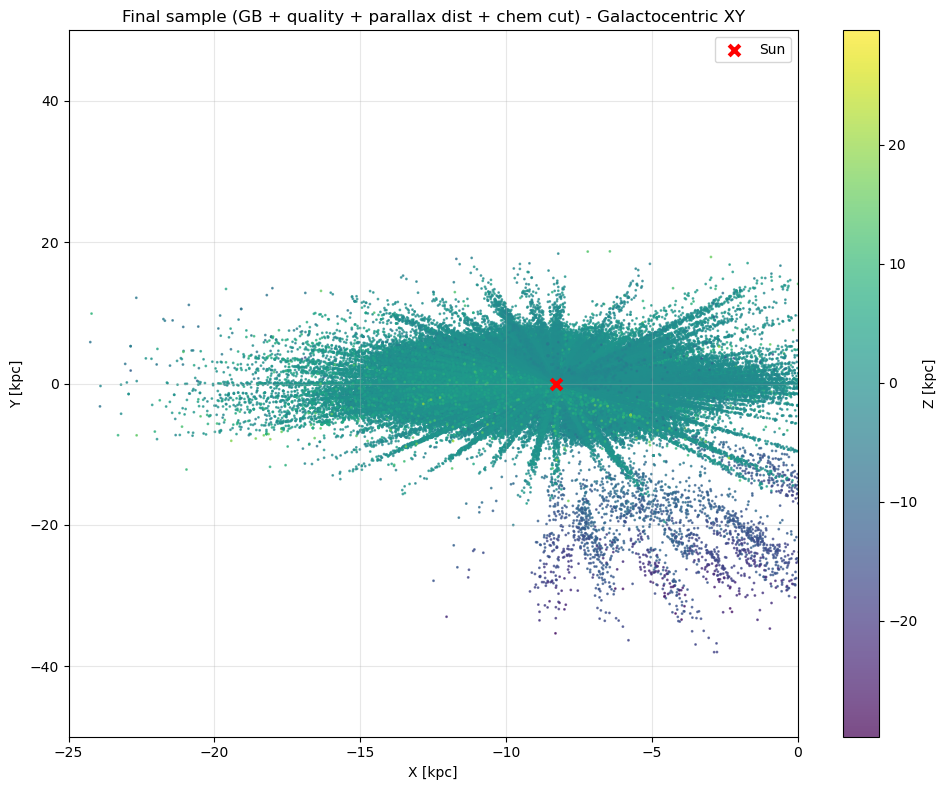

In [15]:
from src.coords import build_galactocentric_xyz
from src.chemistry import apply_low_alpha_cut, FEH_CUT
from src.plotting import plot_xy_colored_by_z

# Build coordinates from pre-chem selected table
x, y, z = build_galactocentric_xyz(t_sel)

# Apply chemistry cut
chem_result = apply_low_alpha_cut(t_sel, x=x, y=y, z=z, feh_cut=FEH_CUT)

t_sel = chem_result["table"]
fe = chem_result["fe"]
mgfe = chem_result["mgfe"]
x_a = chem_result["x"]
y_a = chem_result["y"]
z_a = chem_result["z"]

print(f"After chemistry cut (below alpha & [Fe/H] >= {FEH_CUT}):", len(t_sel))

# Plot final sample
plot_xy_colored_by_z(
    x_a, y_a, z_a,
    title="Final sample (GB + quality + parallax dist + chem cut) - Galactocentric XY"
)

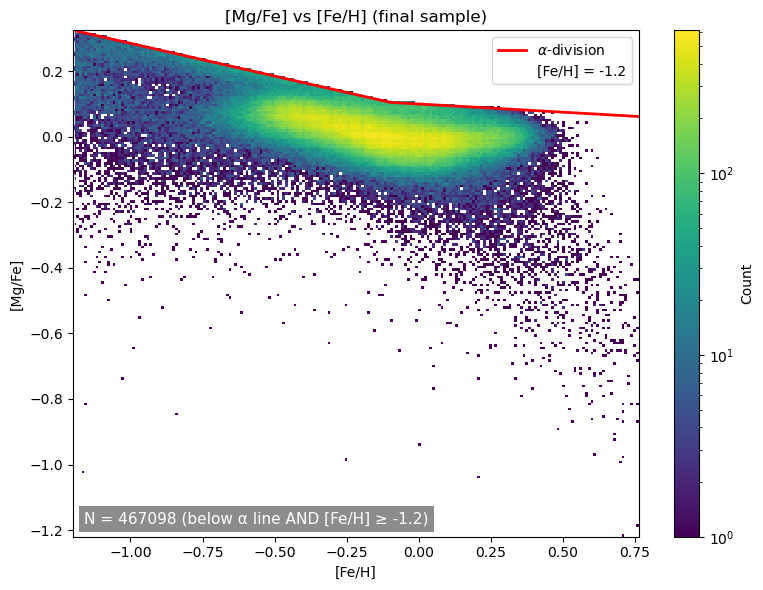

In [16]:
from src.plotting import plot_mgfe_vs_feh
from src.chemistry import mgfe_dividing_line, FEH_CUT

plot_mgfe_vs_feh(
    fe=fe,
    mgfe=mgfe,
    mgfe_dividing_line=mgfe_dividing_line,
    feh_cut=FEH_CUT
)

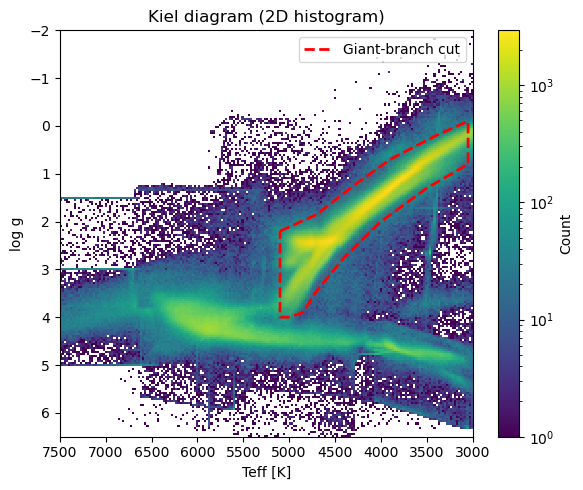

In [17]:
from src.plotting import plot_kiel_diagram
from src.config import GB_VERTICES

plot_kiel_diagram(
    teff=sel_arrays["teff"],
    logg=sel_arrays["logg"],
    finite_basic=np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"]),
    gb_vertices=GB_VERTICES
)

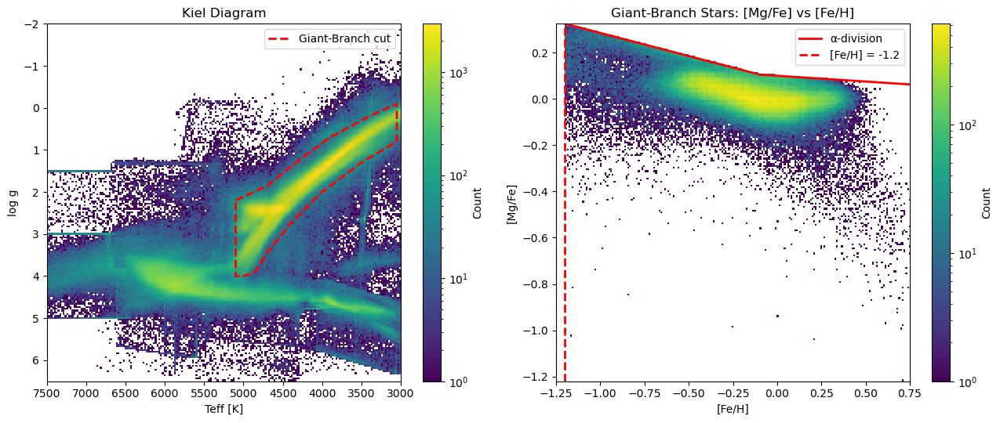

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# ============================================================
# LEFT PANEL: Kiel diagram
# ============================================================
ax = axes[0]

finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]

h1 = ax.hist2d(
    x_all,
    y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")

gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r--", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)

ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.set_title("Kiel Diagram")
ax.legend(loc="upper right")

# ============================================================
# RIGHT PANEL: [Mg/Fe] vs [Fe/H]
# ============================================================
ax = axes[1]

h2 = ax.hist2d(
    fe,
    mgfe,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")

fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")


ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.set_title("Giant-Branch Stars: [Mg/Fe] vs [Fe/H]")
ax.legend(loc="upper right")
ax.set_xlim(-1.25, 0.75) 

plt.tight_layout()
plt.show()

In [21]:
from src.chemistry import apply_alfe_mgmn_polygon_cut

t_final, final_diag, final_arrays = apply_alfe_mgmn_polygon_cut(t_sel)

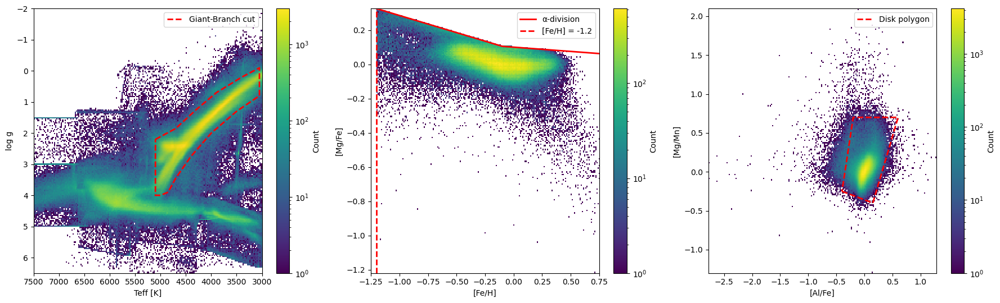

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# ============================================================
# PANEL 1: Kiel diagram
# ============================================================
ax = axes[0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r--", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2: [Mg/Fe] vs [Fe/H]
# ============================================================
ax = axes[1]
h2 = ax.hist2d(
    fe, mgfe,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")
fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.25, 0.75)

# ============================================================
# PANEL 3: [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[2]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r--", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_10087/3130290683.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


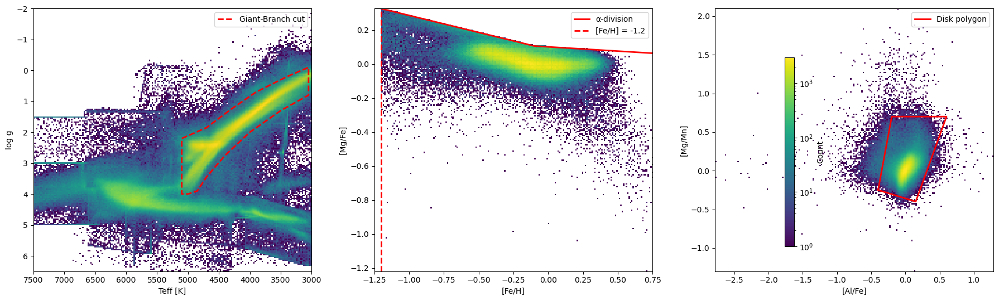

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# ============================================================
# PANEL 1: Kiel diagram
# ============================================================
ax = axes[0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r--", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2: [Mg/Fe] vs [Fe/H]
# ============================================================
ax = axes[1]
h2 = ax.hist2d(
    fe, mgfe,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.25, 0.75)

# ============================================================
# PANEL 3: [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[2]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")

# one shared colorbar
fig.colorbar(h1[3], ax=axes.tolist(), label="Count", shrink=0.8)

plt.tight_layout()
plt.show()

N(t_final): 391560
Have v_rad: 241314
Have VHELIO_AVG: 112209
Have either RV (used): 353522
  using v_rad: 241314
  using VHELIO_AVG fallback: 112208
Dropped (missing BOTH RVs or bad astrometry): 38038
N stars in phase-space maps: 353522


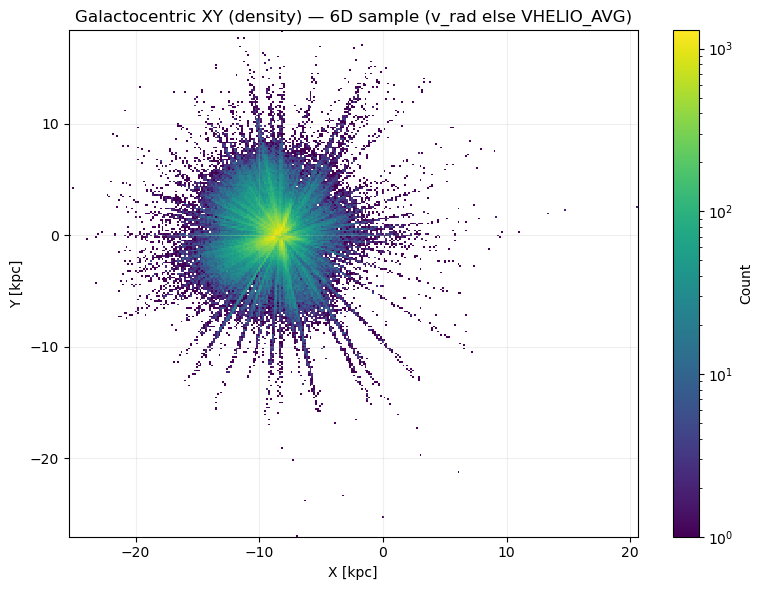

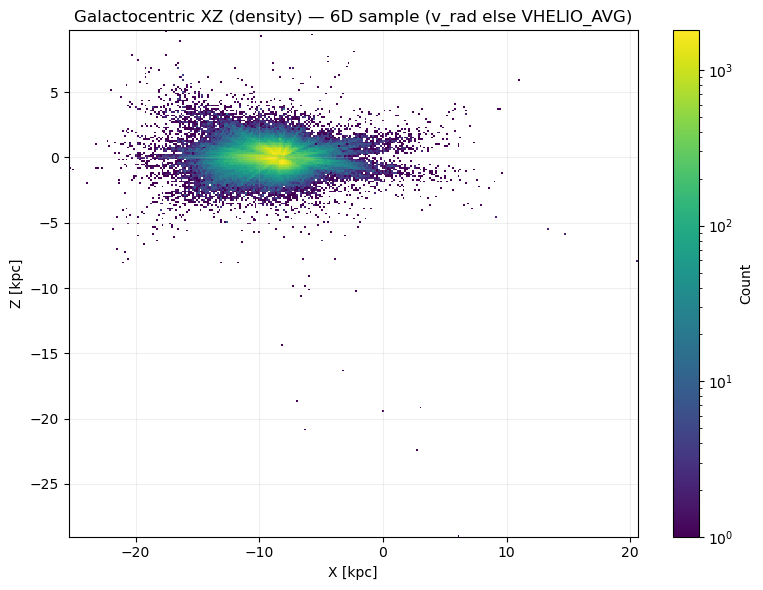

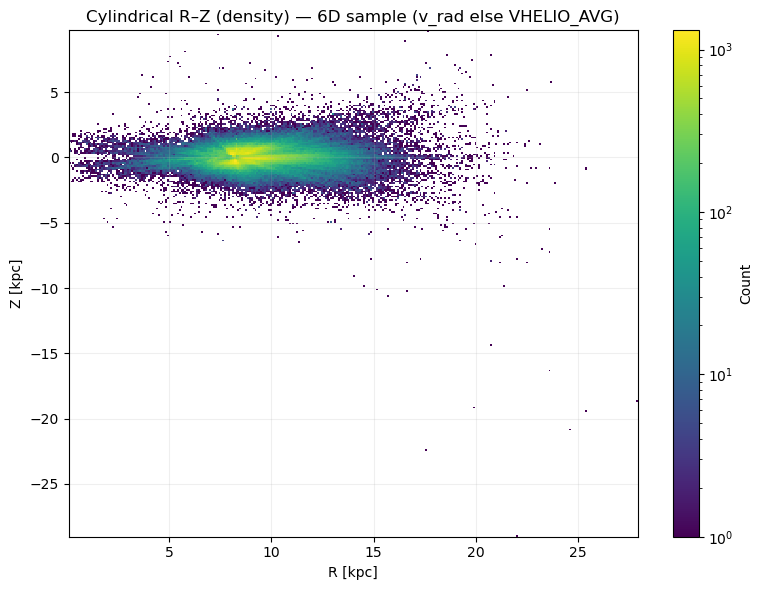

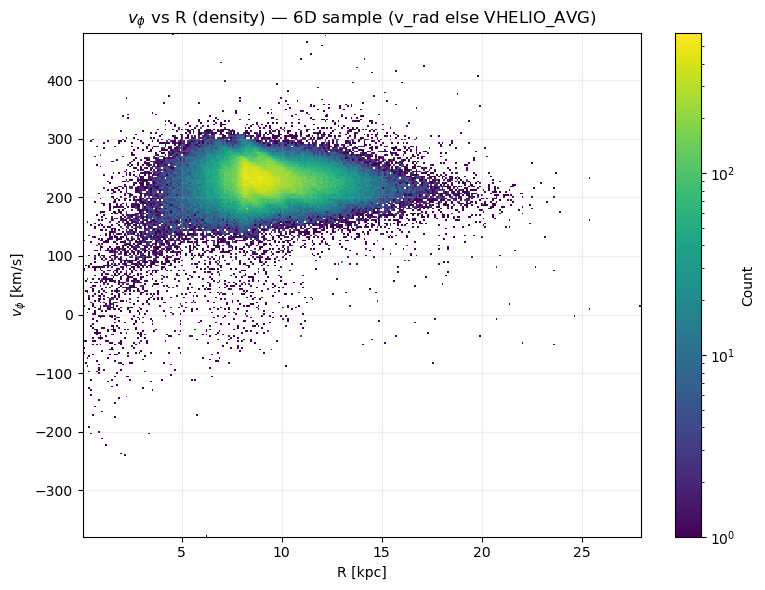

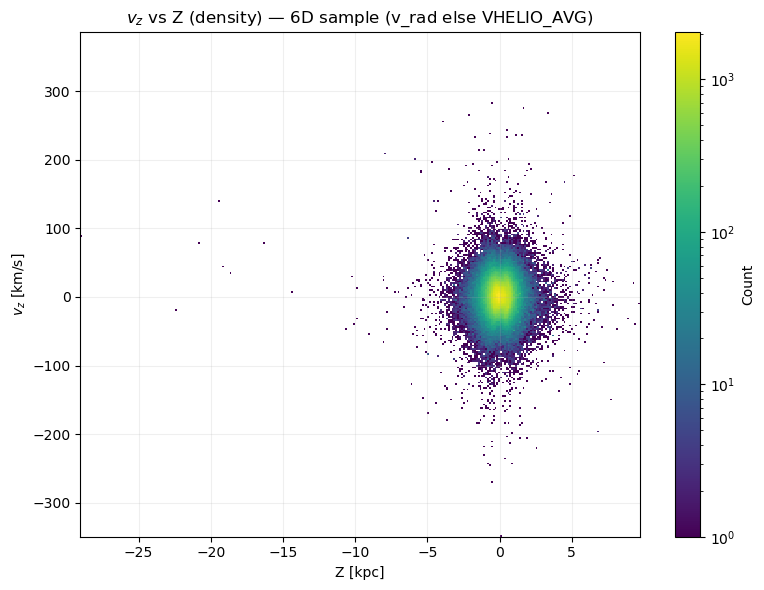

R range [kpc]: 0.05815139938222538 to 27.9500122180219
Z range [kpc]: -29.036534639859834 to 9.723087621420438
Median vphi [km/s]: 228.99589483746533
Median |vz| [km/s]: 12.500386069723945


In [24]:
from src.coords import build_galactocentric_phase_space
from src.plotting import plot_density_2d

phase, phase_diag = build_galactocentric_phase_space(t_final)

print("N(t_final):", phase_diag["input_size"])
print("Have v_rad:", phase_diag["have_vrad"])
print("Have VHELIO_AVG:", phase_diag["have_vhel"])
print("Have either RV (used):", phase_diag["have_either_rv"])
print("  using v_rad:", phase_diag["using_vrad"])
print("  using VHELIO_AVG fallback:", phase_diag["using_vhel_fallback"])
print("Dropped (missing BOTH RVs or bad astrometry):", phase_diag["dropped_before_transform"])
print("N stars in phase-space maps:", phase_diag["phase_space_size"])

X = phase["X"]
Y = phase["Y"]
Z = phase["Z"]
R = phase["R"]
vphi = phase["vphi"]
vz = phase["vz"]

plot_density_2d(
    X, Y,
    xlabel="X [kpc]",
    ylabel="Y [kpc]",
    title="Galactocentric XY (density) — 6D sample (v_rad else VHELIO_AVG)"
)

plot_density_2d(
    X, Z,
    xlabel="X [kpc]",
    ylabel="Z [kpc]",
    title="Galactocentric XZ (density) — 6D sample (v_rad else VHELIO_AVG)"
)

plot_density_2d(
    R, Z,
    xlabel="R [kpc]",
    ylabel="Z [kpc]",
    title="Cylindrical R–Z (density) — 6D sample (v_rad else VHELIO_AVG)"
)

plot_density_2d(
    R, vphi,
    xlabel="R [kpc]",
    ylabel=r"$v_\phi$ [km/s]",
    title=r"$v_\phi$ vs R (density) — 6D sample (v_rad else VHELIO_AVG)"
)

plot_density_2d(
    Z, vz,
    xlabel="Z [kpc]",
    ylabel=r"$v_z$ [km/s]",
    title=r"$v_z$ vs Z (density) — 6D sample (v_rad else VHELIO_AVG)"
)

print("R range [kpc]:", np.nanmin(R), "to", np.nanmax(R))
print("Z range [kpc]:", np.nanmin(Z), "to", np.nanmax(Z))
print("Median vphi [km/s]:", np.nanmedian(vphi))
print("Median |vz| [km/s]:", np.nanmedian(np.abs(vz)))

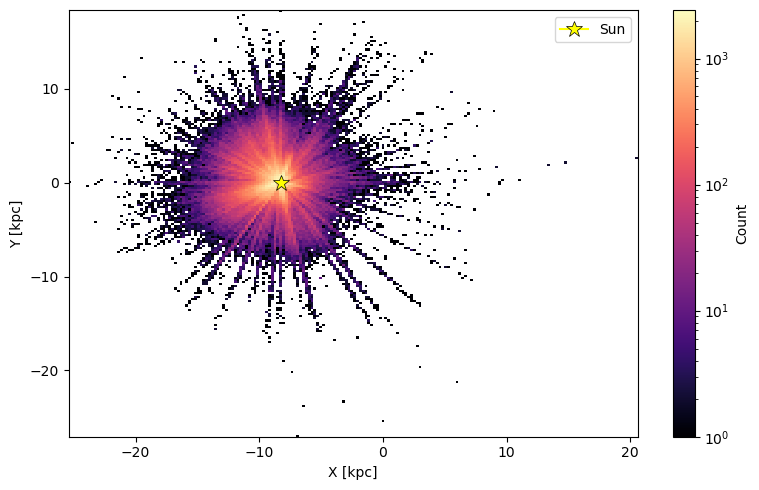

In [25]:
import matplotlib.colors as mcolors

fig, ax = plt.subplots(figsize=(8, 5))

h = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())

ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

fig.colorbar(h[3], ax=ax, label="Count")

ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

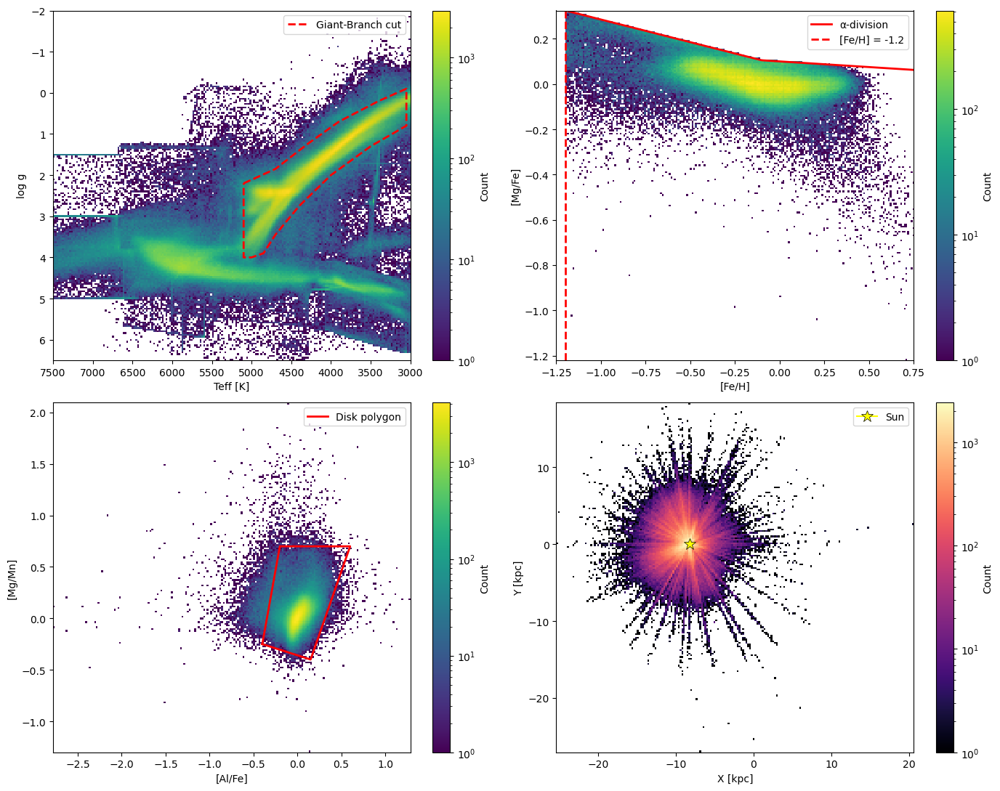

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r--", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H]
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe, mgfe,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")
fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.25, 0.75)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")

# ============================================================
# PANEL 4 (bottom right): XY density
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)
fig.colorbar(h0[3], ax=ax, label="Count")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [27]:
sel_arrays.keys()

dict_keys(['teff', 'logg', 'feh', 'mgh', 'snr', 'ra', 'dec', 'pmra', 'pmde', 'vrad', 'plx'])

In [28]:
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem

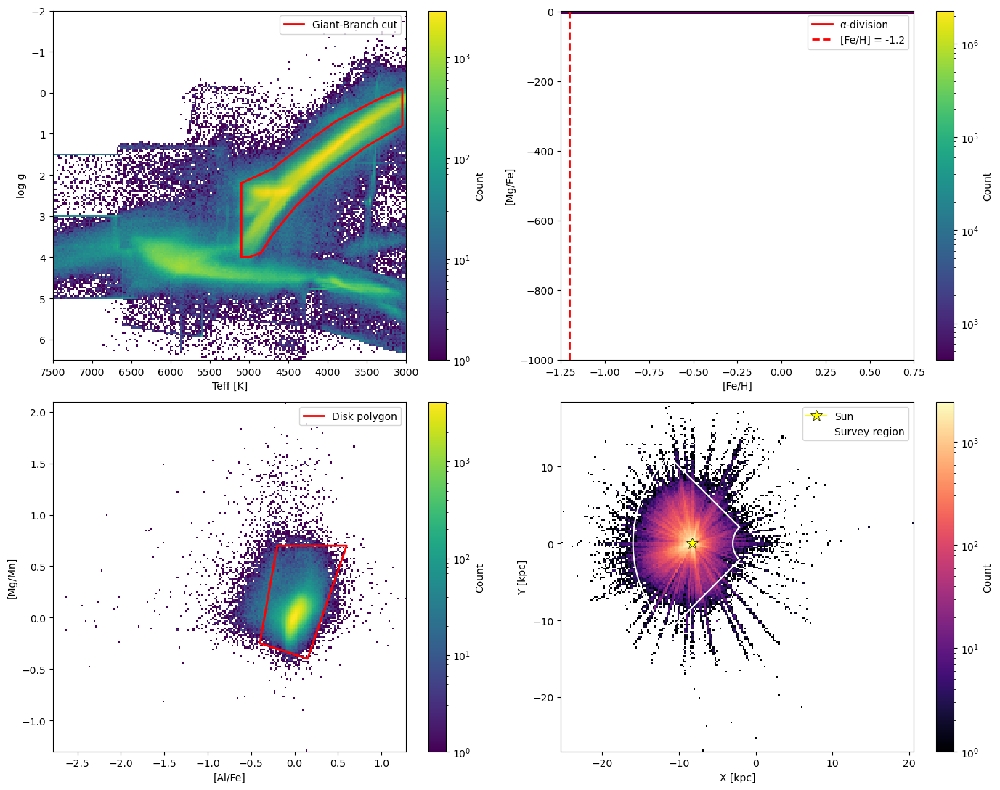

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] — all giant branch stars
# ============================================================
crowd_bounds = np.array([2.35619449, 2.49899416, 2.64179382, 2.78459349, 2.92739315, 
                          3.07019282, 3.21299249, 3.35579215, 3.49859182, 3.64139148, 
                          3.78419115, 3.92699082])
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_prechem[finite_prechem],
    mgfe_prechem[finite_prechem],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")
fe_grid = np.linspace(np.nanmin(fe_prechem[finite_prechem]),
                      np.nanmax(fe_prechem[finite_prechem]), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.25, 0.75)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)
fig.colorbar(h0[3], ax=ax, label="Count")

# wedge outline from crowd_bounds
R_min = 3.0   # kpc
R_max = 16.0  # kpc
crowd_bounds_deg = [135, 225]
theta_min_wed = np.radians(crowd_bounds_deg[0])
theta_max_wed = np.radians(crowd_bounds_deg[1])
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
theta_arc = np.linspace(crowd_bounds[0], crowd_bounds[-1], 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), "w-", lw=1.5)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), "w-", lw=1.5)
ax.plot([R_min * np.cos(crowd_bounds[0]), R_max * np.cos(crowd_bounds[0])],
        [R_min * np.sin(crowd_bounds[0]), R_max * np.sin(crowd_bounds[0])],
        "w-", lw=1.5)
ax.plot([R_min * np.cos(crowd_bounds[-1]), R_max * np.cos(crowd_bounds[-1])],
        [R_min * np.sin(crowd_bounds[-1]), R_max * np.sin(crowd_bounds[-1])],
        "w-", lw=1.5, label="Survey region")

ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [31]:
# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = (
    np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)
    & (fe_prechem > -1.25) & (fe_prechem < 0.75)
    & (mgfe_prechem > -0.4) & (mgfe_prechem < 0.4)
)

In [32]:
# get all giant branch stars for panel 2
from matplotlib.path import Path
gb_path = Path(gb_closed)

teff_all = np.asarray(sel_arrays["teff"], float)
logg_all = np.asarray(sel_arrays["logg"], float)
fe_all = np.asarray(sel_arrays["feh"], float)
mgfe_all = np.asarray(sel_arrays["mgh"], float) - fe_all

finite_all = np.isfinite(teff_all) & np.isfinite(logg_all) & np.isfinite(fe_all) & np.isfinite(mgfe_all)

# apply giant branch cut
in_gb = gb_path.contains_points(np.column_stack([teff_all[finite_all], logg_all[finite_all]]))

fe_gb = fe_all[finite_all][in_gb]
mgfe_gb = mgfe_all[finite_all][in_gb]

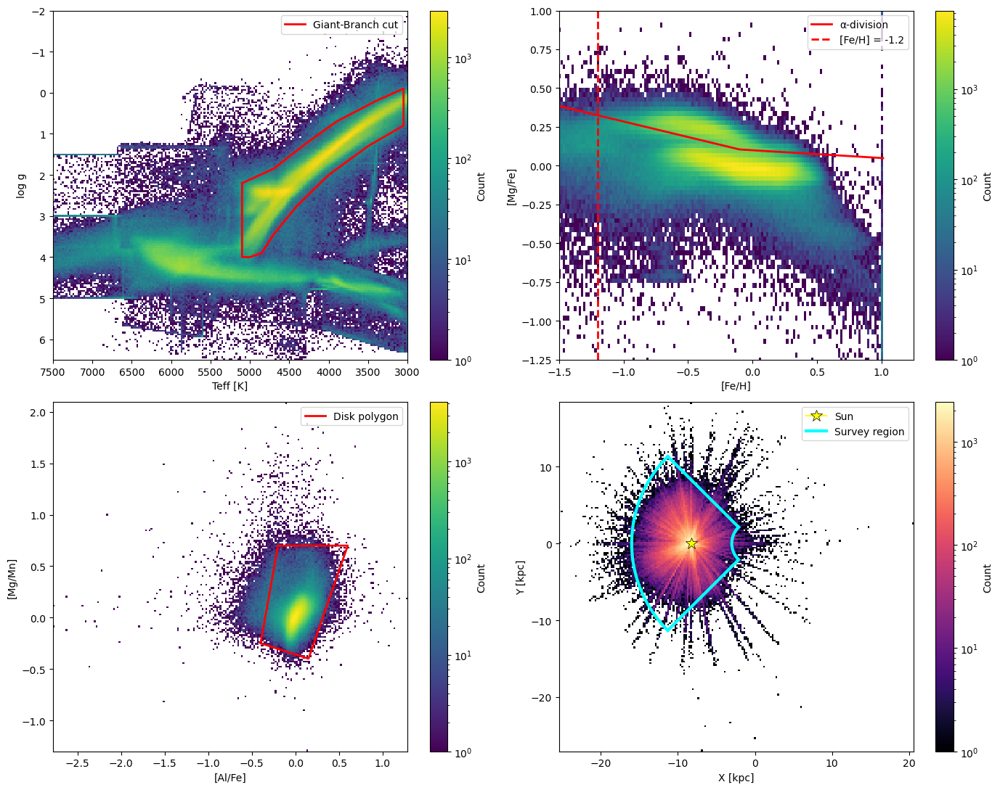

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

# pre-chemistry arrays for panel 2
fe_prechem = np.asarray(sel_arrays["feh"], float)
mgfe_prechem = np.asarray(sel_arrays["mgh"], float) - fe_prechem
finite_prechem = np.isfinite(fe_prechem) & np.isfinite(mgfe_prechem)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]")
ax.set_ylabel("log g")
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] — all giant branch stars
# ============================================================
ax = axes[0, 1]
h2 = ax.hist2d(
    fe_gb, mgfe_gb,
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")
fe_grid = np.linspace(np.nanmin(fe_gb), np.nanmax(fe_gb), 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel("[Mg/Fe]")
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-1.25, 1.0)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]")
ax.set_ylabel("[Mg/Mn]")
ax.legend(loc="upper right")

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
fig.colorbar(h0[3], ax=ax, label="Count")

# sun marker
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

# wedge outline
theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 3.0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)

ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=3)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=3)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=3)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=3,
        label="Survey region")

ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [34]:
master_mask, sel_diag, sel_arrays = build_prechem_selection(t)
t_sel = t[master_mask]

In [35]:
fe_all_gb = np.asarray(t_sel["fe_h"], float)
mgfe_all_gb = np.asarray(t_sel["mg_h"], float) - fe_all_gb

In [36]:
# save pre-chemistry giant branch arrays
fe_all_gb = np.asarray(t_sel["fe_h"], float)
mgfe_all_gb = np.asarray(t_sel["mg_h"], float) - fe_all_gb
finite_all_gb = np.isfinite(fe_all_gb) & np.isfinite(mgfe_all_gb)
print("Pre-chemistry giant branch stars:", finite_all_gb.sum())

Pre-chemistry giant branch stars: 630079


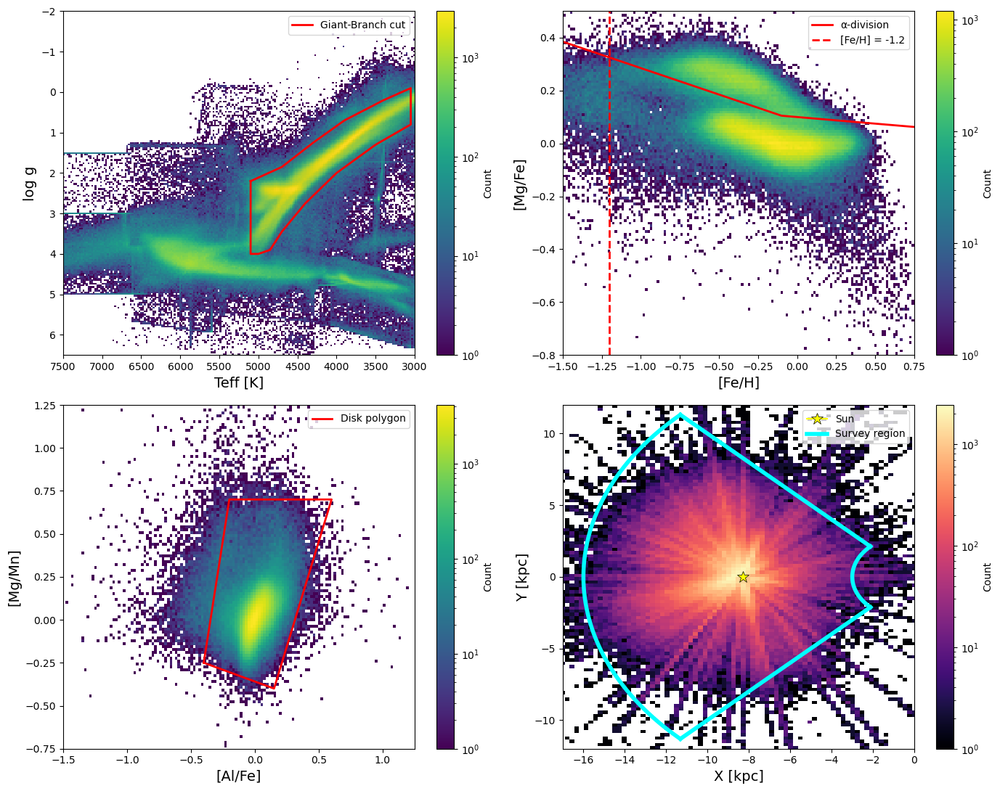

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT
fe_all_gb = np.asarray(t_sel["fe_h"], float)
mgfe_all_gb = np.asarray(t_sel["mg_h"], float) - fe_all_gb
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h1[3], ax=ax, label="Count")
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel("Teff [K]", fontsize=14)
ax.set_ylabel("log g", fontsize=14)
ax.legend(loc="upper right")

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] — all giant branch stars
# ============================================================
ax = axes[0, 1]
fe_p2 = fe_all_gb
mgfe_p2 = mgfe_all_gb
finite_p2 = np.isfinite(fe_p2) & np.isfinite(mgfe_p2)
h2 = ax.hist2d(
    fe_p2[finite_p2], mgfe_p2[finite_p2],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h2[3], ax=ax, label="Count")
fe_grid = np.linspace(-1.5, 1.0, 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.set_xlabel("[Fe/H]", fontsize=14)
ax.set_ylabel("[Mg/Fe]", fontsize=14)
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-0.8, 0.5)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
fig.colorbar(h3[3], ax=ax, label="Count")
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Disk polygon")
ax.set_xlabel("[Al/Fe]", fontsize=14)
ax.set_ylabel("[Mg/Mn]", fontsize=14)
ax.legend(loc="upper right")
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-.75, 1.25)

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
fig.colorbar(h0[3], ax=ax, label="Count")
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=12,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)

theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 3.0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("X [kpc]", fontsize=14)
ax.set_ylabel("Y [kpc]", fontsize=14)
ax.legend(loc="upper right")
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)

plt.tight_layout()
plt.show()

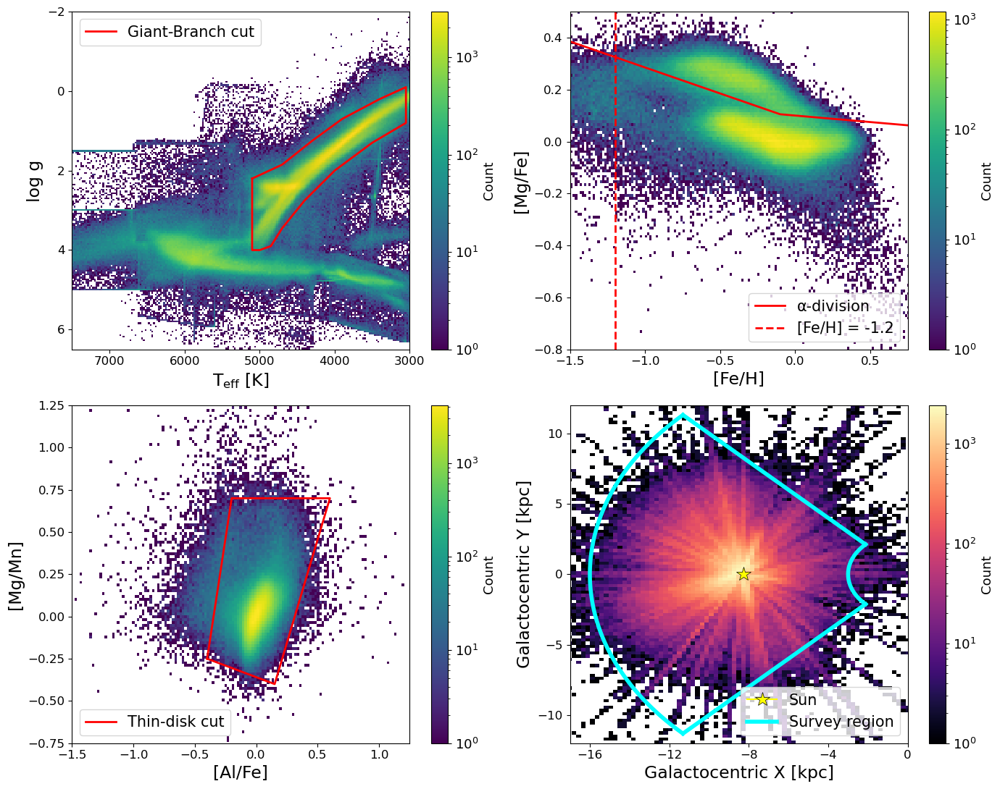

In [54]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fe_all_gb = np.asarray(t_sel["fe_h"], float)
mgfe_all_gb = np.asarray(t_sel["mg_h"], float) - fe_all_gb

plt.rcParams.update({"axes.labelsize": 14, "xtick.labelsize": 12, 
                     "ytick.labelsize": 12, "legend.fontsize": 12})

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
cb1 = fig.colorbar(h1[3], ax=ax)
cb1.set_label("Count", fontsize=13)
cb1.ax.tick_params(labelsize=13)
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.xaxis.set_major_locator(plt.MultipleLocator(1000))
ax.yaxis.set_major_locator(plt.MultipleLocator(2))
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel(r"T$_\mathrm{eff}$ [K]", fontsize = 17)
ax.set_ylabel("log g", fontsize = 17)
ax.legend(loc="upper left", fontsize=15)

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] — all giant branch stars
# ============================================================
ax = axes[0, 1]
fe_p2 = fe_all_gb
mgfe_p2 = mgfe_all_gb
finite_p2 = np.isfinite(fe_p2) & np.isfinite(mgfe_p2)
h2 = ax.hist2d(
    fe_p2[finite_p2], mgfe_p2[finite_p2],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb2 = fig.colorbar(h2[3], ax=ax)
cb2.set_label("Count", fontsize=13)
cb2.ax.tick_params(labelsize=13)
fe_grid = np.linspace(-1.5, 1.0, 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.5))
ax.set_xlabel("[Fe/H]", fontsize = 17)
ax.set_ylabel("[Mg/Fe]", fontsize = 17)
ax.legend(loc="lower right", fontsize=15)
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-0.8, 0.5)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb3 = fig.colorbar(h3[3], ax=ax)
cb3.set_label("Count", fontsize=13)
cb3.ax.tick_params(labelsize=13)
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Thin-disk cut")
ax.set_xlabel("[Al/Fe]", fontsize = 17)
ax.set_ylabel("[Mg/Mn]", fontsize = 17)
ax.legend(loc="lower left", fontsize=15)
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
cb4 = fig.colorbar(h0[3], ax=ax)
cb4.set_label("Count", fontsize=13)
cb4.ax.tick_params(labelsize=13)
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=15,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)
theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 3.0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("Galactocentric X [kpc]", fontsize = 17)
ax.set_ylabel("Galactocentric Y [kpc]", fontsize = 17)
ax.xaxis.set_major_locator(plt.MultipleLocator(4))
ax.legend(loc="lower right", fontsize=15)
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)

plt.tight_layout()
plt.show()

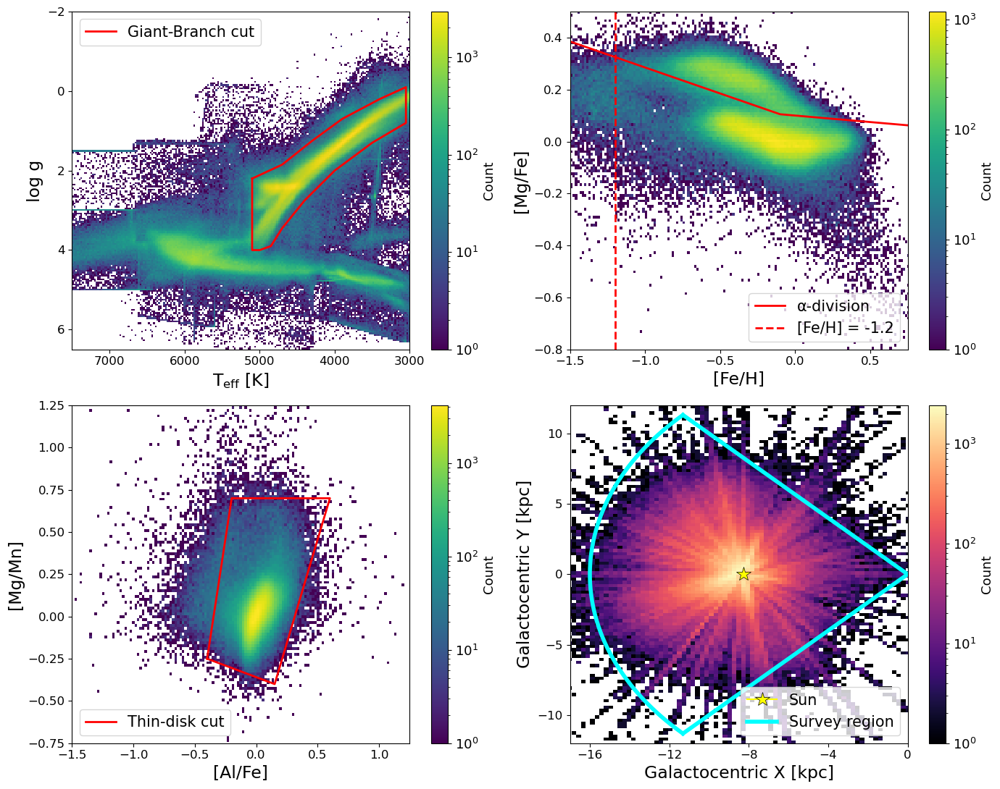

In [55]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from src.config import GB_VERTICES
from src.chemistry import mgfe_dividing_line, FEH_CUT

fe_all_gb = np.asarray(t_sel["fe_h"], float)
mgfe_all_gb = np.asarray(t_sel["mg_h"], float) - fe_all_gb

plt.rcParams.update({"axes.labelsize": 14, "xtick.labelsize": 12, 
                     "ytick.labelsize": 12, "legend.fontsize": 12})

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ============================================================
# PANEL 1 (top left): Kiel diagram
# ============================================================
ax = axes[0, 0]
finite_basic = np.isfinite(sel_arrays["teff"]) & np.isfinite(sel_arrays["logg"])
x_all = np.asarray(sel_arrays["teff"], float)[finite_basic]
y_all = np.asarray(sel_arrays["logg"], float)[finite_basic]
h1 = ax.hist2d(
    x_all, y_all,
    bins=200,
    range=[(3000, 7500), (-2, 6.5)],
    norm=LogNorm(),
    cmap="viridis"
)
cb1 = fig.colorbar(h1[3], ax=ax)
cb1.set_label("Count", fontsize=13)
cb1.ax.tick_params(labelsize=13)
gb_closed = np.vstack([GB_VERTICES, GB_VERTICES[0]])
ax.plot(gb_closed[:, 0], gb_closed[:, 1], "r-", lw=2, label="Giant-Branch cut")
ax.fill(gb_closed[:, 0], gb_closed[:, 1], color="red", alpha=0.06)
ax.invert_xaxis()
ax.invert_yaxis()
ax.xaxis.set_major_locator(plt.MultipleLocator(1000))
ax.yaxis.set_major_locator(plt.MultipleLocator(2))
ax.set_xlim(7500, 3000)
ax.set_ylim(6.5, -2)
ax.set_xlabel(r"T$_\mathrm{eff}$ [K]", fontsize = 17)
ax.set_ylabel("log g", fontsize = 17)
ax.legend(loc="upper left", fontsize=15)

# ============================================================
# PANEL 2 (top right): [Mg/Fe] vs [Fe/H] — all giant branch stars
# ============================================================
ax = axes[0, 1]
fe_p2 = fe_all_gb
mgfe_p2 = mgfe_all_gb
finite_p2 = np.isfinite(fe_p2) & np.isfinite(mgfe_p2)
h2 = ax.hist2d(
    fe_p2[finite_p2], mgfe_p2[finite_p2],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb2 = fig.colorbar(h2[3], ax=ax)
cb2.set_label("Count", fontsize=13)
cb2.ax.tick_params(labelsize=13)
fe_grid = np.linspace(-1.5, 1.0, 400)
ax.plot(fe_grid, mgfe_dividing_line(fe_grid), color="red", lw=2, label="α-division")
ax.axvline(FEH_CUT, color="red", lw=2, ls="--", label=f"[Fe/H] = {FEH_CUT}")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.5))
ax.set_xlabel("[Fe/H]", fontsize = 17)
ax.set_ylabel("[Mg/Fe]", fontsize = 17)
ax.legend(loc="lower right", fontsize=15)
ax.set_xlim(-1.5, 0.75)
ax.set_ylim(-0.8, 0.5)

# ============================================================
# PANEL 3 (bottom left): [Al/Fe] vs [Mg/Mn]
# ============================================================
ax = axes[1, 0]
h3 = ax.hist2d(
    final_arrays["x_finite"],
    final_arrays["y_finite"],
    bins=200,
    norm=LogNorm(),
    cmap="viridis"
)
cb3 = fig.colorbar(h3[3], ax=ax)
cb3.set_label("Count", fontsize=13)
cb3.ax.tick_params(labelsize=13)
poly = np.vstack([final_arrays["poly_vertices"], final_arrays["poly_vertices"][0]])
ax.plot(poly[:, 0], poly[:, 1], "r-", lw=2, label="Thin-disk cut")
ax.set_xlabel("[Al/Fe]", fontsize = 17)
ax.set_ylabel("[Mg/Mn]", fontsize = 17)
ax.legend(loc="lower left", fontsize=15)
ax.set_xlim(-1.5, 1.25)
ax.set_ylim(-0.75, 1.25)

# ============================================================
# PANEL 4 (bottom right): XY density with wedge overlay
# ============================================================
ax = axes[1, 1]
h0 = ax.hist2d(X, Y, bins=200, cmap="magma", norm=mcolors.LogNorm())
cb4 = fig.colorbar(h0[3], ax=ax)
cb4.set_label("Count", fontsize=13)
cb4.ax.tick_params(labelsize=13)
ax.plot(-8.275, 0, marker="*", color="yellow", markersize=15,
        markeredgecolor="k", markeredgewidth=0.5, label="Sun", zorder=5)
theta_min_wed = 2.35619449
theta_max_wed = 3.92699082
R_min = 0
R_max = 16.0
theta_arc = np.linspace(theta_min_wed, theta_max_wed, 200)
ax.plot(R_min * np.cos(theta_arc), R_min * np.sin(theta_arc), color="cyan", lw=4)
ax.plot(R_max * np.cos(theta_arc), R_max * np.sin(theta_arc), color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_min_wed), R_max * np.cos(theta_min_wed)],
        [R_min * np.sin(theta_min_wed), R_max * np.sin(theta_min_wed)], color="cyan", lw=4)
ax.plot([R_min * np.cos(theta_max_wed), R_max * np.cos(theta_max_wed)],
        [R_min * np.sin(theta_max_wed), R_max * np.sin(theta_max_wed)], color="cyan", lw=4,
        label="Survey region")
ax.set_xlabel("Galactocentric X [kpc]", fontsize = 17)
ax.set_ylabel("Galactocentric Y [kpc]", fontsize = 17)
ax.xaxis.set_major_locator(plt.MultipleLocator(4))
ax.legend(loc="lower right", fontsize=15)
ax.set_xlim(-17, 0)
ax.set_ylim(-12, 12)

plt.tight_layout()
plt.show()

In [11]:
print("len(t_final):", phase_diag["input_size"])
print("N stars in phase-space maps:", phase_diag["phase_space_size"])

len(t_final): 391560
N stars in phase-space maps: 353522


Parallax-valid stars: 388970 / 391560
N used for annuli plot: 388970
Stopping: reached 2 consecutive annuli with N < 100 at R~[19.0,19.5)
Plotted 36 annuli (dR=0.5) with minN=100.


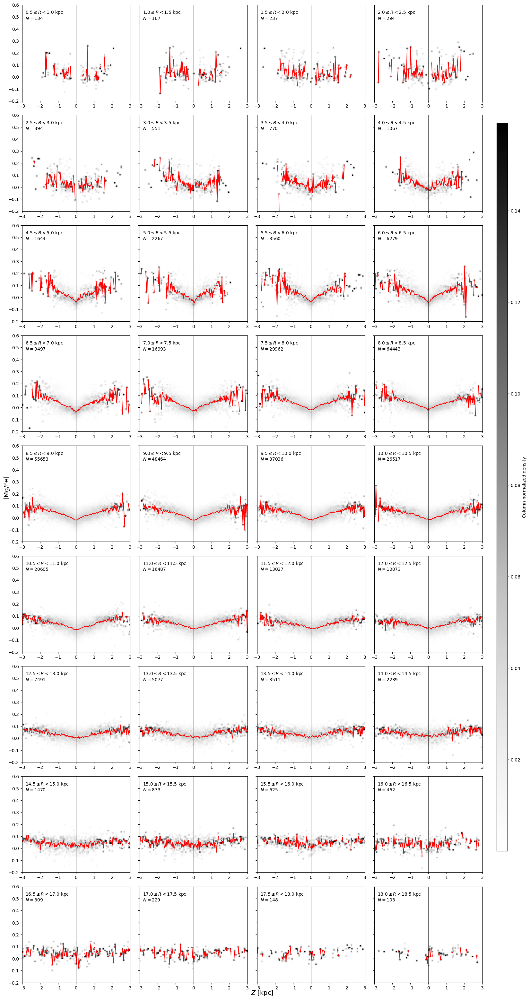

In [12]:
from src.coords import build_annuli_sample_from_table
from src.plotting import plot_annuli_mgfe_vs_z

annuli_sample, annuli_diag = build_annuli_sample_from_table(
    t_final,
    plx_unit="mas",
    plx_snr_min=5.0
)

print("Parallax-valid stars:", annuli_diag["parallax_valid"], "/", annuli_diag["input_size"])
print("N used for annuli plot:", annuli_diag["final_size"])

annuli_result = plot_annuli_mgfe_vs_z(
    R_all=annuli_sample["R_all"],
    Z_all=annuli_sample["Z_all"],
    mgfe_all=annuli_sample["mgfe_all"],
    dR=0.5,
    minN=100,
    stop_after_k_consecutive_lowN=2,
    R_max_plot=None,
    z_edges=np.linspace(-3.0, 3.0, 181),
    mgfe_edges=np.linspace(-0.2, 0.6, 161),
    smooth_sigma=(1.0, 1.0),
    vmin_pct=2.0,
    vmax_pct=99.7,
    cmap_name="Greys",
    ncols=4
)

In [13]:
from src.coords import build_star_pack

star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=16.0,
    plx_min=None
)

print("Input size:", star_diag["input_size"])
print("After parallax cut:", star_diag["after_plx_cut"])
print("After finite cut:", star_diag["after_finite_cut"])
print("Final size:", star_diag["final_size"])

R_star = star_pack["R_star"]
Z_star = star_pack["Z_star"]
phi_star = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]

print("Lengths:", len(R_star), len(Z_star), len(phi_star), len(mgfe_star))
assert len(R_star) == len(mgfe_star) == len(phi_star) == len(Z_star)

Input size: 391560
After parallax cut: 391560
After finite cut: 391560
Final size: 389650
Lengths: 389650 389650 389650 389650


Annulus 13.5–14.0 kpc: Ntot = 3635


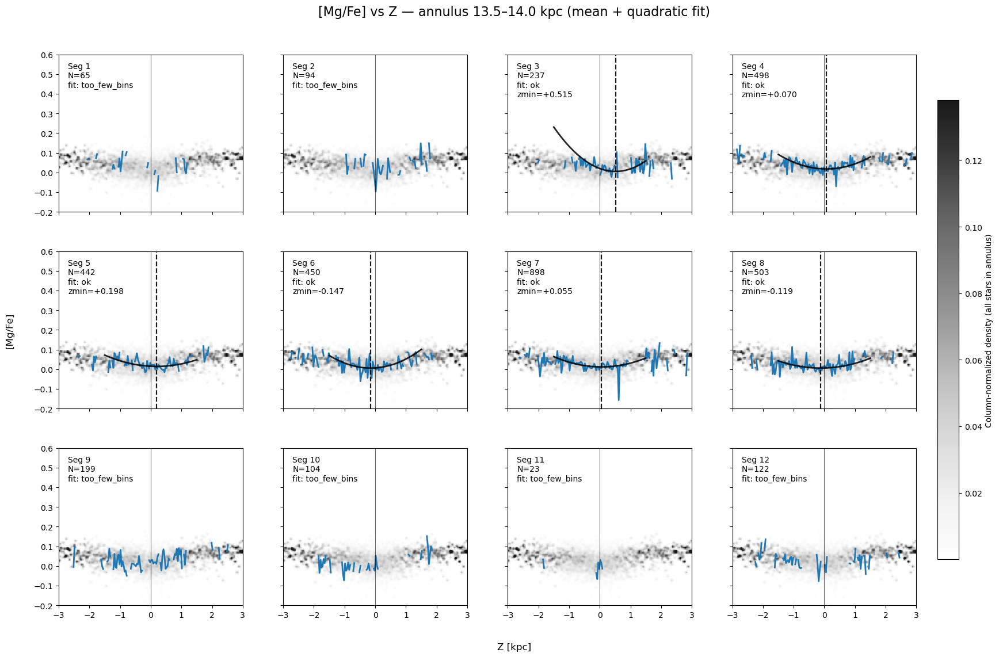

[{'seg_id': 1, 'Nseg': 65, 'status': 'too_few_bins', 'zmin': nan},
 {'seg_id': 2, 'Nseg': 94, 'status': 'too_few_bins', 'zmin': nan},
 {'seg_id': 3, 'Nseg': 237, 'status': 'ok', 'zmin': 0.5154040463566331},
 {'seg_id': 4, 'Nseg': 498, 'status': 'ok', 'zmin': 0.07017583957506525},
 {'seg_id': 5, 'Nseg': 442, 'status': 'ok', 'zmin': 0.1979525732780007},
 {'seg_id': 6, 'Nseg': 450, 'status': 'ok', 'zmin': -0.14709886803647826},
 {'seg_id': 7, 'Nseg': 898, 'status': 'ok', 'zmin': 0.05548139490684916},
 {'seg_id': 8, 'Nseg': 503, 'status': 'ok', 'zmin': -0.11853752659187976},
 {'seg_id': 9, 'Nseg': 199, 'status': 'too_few_bins', 'zmin': nan},
 {'seg_id': 10, 'Nseg': 104, 'status': 'too_few_bins', 'zmin': nan},
 {'seg_id': 11, 'Nseg': 23, 'status': 'too_few_bins', 'zmin': nan},
 {'seg_id': 12, 'Nseg': 122, 'status': 'too_few_bins', 'zmin': nan}]

In [15]:
from src.plotting import plot_single_annulus_segment_fits
z_edges = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
# Choose the annulus you want to inspect
Rmin_focus, Rmax_focus = 13.5, 14.0

# Plot ALL segments including "rest"
SEG_PLOT = list(range(1, seg_diag["n_crowd"] + 2))

segment_results = plot_single_annulus_segment_fits(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,

    Rmin_focus=Rmin_focus,
    Rmax_focus=Rmax_focus,

    z_edges=z_edges,
    mgfe_edges=mgfe_edges,

    seg_plot=SEG_PLOT,

    minN_seg_total=10,
    min_bin_count=5,

    z_fit_min=-1.5,
    z_fit_max=1.5,
    min_bins_for_fit=8,

    smooth_sigma_img=(1.0, 1.0),

    xlim=(-3, 3),
    ylim=(-0.2, 0.6),

    ncols=4,
    cmap="Greys"
)

segment_results

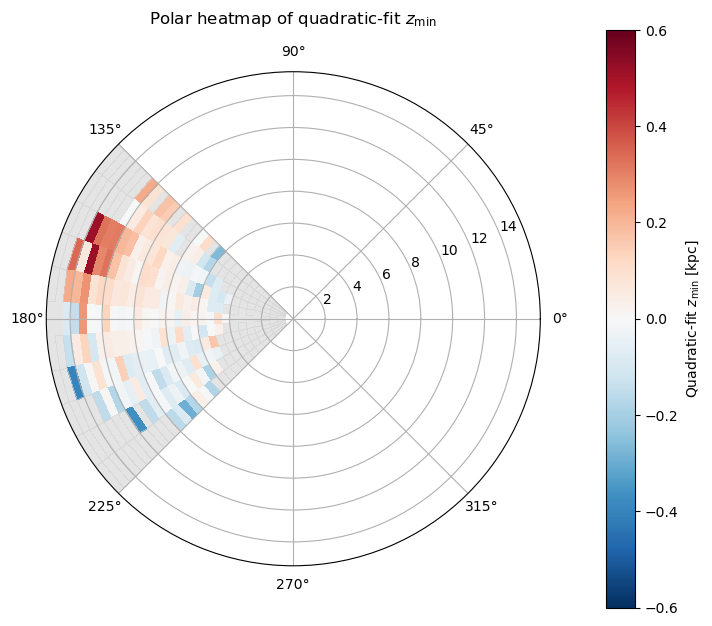

In [16]:
from src.fitting import compute_df_quad, build_zmin_polar_map
from src.plotting import plot_zmin_polar_heatmap

# settings
minN_seg_total = 15
min_bin_count = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8
zlim = 0.6

R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

# compute quadratic-fit midplane table
df_quad = compute_df_quad(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,
    R_edges=R_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit
)

# build polar map
Zmap, theta_edges, R_edges_kept, SEG_PLOT_heat = build_zmin_polar_map(
    df_quad=df_quad,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=seg_diag["seg_rest_id"],
    zlim=zlim
)

# plot
plot_zmin_polar_heatmap(
    Zmap=Zmap,
    theta_edges=theta_edges,
    R_edges_kept=R_edges_kept,
    zlim=zlim
)

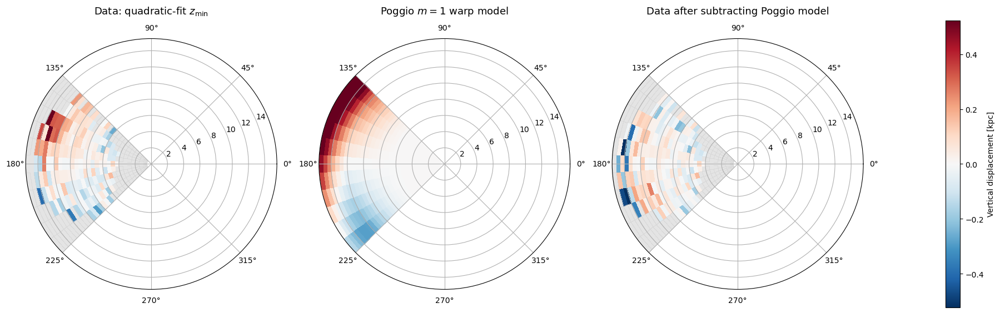

In [17]:
from src.coords import build_star_pack
from src.fitting import compute_df_quad, build_zmin_polar_map, build_model_map
from src.models import poggio_m1_global_Zw
from src.plotting import plot_warp_comparison_3panel

# settings
minN_seg_total = 15
min_bin_count = 5
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 8
zlim = 0.6
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

# build aligned arrays from final sample
star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=None,   # or 16.0 if you want
    plx_min=None
)

R_star = star_pack["R_star"]
Z_star = star_pack["Z_star"]
phi_star = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]

# build wrapped phi for the crowded segment geometry
theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta0 = theta_edges[0]
phi_u = np.full_like(phi_star, np.nan, dtype=float)
mphi = np.isfinite(phi_star)
phi_u[mphi] = ((phi_star[mphi] - theta0) % (2 * np.pi)) + theta0

n_th = len(theta_edges) - 1
SEG_PLOT_heat = list(range(1, n_th + 1))

segm_heat = {}
for j in range(n_th):
    segm_heat[j + 1] = (
        (phi_u >= theta_edges[j]) &
        (phi_u < theta_edges[j + 1]) &
        np.isfinite(phi_u)
    )

# panel 1: data
df_quad_data = compute_df_quad(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm_heat,
    seg_plot=SEG_PLOT_heat,
    z_edges=z_edges,
    R_edges=R_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit
)

Zmap_data, theta_edges_plot, R_edges_plot_data, SEG_PLOT_heat = build_zmin_polar_map(
    df_quad=df_quad_data,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT_heat,
    seg_rest_id=None,
    zlim=zlim
)

# panel 2: model
Zmap_model, df_warp, R_edges_plot_model = build_model_map(
    R_all=R_star,
    phi_u=phi_u,
    segm=segm_heat,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges
)

# panel 3: data - model
Zw_star = np.full_like(Z_star, np.nan, dtype=float)
ok_warp = np.isfinite(R_star) & np.isfinite(phi_u) & np.isfinite(Z_star)
Zw_star[ok_warp] = poggio_m1_global_Zw(R_star[ok_warp], phi_u[ok_warp])

Z_corr = np.full_like(Z_star, np.nan, dtype=float)
Z_corr[ok_warp] = Z_star[ok_warp] - Zw_star[ok_warp]

df_quad_sub = compute_df_quad(
    R_star=R_star,
    Z_star=Z_corr,
    mgfe_star=mgfe_star,
    segm=segm_heat,
    seg_plot=SEG_PLOT_heat,
    z_edges=z_edges,
    R_edges=R_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit
)

Zmap_sub, _, R_edges_plot_sub, _ = build_zmin_polar_map(
    df_quad=df_quad_sub,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT_heat,
    seg_rest_id=None,
    zlim=zlim
)

# optional safety check
if not (
    np.allclose(R_edges_plot_data, R_edges_plot_model) and
    np.allclose(R_edges_plot_data, R_edges_plot_sub)
):
    raise RuntimeError("Radial edges do not match between panels.")

# plot
plot_warp_comparison_3panel(
    Zmap_data=Zmap_data,
    Zmap_model=Zmap_model,
    Zmap_sub=Zmap_sub,
    theta_edges=theta_edges_plot,
    R_edges_plot=R_edges_plot_data,
    zlim=zlim
)

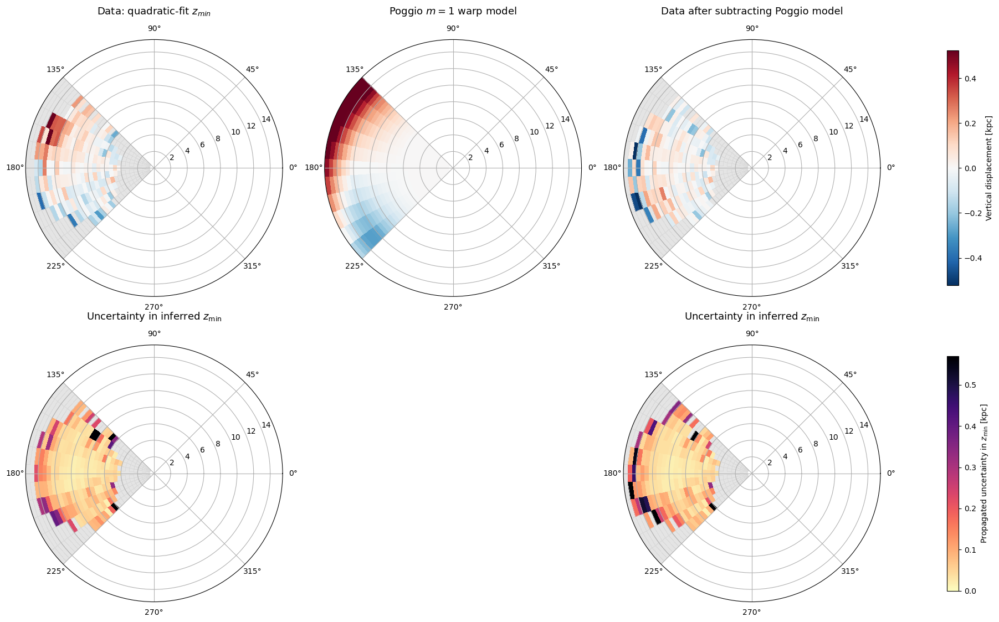

In [18]:
import numpy as np

from src.utils import col_to_float_array
from src.coords import build_star_pack, build_segment_setup
from src.fitting import (
    compute_df_quad,
    build_zmin_polar_map,
    build_model_map,
    build_quad_measerr_only_emap,
)
from src.models import poggio_m1_global_Zw
from src.plotting import plot_warp_comparison_2x3

star_pack, star_diag = build_star_pack(
    t_final,
    rmax_keep=16,   
    plx_min=None
)

R_star = star_pack["R_star"]
Z_star = star_pack["Z_star"]
phi_star = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]
t_star = star_pack["t_star"]
segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star,
    phi0=np.pi,
    crowd_halfwidth_deg=45,
    n_crowd=11
)

SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")

assert len(R_star) == len(Z_star) == len(phi_star) == len(mgfe_star)
assert len(R_star) == len(e_mg_h_star) == len(e_fe_h_star)
assert len(R_star) == len(segm[1])
z_edges = np.linspace(-3.0, 3.0, 181)
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
R_edges_kept = np.asarray(R_edges, float)

minN_seg_total = 15
min_bin_count = 5
min_bins_for_fit = 8

z_fit_min, z_fit_max = -1.5, 1.5
zlim = 0.6

df_quad_data = compute_df_quad(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT_heat,
    z_edges=z_edges,
    R_edges=R_edges_kept,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit
)

Zmap_data, theta_edges, R_edges_plot_data, SEG_PLOT_heat_used = build_zmin_polar_map(
    df_quad=df_quad_data,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT_heat,
    seg_rest_id=None,
    zlim=zlim
)


theta_edges = np.unwrap(np.array(crowd_bounds, float))
for i in range(1, len(theta_edges)):
    while theta_edges[i] <= theta_edges[i - 1]:
        theta_edges[i] += 2 * np.pi

theta0 = theta_edges[0]
phi_u = np.full_like(phi_star, np.nan, dtype=float)
mphi = np.isfinite(phi_star)
phi_u[mphi] = ((phi_star[mphi] - theta0) % (2 * np.pi)) + theta0

segm_heat = {}
for j in range(len(theta_edges) - 1):
    segm_heat[j + 1] = (
        (phi_u >= theta_edges[j]) &
        (phi_u < theta_edges[j + 1]) &
        np.isfinite(phi_u)
    )

Zmap_model, df_warp, R_edges_plot_model = build_model_map(
    R_all=R_star,
    phi_u=phi_u,
    segm=segm_heat,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept
)

Zw_star = np.full_like(Z_star, np.nan, dtype=float)
ok_warp = np.isfinite(R_star) & np.isfinite(phi_u) & np.isfinite(Z_star)
Zw_star[ok_warp] = poggio_m1_global_Zw(R_star[ok_warp], phi_u[ok_warp])

Z_corr = np.full_like(Z_star, np.nan, dtype=float)
Z_corr[ok_warp] = Z_star[ok_warp] - Zw_star[ok_warp]

df_quad_sub = compute_df_quad(
    R_star=R_star,
    Z_star=Z_corr,
    mgfe_star=mgfe_star,
    segm=segm_heat,
    seg_plot=SEG_PLOT_heat,
    z_edges=z_edges,
    R_edges=R_edges_kept,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit
)

Zmap_sub, theta_edges_sub, R_edges_plot_sub, SEG_PLOT_heat_sub = build_zmin_polar_map(
    df_quad=df_quad_sub,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT_heat,
    seg_rest_id=None,
    zlim=zlim
)


Emap_data, df_err_data, R_edges_plot_err_data = build_quad_measerr_only_emap(
    R_use=R_star,
    Z_use=Z_star,
    mgfe_use=mgfe_star,
    e_mg_h_use=e_mg_h_star,
    e_fe_h_use=e_fe_h_star,
    segm=segm,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim,
)

Emap_sub, df_err_sub, R_edges_plot_err_sub = build_quad_measerr_only_emap(
    R_use=R_star,
    Z_use=Z_corr,
    mgfe_use=mgfe_star,
    e_mg_h_use=e_mg_h_star,
    e_fe_h_use=e_fe_h_star,
    segm=segm_heat,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    zlim=zlim,
)

if not (
    np.allclose(R_edges_plot_data, R_edges_plot_model) and
    np.allclose(R_edges_plot_data, R_edges_plot_sub) and
    np.allclose(R_edges_plot_data, R_edges_plot_err_data) and
    np.allclose(R_edges_plot_data, R_edges_plot_err_sub)
):
    raise RuntimeError("Radial edges do not match between panels.")

plot_warp_comparison_2x3(
    Zmap_data=Zmap_data,
    Zmap_model=Zmap_model,
    Zmap_sub=Zmap_sub,
    Emap_data=Emap_data,
    Emap_sub=Emap_sub,
    theta_edges=theta_edges,
    R_edges_plot=R_edges_plot_data,
    zlim=zlim
)

## sech2/GMM

Stars in fit window: 2390
Bins with >= 5 stars: 70


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_3727/2117389588.py:125: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


         mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
A1     -0.021  0.012  -0.051   -0.007      0.001    0.001     233.0     185.0   
A2     -0.071  0.021  -0.105   -0.024      0.002    0.002     228.0     180.0   
h1      0.331  0.202   0.150    0.730      0.015    0.009     209.0     383.0   
d_h2    1.084  0.283   0.554    1.499      0.013    0.010     535.0     607.0   
z0      0.057  0.030   0.001    0.108      0.002    0.001     295.0     702.0   
offset  0.087  0.014   0.061    0.113      0.001    0.000     392.0     593.0   

        r_hat  
A1       1.01  
A2       1.01  
h1       1.01  
d_h2     1.00  
z0       1.00  
offset   1.00  

z_min (z0) posterior median : +0.0544 kpc
z_min 68% CI               : [+0.0253, +0.0886] kpc


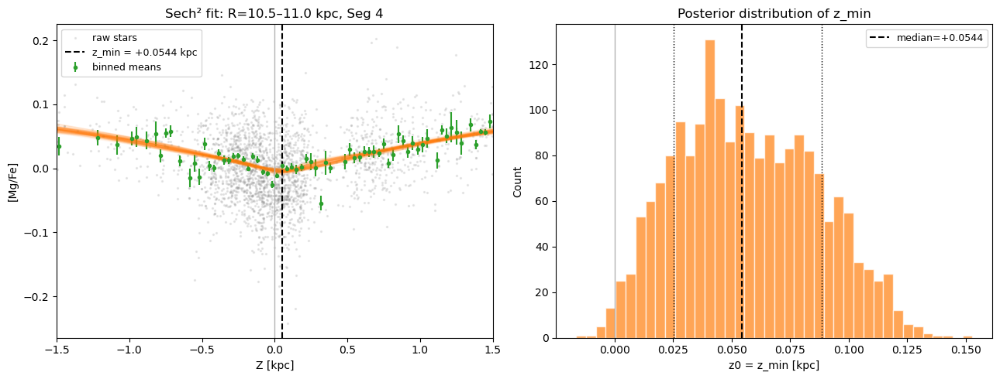

  [20/360] R=1.0-1.5, seg=8
  [40/360] R=2.0-2.5, seg=4
  [60/360] R=2.5-3.0, seg=12


/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_3727/2117389588.py:125: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  [80/360] R=3.5-4.0, seg=8
  [100/360] R=4.5-5.0, seg=4
  [120/360] R=5.0-5.5, seg=12
  [140/360] R=6.0-6.5, seg=8
  [160/360] R=7.0-7.5, seg=4
  [180/360] R=7.5-8.0, seg=12
  [200/360] R=8.5-9.0, seg=8
  [220/360] R=9.5-10.0, seg=4
  [240/360] R=10.0-10.5, seg=12
  [260/360] R=11.0-11.5, seg=8
  [280/360] R=12.0-12.5, seg=4
  [300/360] R=12.5-13.0, seg=12
  [320/360] R=13.5-14.0, seg=8
  [340/360] R=14.5-15.0, seg=4
  [360/360] R=15.0-15.5, seg=12
status_sech2
ok                             210
too_few_bins                   102
too_few_stars                   45
too_few_stars_in_fit_window      3
Name: count, dtype: int64


In [44]:
"""
Mixture-of-sech² midplane fitting via numpyro NUTS-MCMC
Follows Emma's demo approach closely.

Key difference from v1: the model includes a z0 (center shift) parameter
so the sech² dip is not forced to be at z=0. The midplane is then just
the posterior on z0.

Paste each section as a cell in your notebook.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

import jax
import jax.numpy as jnp
import jax.random as jr

import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer
import arviz as az

jax.config.update("jax_enable_x64", True)


# ============================================================
# SECTION 1: model — identical structure to Emma's demo
# but with z0 shift so the minimum is a free parameter
# ============================================================

def mixture_of_sech2(z, A1, A2, h1, h2, z0, offset):
    """
    Y(z) = A1*sech²((z-z0)/h1) + A2*sech²((z-z0)/h2) + offset

    z0 shifts the centre of the dip away from z=0.
    The minimum of this model is at z = z0 by construction.
    We put a prior on z0 centred at 0 with some width,
    and the data pulls it to wherever the actual dip is.
    """
    dz = z - z0
    return (
        A1 * (1.0 / jnp.cosh(dz / h1)) ** 2
        + A2 * (1.0 / jnp.cosh(dz / h2)) ** 2
        + offset
    )



def sech2_model(data):
    # Amplitudes: still negative (dips), but bounded below
    A1 = numpyro.sample("A1", dist.TruncatedNormal(-0.1, 0.15, low=-0.6, high=0.0))
    A2 = numpyro.sample("A2", dist.TruncatedNormal(-0.1, 0.15, low=-0.6, high=0.0))

    # Scale heights: force physically plausible widths
    h1   = numpyro.sample("h1",   dist.Uniform(0.15, 0.8))   # was 0.05–1.0
    d_h2 = numpyro.sample("d_h2", dist.Uniform(0.15, 1.5))   # was 0.05–1.5
    h2   = h1 + d_h2

    # Tighter midplane prior
    z0     = numpyro.sample("z0",     dist.Normal(0.0, 0.1))  # was 0.3
    offset = numpyro.sample("offset", dist.Normal(0.0, 0.2))  # was 0.5

    model_y = mixture_of_sech2(data["z"], A1, A2, h1, h2, z0, offset)
    numpyro.sample("obs", dist.Normal(model_y, data["mgfe_err"]), obs=data["mgfe"])

# ============================================================
# SECTION 2: bin the data — same as Emma's demo
# ============================================================

def bin_data(Zs, MgFes, MgFe_errs, z_edges, min_bin_count=5):
    """
    Bin stars into z_edges, compute inverse-variance weighted mean
    and combined uncertainty per bin.

    Returns z_binc, mean_mgfe, err_mgfe for bins with >= min_bin_count stars.
    """
    z_binc = 0.5 * (z_edges[:-1] + z_edges[1:])
    n_bins = len(z_binc)

    mean_mgfe = np.full(n_bins, np.nan)
    err_mgfe  = np.full(n_bins, np.nan)
    counts    = np.zeros(n_bins, dtype=int)

    iVs  = 1.0 / np.clip(MgFe_errs, 1e-4, None) ** 2
    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok   = (inds >= 0) & (inds < n_bins)

    for i in range(n_bins):
        m = ok & (inds == i)
        counts[i] = np.sum(m)
        if counts[i] < min_bin_count:
            continue
        iV_sum        = np.sum(iVs[m])
        mean_mgfe[i]  = np.sum(iVs[m] * MgFes[m]) / iV_sum
        meas_err      = np.sqrt(1.0 / iV_sum)
        scatter       = np.std(MgFes[m]) / np.sqrt(counts[i])
        err_mgfe[i]   = np.sqrt(meas_err**2 + scatter**2)

    good = np.isfinite(mean_mgfe) & np.isfinite(err_mgfe) & (counts >= min_bin_count)
    return z_binc[good], mean_mgfe[good], err_mgfe[good]


# ============================================================
# SECTION 3: run MCMC — same as Emma's demo
# ============================================================

def run_mcmc(z_binc, mean_mgfe, err_mgfe, rng_key,
             num_warmup=1000, num_samples=1000, num_chains=2):
    """
    Run NUTS on binned data. Returns (samples, idata, status).
    """
    if len(z_binc) < 6:
        return None, None, "too_few_bins"

    data = {
        "z":        jnp.array(z_binc),
        "mgfe":     jnp.array(mean_mgfe),
        "mgfe_err": jnp.array(np.clip(err_mgfe, 1e-4, None)),
    }

    try:
        sampler = infer.MCMC(
            infer.NUTS(sech2_model),
            num_warmup=num_warmup,
            num_samples=num_samples,
            num_chains=num_chains,
            progress_bar=False,
        )
        sampler.run(rng_key, data=data)
        samples = sampler.get_samples()
        idata   = az.from_numpyro(sampler)
        return samples, idata, "ok"
    except Exception as e:
        return None, None, f"mcmc_failed: {e}"


# ============================================================
# SECTION 4: loop over all (annulus, segment) pairs
# ============================================================

def compute_df_sech2(
    R_star, Z_star, mgfe_star,
    e_mg_h_star, e_fe_h_star,
    segm, seg_plot, z_edges,
    R_edges=None,
    minN_seg_total=20,
    min_bin_count=5,
    z_fit_min=-1.5, z_fit_max=1.5,
    num_warmup=1000, num_samples=1000, num_chains=2,
    rng_seed=0,
    z0_prior_width=0.3,   # controls how far z0 can stray from 0
):
    """
    Fit the sech² model for every (annulus, segment).
    z_min is just the posterior on z0.

    Returns dataframe with columns:
        Rmin, Rmax, seg, Nseg
        z_min_sech2        - posterior median of z0
        z_min_sech2_lo     - 16th percentile
        z_min_sech2_hi     - 84th percentile
        z_min_sech2_std    - posterior std of z0
        status_sech2
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    e_mgfe_star = np.clip(np.sqrt(
        np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2
    ), 1e-4, None)

    # z_edges clipped to fit window
    fit_edges = z_edges[(z_edges >= z_fit_min) & (z_edges <= z_fit_max)]

    key   = jr.PRNGKey(rng_seed)
    rows  = []
    total = (len(R_edges) - 1) * len(seg_plot)
    done  = 0

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])
        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            done += 1
            if done % 20 == 0:
                print(f"  [{done}/{total}] R={Rmin_focus:.1f}-{Rmax_focus:.1f}, seg={seg_id}")

            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star) & np.isfinite(e_mgfe_star)
            Nseg = int(np.sum(good))

            def _reject(reason):
                rows.append(dict(
                    Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id), Nseg=Nseg,
                    z_min_sech2=np.nan, z_min_sech2_lo=np.nan,
                    z_min_sech2_hi=np.nan, z_min_sech2_std=np.nan,
                    status_sech2=reason,
                ))

            if Nseg < minN_seg_total:
                _reject("too_few_stars"); continue

            Zs    = Z_star[good]
            MgFes = mgfe_star[good]
            Errs  = e_mgfe_star[good]

            infit = (Zs >= z_fit_min) & (Zs <= z_fit_max)
            Zs, MgFes, Errs = Zs[infit], MgFes[infit], Errs[infit]

            if len(Zs) < minN_seg_total:
                _reject("too_few_stars_in_fit_window"); continue

            z_binc, mean_mgfe, err_mgfe = bin_data(
                Zs, MgFes, Errs, fit_edges, min_bin_count=min_bin_count
            )

            if len(z_binc) < 6:
                _reject("too_few_bins"); continue

            key, subkey = jr.split(key)
            samples, idata, status = run_mcmc(
                z_binc, mean_mgfe, err_mgfe, subkey,
                num_warmup=num_warmup,
                num_samples=num_samples,
                num_chains=num_chains,
            )

            if status != "ok":
                _reject(status); continue

            # z_min IS z0 — no argmin needed
            z0_draws = np.array(samples["z0"])

            rows.append(dict(
                Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id), Nseg=Nseg,
                z_min_sech2=float(np.median(z0_draws)),
                z_min_sech2_lo=float(np.percentile(z0_draws, 16)),
                z_min_sech2_hi=float(np.percentile(z0_draws, 84)),
                z_min_sech2_std=float(np.std(z0_draws)),
                status_sech2="ok",
            ))

    return pd.DataFrame(rows)


# ============================================================
# SECTION 5: build polar map
# ============================================================

def build_sech2_polar_map(df_sech2, crowd_bounds, seg_plot,
                           seg_rest_id=None, zlim=0.6):
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_sech2["Rmin"].tolist() + df_sech2["Rmax"].tolist())), float
    )

    n_r  = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)
    Zmap = np.full((n_r, n_th), np.nan)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    for _, row in df_sech2.loc[df_sech2["status_sech2"] == "ok"].iterrows():
        seg  = int(row["seg"])
        zmin = float(row["z_min_sech2"])
        if seg not in seg_to_col or not np.isfinite(zmin):
            continue
        ir = np.searchsorted(R_edges_kept, float(row["Rmin"]), side="right") - 1
        if 0 <= ir < n_r and abs(zmin) <= zlim:
            Zmap[ir, seg_to_col[seg]] = zmin

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat


# ============================================================
# SECTION 6: diagnostic plot for one (annulus, segment)
# — same style as Emma's demo
# ============================================================

def plot_sech2_single(
    R_star, Z_star, mgfe_star,
    e_mg_h_star, e_fe_h_star,
    segm, Rmin_focus, Rmax_focus, seg_id,
    z_edges,
    z_fit_min=-1.5, z_fit_max=1.5,
    min_bin_count=5,
    num_warmup=1000, num_samples=1000, num_chains=2,
    rng_seed=0, n_posterior_draws=100,
):
    e_mgfe_star = np.clip(np.sqrt(
        np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2
    ), 1e-4, None)

    mR   = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
    mseg = mR & segm[seg_id]
    good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star) & np.isfinite(e_mgfe_star)

    Zs, MgFes, Errs = Z_star[good], mgfe_star[good], e_mgfe_star[good]
    infit = (Zs >= z_fit_min) & (Zs <= z_fit_max)
    Zs, MgFes, Errs = Zs[infit], MgFes[infit], Errs[infit]
    print(f"Stars in fit window: {len(Zs)}")

    fit_edges = z_edges[(z_edges >= z_fit_min) & (z_edges <= z_fit_max)]
    z_binc, mean_mgfe, err_mgfe = bin_data(Zs, MgFes, Errs, fit_edges, min_bin_count)
    print(f"Bins with >= {min_bin_count} stars: {len(z_binc)}")

    if len(z_binc) < 6:
        print("Too few bins — try reducing min_bin_count")
        return None, None, "too_few_bins"

    samples, idata, status = run_mcmc(
        z_binc, mean_mgfe, err_mgfe,
        jr.PRNGKey(rng_seed),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=num_chains,
    )

    if status != "ok":
        print(f"MCMC failed: {status}")
        return None, None, status

    print(az.summary(idata, var_names=["A1", "A2", "h1", "d_h2", "z0", "offset"]))

    z0_draws = np.array(samples["z0"])
    z0_med   = float(np.median(z0_draws))
    z0_lo    = float(np.percentile(z0_draws, 16))
    z0_hi    = float(np.percentile(z0_draws, 84))

    print(f"\nz_min (z0) posterior median : {z0_med:+.4f} kpc")
    print(f"z_min 68% CI               : [{z0_lo:+.4f}, {z0_hi:+.4f}] kpc")

    # --- plot (same layout as Emma's demo) ---
    z_grid = np.linspace(z_fit_min, z_fit_max, 1000)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # left: data + posterior predictive draws
    ax = axes[0]
    ax.scatter(Zs, MgFes, s=2, alpha=0.15, color="gray", label="raw stars")
    ax.errorbar(z_binc, mean_mgfe, yerr=err_mgfe,
                fmt=".", color="C2", ms=6, label="binned means")

    idx = np.random.choice(len(samples["A1"]),
                           size=min(n_posterior_draws, len(samples["A1"])),
                           replace=False)
    for i in idx:
        h2_i = float(samples["h1"][i]) + float(samples["d_h2"][i])
        y_pred = mixture_of_sech2(
            jnp.array(z_grid),
            samples["A1"][i], samples["A2"][i],
            samples["h1"][i], h2_i,
            samples["z0"][i], samples["offset"][i],
        )
        ax.plot(z_grid, np.array(y_pred), color="C1", alpha=0.08, lw=1)

    ax.axvline(z0_med, color="black", ls="--", lw=1.5,
               label=f"z_min = {z0_med:+.4f} kpc")
    ax.axvline(0, color="0.7", lw=1)
    ax.set_xlim(z_fit_min, z_fit_max)
    ax.set_xlabel("Z [kpc]")
    ax.set_ylabel("[Mg/Fe]")
    ax.set_title(f"Sech² fit: R={Rmin_focus:.1f}–{Rmax_focus:.1f} kpc, Seg {seg_id}")
    ax.legend(fontsize=9)

    # right: z0 posterior
    ax = axes[1]
    ax.hist(z0_draws, bins=40, color="C1", alpha=0.7, edgecolor="white")
    ax.axvline(z0_med, color="black", ls="--", lw=1.5, label=f"median={z0_med:+.4f}")
    ax.axvline(z0_lo,  color="black", ls=":",  lw=1)
    ax.axvline(z0_hi,  color="black", ls=":",  lw=1)
    ax.axvline(0, color="0.7", lw=1)
    ax.set_xlabel("z0 = z_min [kpc]")
    ax.set_ylabel("Count")
    ax.set_title("Posterior distribution of z_min")
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

    return samples, idata, status


# ============================================================
# SECTION 7: USAGE
# ============================================================

#
samples, idata, status = plot_sech2_single(
     R_star=R_star, Z_star=Z_star, mgfe_star=mgfe_star,
     e_mg_h_star=e_mg_h_star, e_fe_h_star=e_fe_h_star,
     segm=segm,
     Rmin_focus=10.5, Rmax_focus=11.0, seg_id=4,
     z_edges=z_edges,
     z_fit_min=-1.5, z_fit_max=1.5,
     num_warmup=1000, num_samples=1000, num_chains=2,
 )


# --- 7b. Full run ---
#
df_sech2 = compute_df_sech2(
     R_star=R_star, Z_star=Z_star, mgfe_star=mgfe_star,
     e_mg_h_star=e_mg_h_star, e_fe_h_star=e_fe_h_star,
     segm=segm, seg_plot=SEG_PLOT, z_edges=z_edges,
     R_edges=None,
     minN_seg_total=20, min_bin_count=5,
     z_fit_min=-1.5, z_fit_max=1.5,
     num_warmup=1000, num_samples=1000, num_chains=2,
     rng_seed=0,
 )
print(df_sech2["status_sech2"].value_counts())



Suggested vmax: 0.154 kpc


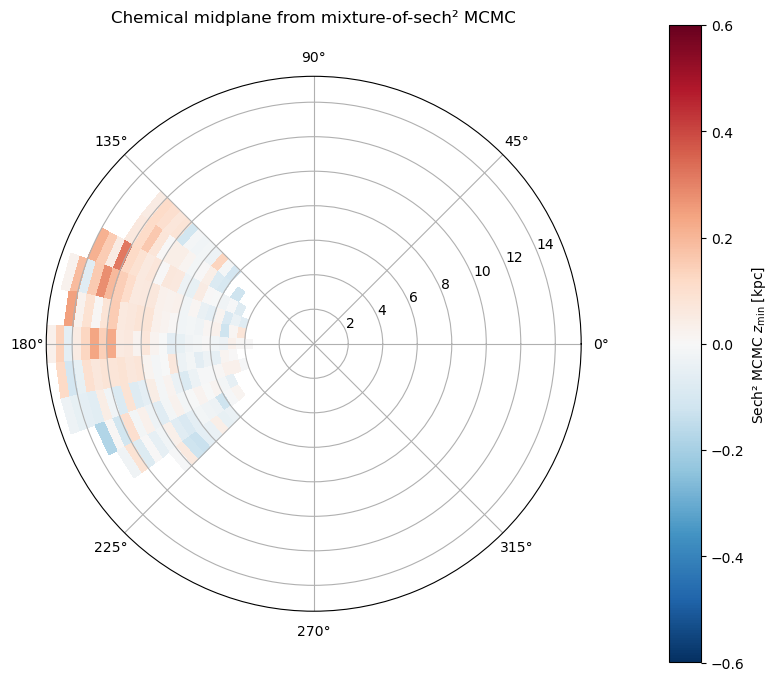

In [45]:
# --- 7c. Polar map ---

Zmap_sech2, theta_edges_sech2, R_edges_sech2, seg_plot_heat_sech2 = build_sech2_polar_map(
     df_sech2=df_sech2,
     crowd_bounds=crowd_bounds,
     seg_plot=SEG_PLOT,
     seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
     zlim=0.6,
)
#
ok_vals = df_sech2.loc[df_sech2["status_sech2"] == "ok", "z_min_sech2"]
vmax = float(np.percentile(np.abs(ok_vals), 95))
print(f"Suggested vmax: {vmax:.3f} kpc")
#
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))
pcm = ax.pcolormesh(
     theta_edges_sech2, R_edges_sech2, Zmap_sech2,
     shading="auto", cmap="RdBu_r", vmin=-.6, vmax=.6,
 )
cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Sech² MCMC $z_{\min}$ [kpc]")
ax.set_title("Chemical midplane from mixture-of-sech² MCMC", pad=20)
plt.tight_layout()
plt.show()

Suggested vmax: 0.154 kpc


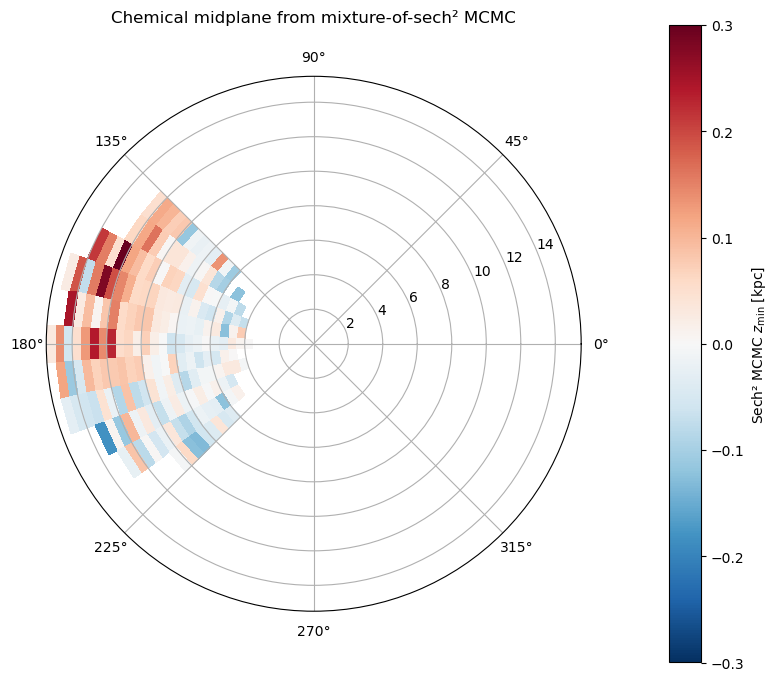

In [50]:
# --- 7c. Polar map ---

Zmap_sech2, theta_edges_sech2, R_edges_sech2, seg_plot_heat_sech2 = build_sech2_polar_map(
     df_sech2=df_sech2,
     crowd_bounds=crowd_bounds,
     seg_plot=SEG_PLOT,
     seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
     zlim=0.6,
)
#
ok_vals = df_sech2.loc[df_sech2["status_sech2"] == "ok", "z_min_sech2"]
vmax = float(np.percentile(np.abs(ok_vals), 95))
print(f"Suggested vmax: {vmax:.3f} kpc")
#
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))
pcm = ax.pcolormesh(
     theta_edges_sech2, R_edges_sech2, Zmap_sech2,
     shading="auto", cmap="RdBu_r", vmin=-.3, vmax=.3,
 )
cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Sech² MCMC $z_{\min}$ [kpc]")
ax.set_title("Chemical midplane from mixture-of-sech² MCMC", pad=20)
plt.tight_layout()
plt.show()

In [47]:
def plot_sech2_multipanel(
    R_star, Z_star, mgfe_star,
    e_mg_h_star, e_fe_h_star,
    segm, seg_ids,
    Rmin_focus, Rmax_focus,
    z_edges,
    z_fit_min=-1.5, z_fit_max=1.5,
    min_bin_count=5,
    num_warmup=1000, num_samples=1000, num_chains=2,
    rng_seed=0, n_posterior_draws=100,
    ncols=4,
):
    e_mgfe_star = np.clip(np.sqrt(
        np.asarray(e_mg_h_star, float)**2 + np.asarray(e_fe_h_star, float)**2
    ), 1e-4, None)

    fit_edges = z_edges[(z_edges >= z_fit_min) & (z_edges <= z_fit_max)]
    z_grid    = np.linspace(z_fit_min, z_fit_max, 1000)
    mR        = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

    nseg  = len(seg_ids)
    nrows = int(np.ceil(nseg / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(5 * ncols, 4 * nrows),
                             sharex=True, sharey=True)
    axes = np.atleast_2d(axes)

    key = jr.PRNGKey(rng_seed)

    for j, ax in enumerate(axes.flat):
        if j >= nseg:
            ax.axis("off")
            continue

        seg_id = seg_ids[j]
        mseg   = mR & segm[seg_id]
        good   = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star) & np.isfinite(e_mgfe_star)

        Zs, MgFes, Errs = Z_star[good], mgfe_star[good], e_mgfe_star[good]
        infit = (Zs >= z_fit_min) & (Zs <= z_fit_max)
        Zs, MgFes, Errs = Zs[infit], MgFes[infit], Errs[infit]

        ax.scatter(Zs, MgFes, s=2, alpha=0.15, color="gray")

        if len(Zs) < 20:
            ax.set_title(f"Seg {seg_id}\ntoo few stars", fontsize=10)
            ax.axvline(0, color="0.7", lw=1)
            continue

        z_binc, mean_mgfe, err_mgfe = bin_data(Zs, MgFes, Errs, fit_edges, min_bin_count)
        ax.errorbar(z_binc, mean_mgfe, yerr=err_mgfe, fmt=".", color="C2", ms=5)

        if len(z_binc) < 6:
            ax.set_title(f"Seg {seg_id}\ntoo few bins", fontsize=10)
            ax.axvline(0, color="0.7", lw=1)
            continue

        key, subkey = jr.split(key)
        samples, idata, status = run_mcmc(
            z_binc, mean_mgfe, err_mgfe, subkey,
            num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains,
        )

        if status != "ok":
            ax.set_title(f"Seg {seg_id}\n{status}", fontsize=10)
            ax.axvline(0, color="0.7", lw=1)
            continue

        z0_draws = np.array(samples["z0"])
        z0_med   = float(np.median(z0_draws))

        idx = np.random.choice(len(samples["A1"]),
                               size=min(n_posterior_draws, len(samples["A1"])),
                               replace=False)
        for i in idx:
            h2_i  = float(samples["h1"][i]) + float(samples["d_h2"][i])
            y_pred = mixture_of_sech2(
                jnp.array(z_grid),
                samples["A1"][i], samples["A2"][i],
                samples["h1"][i], h2_i,
                samples["z0"][i], samples["offset"][i],
            )
            ax.plot(z_grid, np.array(y_pred), color="C1", alpha=0.08, lw=1)

        ax.axvline(z0_med, color="black", ls="--", lw=1.2)
        ax.axvline(0, color="0.7", lw=1)
        ax.set_title(f"Seg {seg_id}  z_min={z0_med:+.3f} kpc", fontsize=10)
        ax.set_xlim(z_fit_min, z_fit_max)

    fig.supxlabel("Z [kpc]")
    fig.supylabel("[Mg/Fe]")
    fig.suptitle(f"Sech² fit: R={Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.01)
    plt.tight_layout()
    plt.show()

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_3727/2117389588.py:125: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


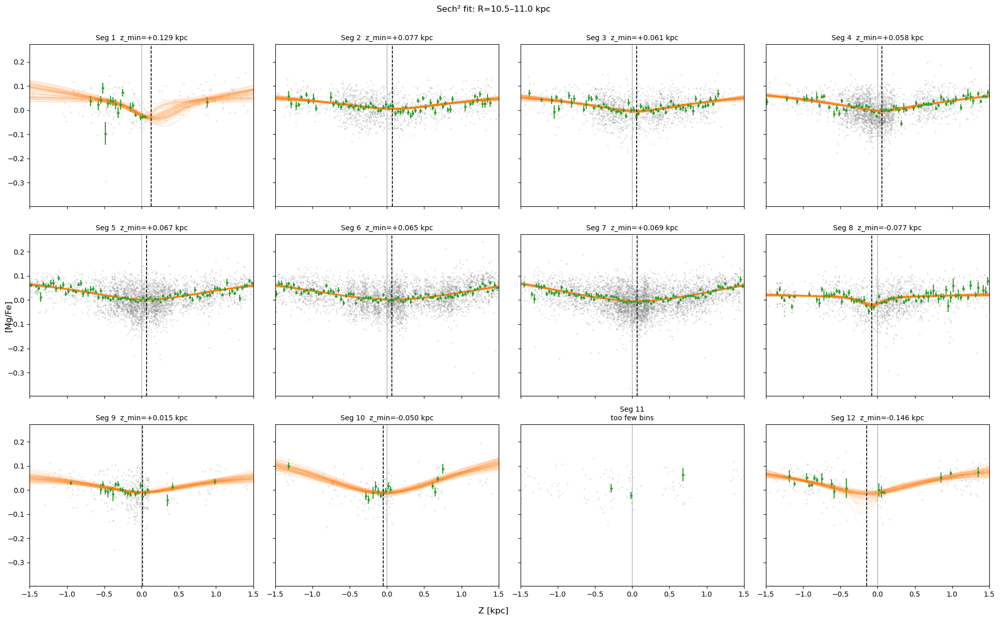

In [48]:
plot_sech2_multipanel(
    R_star=R_star, Z_star=Z_star, mgfe_star=mgfe_star,
    e_mg_h_star=e_mg_h_star, e_fe_h_star=e_fe_h_star,
    segm=segm,
    seg_ids=SEG_PLOT,
    Rmin_focus=10.5, Rmax_focus=11.0,
    z_edges=z_edges,
    ncols=4,
)

### Spline

389650 389650 389650 389650


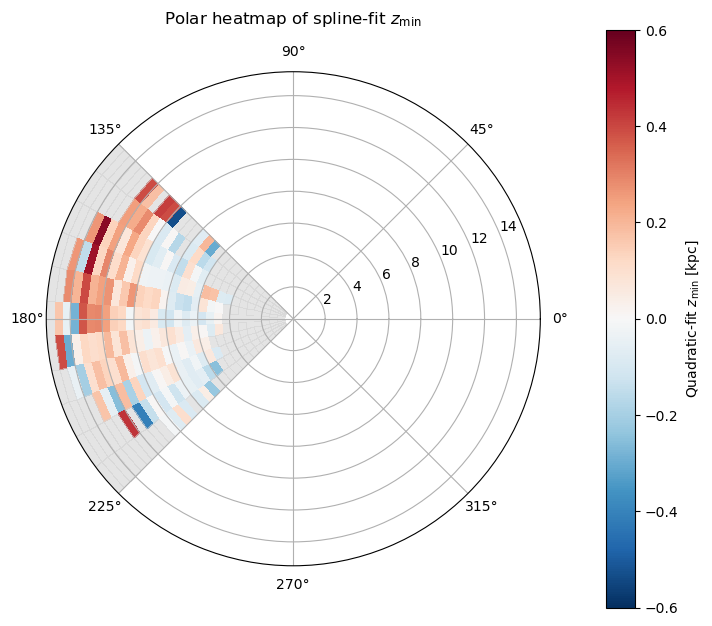

In [18]:
from src.fitting import compute_df_spline, build_spline_polar_map
from src.plotting import plot_zmin_polar_heatmap

# shared settings
z_edges = np.linspace(-3.0, 3.0, 181)
R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)
# unpack the SAME star pack you are using for the spline fit
X_star = star_pack["X_star"]
Y_star = star_pack["Y_star"]
Z_star = star_pack["Z_star"]
R_star = star_pack["R_star"]
phi_star = star_pack["phi_star"]
mgfe_star = star_pack["mgfe_star"]

# rebuild segment masks from this exact phi_star
segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi_star,
    phi0=np.pi,
    crowd_halfwidth_deg=45,
    n_crowd=11
)

# optional sanity check
print(len(R_star), len(phi_star), len(mgfe_star), len(segm[1]))
# spline settings
minN_seg_total = 20     # Minimum number of stars in the segment before doing any fitting
min_bin_count = 5      # Minimum number of stars per z-bin
z_fit_min, z_fit_max = -1.5, 1.5
min_bins_for_fit = 10   # Minimum number of usable bins required to perform the fit
zlim = 0.6

# spline-specific controls
use_sem_weights = False
spline_k = 3
spline_s = None          # start with SciPy default smoothing
n_eval = 400
max_allowed_minima = 1
edge_buffer = 0.05

df_spline = compute_df_spline(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,
    R_edges=R_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    use_sem_weights=use_sem_weights,
    spline_k=spline_k,
    spline_s=spline_s,
    n_eval=n_eval,
    max_allowed_minima=max_allowed_minima,
    edge_buffer=edge_buffer,
)

Zmap_spline, theta_edges_spline, R_edges_kept_spline, SEG_PLOT_heat_spline = build_spline_polar_map(
    df_spline=df_spline,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=seg_diag["seg_rest_id"],
    zlim=zlim,
)

plot_zmin_polar_heatmap(
    Zmap=Zmap_spline,
    theta_edges=theta_edges_spline,
    R_edges_kept=R_edges_kept_spline,
    zlim=zlim,
    title=r"Polar heatmap of spline-fit $z_{\min}$"
)

In [19]:
print(df_quad["status_quad"].value_counts(dropna=False))
print(df_spline["status_spline"].value_counts(dropna=False))

status_quad
ok                    189
too_few_bins          122
too_few_stars          36
bad_curvature          12
min_outside_window      1
Name: count, dtype: int64
status_spline
ok                 184
too_few_bins       122
too_few_stars       45
minimum_at_edge      9
Name: count, dtype: int64


In [20]:
merged = df_quad.merge(
    df_spline,
    on=["Rmin", "Rmax", "seg"],
    how="inner"
)

good = (
    (merged["status_quad"] == "ok") &
    (merged["status_spline"] == "ok") &
    np.isfinite(merged["z_min_quad"]) &
    np.isfinite(merged["z_min_spline"])
)

print("N good in both:", int(np.sum(good)))
print("Median abs difference [kpc]:",
      np.nanmedian(np.abs(merged.loc[good, "z_min_spline"] - merged.loc[good, "z_min_quad"])))
print("Mean signed difference [kpc]:",
      np.nanmean(merged.loc[good, "z_min_spline"] - merged.loc[good, "z_min_quad"]))

N good in both: 177
Median abs difference [kpc]: 0.09087836694614354
Mean signed difference [kpc]: 0.018622763831092272


Annulus 10.5–11.0 kpc: Ntot = 20663


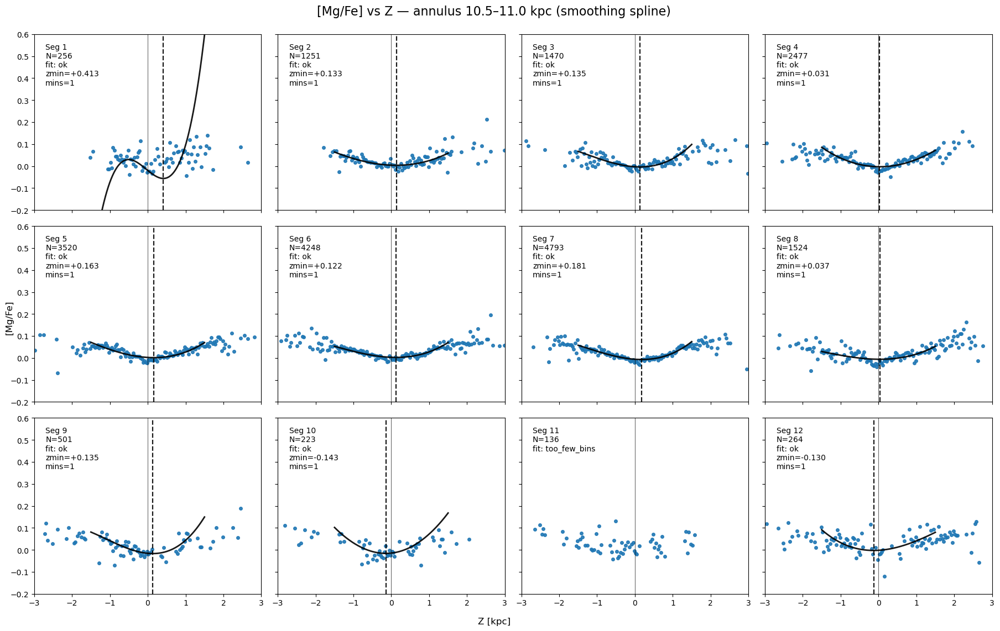

,seg_id,Nseg,status,zmin,n_local_min
0,1,256,ok,0.412780,1.0
1,2,1251,ok,0.133299,1.0
2,3,1470,ok,0.135434,1.0
3,4,2477,ok,0.030668,1.0
4,5,3520,ok,0.162980,1.0
5,6,4248,ok,0.122164,1.0
6,7,4793,ok,0.181042,1.0
7,8,1524,ok,0.037022,1.0
8,9,501,ok,0.134570,1.0
9,10,223,ok,-0.143105,1.0


In [21]:
from src.plotting import plot_single_annulus_spline_fits

# choose annulus
Rmin_focus, Rmax_focus = 10.5, 11.0

# include all crowded wedges + rest
SEG_PLOT = list(range(1, seg_diag["n_crowd"] + 2))

spline_segment_results = plot_single_annulus_spline_fits(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    Rmin_focus=Rmin_focus,
    Rmax_focus=Rmax_focus,
    z_edges=z_edges,
    seg_plot=SEG_PLOT,

    minN_seg_total=15,
    min_bin_count=5,
    z_fit_min=-1.5,
    z_fit_max=1.5,
    min_bins_for_fit=8,

    use_sem_weights=False,   # set True if you want SEM-weighted spline
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,

    xlim=(-3, 3),
    ylim=(-0.2, 0.6),
    ncols=4,
)

import pandas as pd
pd.DataFrame(spline_segment_results)

Raw stars in segment: 501
Binned points used in fit: 24


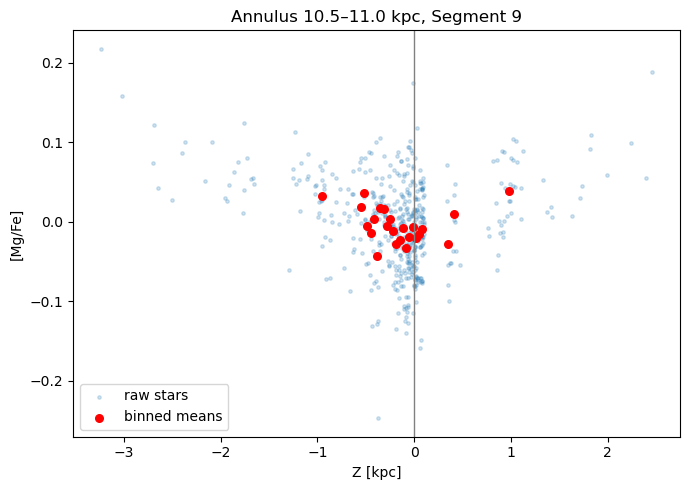

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# choose the same annulus/segment as in your panel
# -----------------------------
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 9

# annulus mask
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

# segment mask
mseg = mR & segm[seg_id]

# raw stars in that annulus+segment
Z_raw = Z_star[mseg]
mgfe_raw = mgfe_star[mseg]

good_raw = np.isfinite(Z_raw) & np.isfinite(mgfe_raw)
Z_raw = Z_raw[good_raw]
mgfe_raw = mgfe_raw[good_raw]

print("Raw stars in segment:", len(Z_raw))

# -----------------------------
# rebuild the binned points the fit uses
# -----------------------------
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

mean_line = np.full(len(z_edges) - 1, np.nan)
cnt_line = np.zeros(len(z_edges) - 1, dtype=int)

inds = np.searchsorted(z_edges, Z_raw, side="right") - 1
ok = (inds >= 0) & (inds < len(z_edges) - 1)
inds = inds[ok]
mgfe_use = mgfe_raw[ok]

for i in range(len(z_edges) - 1):
    mm = (inds == i)
    cnt_line[i] = np.sum(mm)
    if cnt_line[i] > 0:
        mean_line[i] = np.nanmean(mgfe_use[mm])

# if you want only bins with at least min_bin_count
min_bin_count = 5
good_bins = np.isfinite(mean_line) & (cnt_line >= min_bin_count)

Z_bins = z_centers[good_bins]
mgfe_bins = mean_line[good_bins]

print("Binned points used in fit:", len(Z_bins))

# -----------------------------
# plot raw + binned
# -----------------------------
plt.figure(figsize=(7, 5))
plt.scatter(Z_raw, mgfe_raw, s=6, alpha=0.2, label="raw stars")
plt.scatter(Z_bins, mgfe_bins, color="red", s=30, label="binned means")
plt.axvline(0, color="gray", lw=1)

plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc, Segment {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()

Annulus 10.5–11.0 kpc: Ntot = 20663


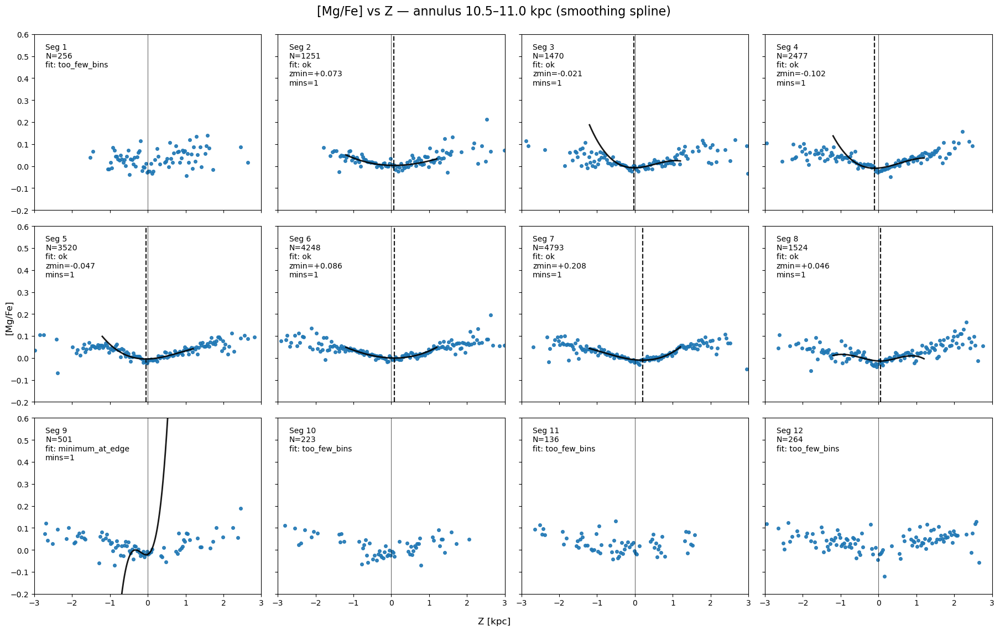

In [23]:
results = plot_single_annulus_spline_fits(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    Rmin_focus=10.5,
    Rmax_focus=11.0,
    z_edges=z_edges,
    seg_plot=list(range(1, 13)),
    minN_seg_total=15,
    min_bin_count=10,
    z_fit_min=-1.2,
    z_fit_max=1.2,
    min_bins_for_fit=8,
    use_sem_weights=False,
    spline_k=3,
    spline_s=0.01,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,
)

In [24]:
from src.fitting import (
    compute_df_spline,            # OLD (UnivariateSpline)
    compute_df_spline_splrep      # NEW (make_splrep)
)

In [25]:
df_old = compute_df_spline(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,
    use_sem_weights=True,
    spline_k=3,
    spline_s=None,
)

df_new = compute_df_spline_splrep(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,
    use_sem_weights=False,
    spline_k=3,
    spline_s=0.1,
)

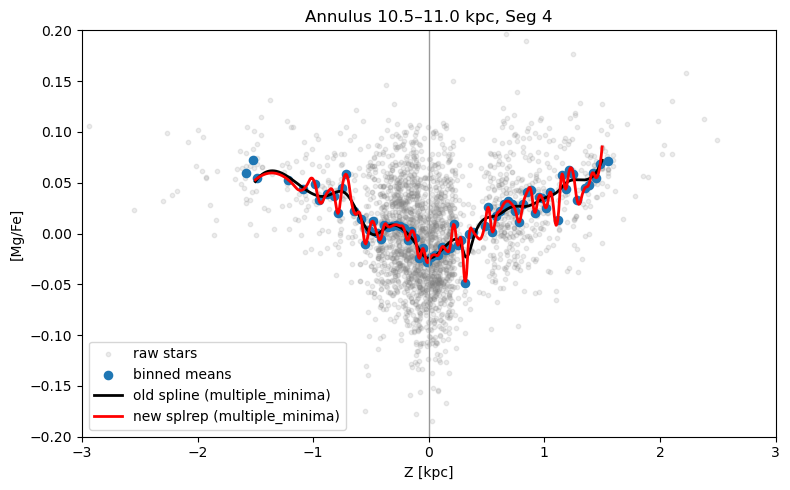

In [26]:
import numpy as np
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_and_counts,
    binned_mean_count_sem,
    spline_fit_on_trend,
    spline_fit_on_trend_splrep,
)

# pick one annulus and one segment
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
Ys = mgfe_star[mseg]

good = np.isfinite(Zs) & np.isfinite(Ys)
Zs = Zs[good]
Ys = Ys[good]

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

# binned means
mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
valid = np.isfinite(mean_line) & (cnt_line >= 5)

# old spline
fit_old, st_old, z0_old = spline_fit_on_trend(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.5, zmax=1.5,
    min_cnt=5, min_bins=8,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,
)

# new splrep spline
fit_new, st_new, z0_new = spline_fit_on_trend_splrep(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.5, zmax=1.5,
    min_cnt=5, min_bins=8,
    spline_k=2,
    spline_s=0.01,   # try 0.01, 0.05, etc
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
)

plt.figure(figsize=(8, 5))

# raw stars
plt.scatter(Zs, Ys, s=10, alpha=0.15, color="gray", label="raw stars")

# binned means
plt.scatter(z_centers[valid], mean_line[valid], s=35, color="tab:blue", label="binned means")

# old spline
if fit_old is not None:
    plt.plot(fit_old["zgrid"], fit_old["ygrid"], color="black", lw=2, label=f"old spline ({st_old})")

# new splrep spline
if fit_new is not None:
    plt.plot(fit_new["zgrid"], fit_new["ygrid"], color="red", lw=2, label=f"new splrep ({st_new})")

# minima
if np.isfinite(z0_old):
    plt.axvline(z0_old, color="black", ls="--", alpha=0.8, label=f"old zmin={z0_old:+.3f}")
if np.isfinite(z0_new):
    plt.axvline(z0_new, color="red", ls="--", alpha=0.8, label=f"new zmin={z0_new:+.3f}")

plt.axvline(0, color="0.6", lw=1)
plt.xlim(-3, 3)
plt.ylim(-0.2, 0.2)
plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc, Seg {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()

/Users/emmatasso/miniforge3/lib/python3.12/site-packages/scipy/interpolate/_fitpack_repro.py:705: RuntimeWarning: error. the maximal number of iterations maxit (set to 20
by the program) allowed for finding a smoothing spline
with fp=s has been reached. probably causes : s too small
there is an approximation returned but the corresponding
weighted sum of squared residuals does not satisfy the
condition abs(fp-s)/s < tol.

  _ = root_rati(f, p, bracket, acc)


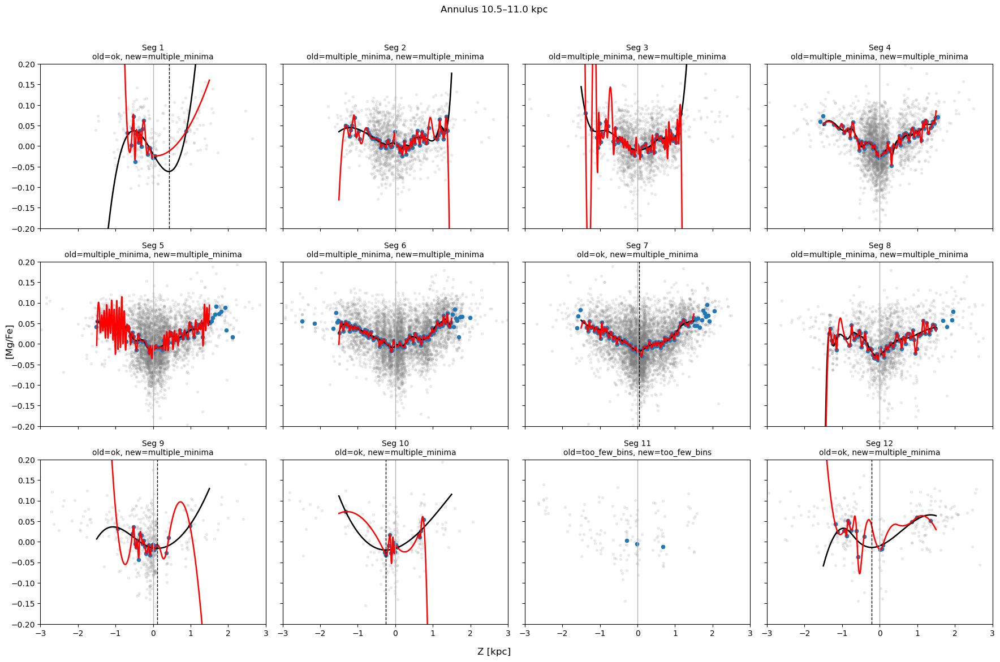

In [27]:
import numpy as np
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
    spline_fit_on_trend_splrep,
)

Rmin_focus, Rmax_focus = 10.5, 11.0
seg_ids = SEG_PLOT

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

nseg = len(seg_ids)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5*ncols, 3.8*nrows), sharex=True, sharey=True)
axes = np.atleast_2d(axes)

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = seg_ids[j]
    mseg = mR & segm[seg_id]

    Zs = Z_star[mseg]
    Ys = mgfe_star[mseg]
    good = np.isfinite(Zs) & np.isfinite(Ys)
    Zs = Zs[good]
    Ys = Ys[good]

    ax.scatter(Zs, Ys, s=8, alpha=0.12, color="gray")

    if len(Zs) < 15:
        ax.set_title(f"Seg {seg_id}: too few")
        continue

    mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
    valid = np.isfinite(mean_line) & (cnt_line >= 5)
    ax.scatter(z_centers[valid], mean_line[valid], s=20, color="tab:blue")

    fit_old, st_old, z0_old = spline_fit_on_trend(
        z_centers, mean_line, cnt_line, sem=sem_line,
        zmin=-1.5, zmax=1.5,
        min_cnt=5, min_bins=8,
        spline_k=3,
        spline_s=None,
        n_eval=400,
        max_allowed_minima=1,
        edge_buffer=0.05,
    )

    fit_new, st_new, z0_new = spline_fit_on_trend_splrep(
        z_centers, mean_line, cnt_line, sem=sem_line,
        zmin=-1.5, zmax=1.5,
        min_cnt=5, min_bins=8,
        spline_k=2,
        spline_s=0.01,
        n_eval=400,
        max_allowed_minima=1,
        edge_buffer=0.15,
    )

    if fit_old is not None:
        ax.plot(fit_old["zgrid"], fit_old["ygrid"], color="black", lw=1.8)
    if fit_new is not None:
        ax.plot(fit_new["zgrid"], fit_new["ygrid"], color="red", lw=1.8)

    if np.isfinite(z0_old):
        ax.axvline(z0_old, color="black", ls="--", lw=1)
    if np.isfinite(z0_new):
        ax.axvline(z0_new, color="red", ls="--", lw=1)

    ax.axvline(0, color="0.7", lw=1)
    ax.set_title(f"Seg {seg_id}\nold={st_old}, new={st_new}", fontsize=10)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.2)

fig.supxlabel("Z [kpc]")
fig.supylabel("[Mg/Fe]")
fig.suptitle(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.02)
fig.tight_layout()
plt.show()

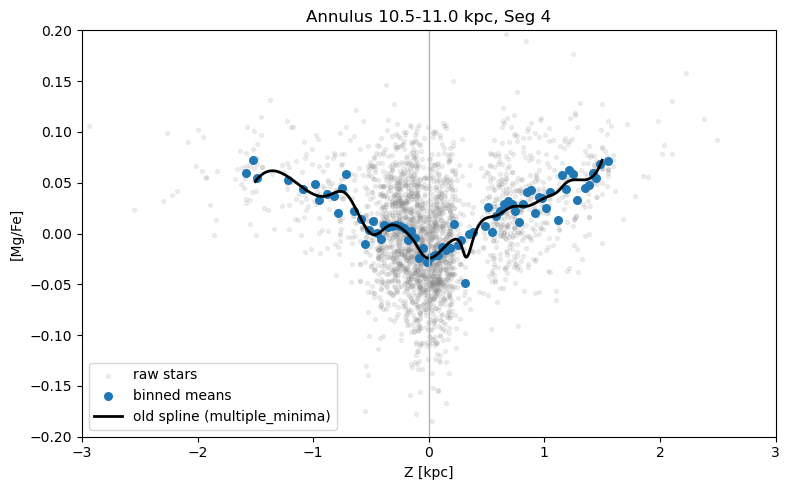

In [28]:
def spline_fit_on_trend_fixedknots(
    z_centers,
    trend,
    cnt,
    sem=None,
    zmin=-1.25,
    zmax=1.25,
    min_cnt=5,
    min_bins=8,
    spline_k=2,
    knots=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
):
    """
    Fit a constrained least-squares spline with fixed interior knots.

    Parameters
    ----------
    z_centers : array
    trend : array
        Mean Mg/Fe per z-bin
    cnt : array
        Count per z-bin
    sem : array or None
        SEM per z-bin; if provided, use weights = 1/sem
    zmin, zmax : float
        Fit / search window
    min_cnt : int
        Minimum stars per z-bin to include
    min_bins : int
        Minimum number of valid bins required
    spline_k : int
        Spline degree (recommend 2)
    knots : array-like or None
        Interior knot positions. Example: [-0.5, 0.5]
    n_eval : int
        Number of grid points for post-fit checks
    max_allowed_minima : int
        Reject if spline has more than this many local minima
    edge_buffer : float
        Reject minima too close to zmin/zmax

    Returns
    -------
    fit_obj : dict or None
    status : str
    z0 : float
    """
    zc = np.asarray(z_centers, float)
    tr = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    if sem is None:
        use = (
            (zc >= zmin) & (zc <= zmax) &
            np.isfinite(tr) &
            (cnt >= min_cnt)
        )
    else:
        sem = np.asarray(sem, float)
        use = (
            (zc >= zmin) & (zc <= zmax) &
            np.isfinite(tr) &
            (cnt >= min_cnt) &
            np.isfinite(sem) & (sem > 0)
        )

    if np.sum(use) < min_bins:
        return None, "too_few_bins", np.nan

    x = zc[use]
    y = tr[use]

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    # weights
    if sem is not None:
        s_arr = sem[use][order]
        pos = s_arr[np.isfinite(s_arr) & (s_arr > 0)]
        if len(pos) == 0:
            return None, "bad_sem", np.nan

        # prevent one tiny-SEM bin from dominating
        s_floor = max(np.nanpercentile(pos, 25), 5e-4)
        s_arr = np.maximum(s_arr, s_floor)
        w = 1.0 / s_arr
    else:
        w = None

    # default interior knots
    if knots is None:
        knots = np.array([0, 0], float)
    else:
        knots = np.asarray(knots, float)

    # keep only valid interior knots
    knots = knots[(knots > zmin) & (knots < zmax)]
    knots = np.unique(knots)

    # LSQUnivariateSpline requires:
    # len(x) > len(knots) + k
    if len(x) <= len(knots) + spline_k:
        return None, "too_few_points_for_knots", np.nan

    try:
        spl = LSQUnivariateSpline(x, y, t=knots, w=w, k=spline_k)
    except Exception:
        return None, "fit_failed", np.nan

    zgrid = np.linspace(zmin, zmax, n_eval)
    ygrid = spl(zgrid)

    is_local_min = (
        (ygrid[1:-1] < ygrid[:-2]) &
        (ygrid[1:-1] < ygrid[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min > max_allowed_minima:
        fit_obj = {
            "spline": spl,
            "zgrid": zgrid,
            "ygrid": ygrid,
            "n_local_min": n_local_min,
            "x_used": x,
            "y_used": y,
            "knots": knots,
        }
        return fit_obj, "multiple_minima", np.nan

    imin = np.argmin(ygrid)
    z0 = float(zgrid[imin])

    if (z0 <= zmin + edge_buffer) or (z0 >= zmax - edge_buffer):
        fit_obj = {
            "spline": spl,
            "zgrid": zgrid,
            "ygrid": ygrid,
            "n_local_min": n_local_min,
            "x_used": x,
            "y_used": y,
            "knots": knots,
        }
        return fit_obj, "minimum_at_edge", np.nan

    fit_obj = {
        "spline": spl,
        "zgrid": zgrid,
        "ygrid": ygrid,
        "n_local_min": n_local_min,
        "x_used": x,
        "y_used": y,
        "knots": knots,
    }
    return fit_obj, "ok", z0

def compute_df_spline_fixedknots(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    z_edges,
    R_edges=None,
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,
    use_sem_weights=True,
    spline_k=2,
    knots=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
):
    """
    Compute constrained fixed-knot spline z_min for all (annulus, segment).
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    R_edges_kept = np.asarray(R_edges, float)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin_focus = float(R_edges_kept[ir])
        Rmax_focus = float(R_edges_kept[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                    z_min_spline=np.nan, status_spline="too_few_stars"
                ))
                continue

            Zs = Z_star[good]
            Ys = mgfe_star[good]

            if use_sem_weights:
                mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
                fit_obj, st, z0 = spline_fit_on_trend_fixedknots(
                    z_centers, mean_line, cnt_line, sem=sem_line,
                    zmin=z_fit_min, zmax=z_fit_max,
                    min_cnt=min_bin_count, min_bins=min_bins_for_fit,
                    spline_k=spline_k, knots=knots,
                    n_eval=n_eval,
                    max_allowed_minima=max_allowed_minima,
                    edge_buffer=edge_buffer,
                )
            else:
                mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
                fit_obj, st, z0 = spline_fit_on_trend_fixedknots(
                    z_centers, mean_line, cnt_line, sem=None,
                    zmin=z_fit_min, zmax=z_fit_max,
                    min_cnt=min_bin_count, min_bins=min_bins_for_fit,
                    spline_k=spline_k, knots=knots,
                    n_eval=n_eval,
                    max_allowed_minima=max_allowed_minima,
                    edge_buffer=edge_buffer,
                )

            rows.append(dict(
                Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                z_min_spline=z0, status_spline=st
            ))

    return pd.DataFrame(rows)

Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
Ys = mgfe_star[mseg]
good = np.isfinite(Zs) & np.isfinite(Ys)
Zs = Zs[good]
Ys = Ys[good]

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
valid = np.isfinite(mean_line) & (cnt_line >= 5)

fit_old, st_old, z0_old = spline_fit_on_trend(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.5, zmax=1.5,
    min_cnt=5, min_bins=8,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,
)

fit_fk, st_fk, z0_fk = spline_fit_on_trend_fixedknots(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.5, zmax=1.5,
    min_cnt=5, min_bins=8,
    spline_k=2,
    knots=[-0.5, 0.5],
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
)

plt.figure(figsize=(8, 5))
plt.scatter(Zs, Ys, s=8, alpha=0.12, color="gray", label="raw stars")
plt.scatter(z_centers[valid], mean_line[valid], s=30, color="tab:blue", label="binned means")

if fit_old is not None:
    plt.plot(fit_old["zgrid"], fit_old["ygrid"], color="black", lw=2, label=f"old spline ({st_old})")

if fit_fk is not None:
    plt.plot(fit_fk["zgrid"], fit_fk["ygrid"], color="red", lw=2, label=f"fixed-knot spline ({st_fk})")

if np.isfinite(z0_old):
    plt.axvline(z0_old, color="black", ls="--", alpha=0.8)
if np.isfinite(z0_fk):
    plt.axvline(z0_fk, color="red", ls="--", alpha=0.8)

plt.axvline(0, color="0.7", lw=1)
plt.xlim(-3, 3)
plt.ylim(-0.2, 0.2)
plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(f"Annulus {Rmin_focus:.1f}-{Rmax_focus:.1f} kpc, Seg {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()

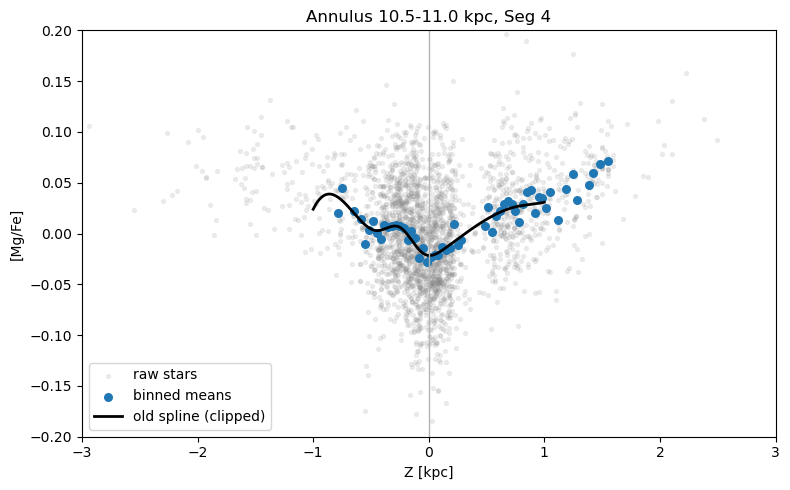

In [29]:
from scipy.ndimage import gaussian_filter1d
def smooth_valid_1d(y, sigma=1.0):
    """
    Smooth only the finite part of a 1D array with a Gaussian filter.
    Non-finite values remain NaN.
    """
    y = np.asarray(y, float)
    out = np.full_like(y, np.nan)

    good = np.isfinite(y)
    if np.sum(good) == 0:
        return out

    yg = y[good]
    out[good] = gaussian_filter1d(yg, sigma=sigma, mode="nearest")
    return out


def spline_fit_on_trend_fixedknots(
    z_centers,
    trend,
    cnt,
    sem=None,
    zmin=-1.5,
    zmax=1.5,
    min_cnt=5,
    min_bins=8,
    spline_k=2,
    knots=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
    smooth_before_fit=False,
    smooth_sigma=1.0,
):
    """
    Fit a constrained least-squares spline with fixed interior knots.

    Parameters
    ----------
    z_centers : array
    trend : array
        Mean Mg/Fe per z-bin
    cnt : array
        Count per z-bin
    sem : array or None
        SEM per z-bin; if provided, use weights = 1/sem
    zmin, zmax : float
        Fit / search window
    min_cnt : int
        Minimum stars per z-bin to include
    min_bins : int
        Minimum number of valid bins required
    spline_k : int
        Spline degree (recommend 2)
    knots : array-like or None
        Interior knot positions. Example: [-0.5, 0.5] or [0.0]
    n_eval : int
        Number of grid points for post-fit checks
    max_allowed_minima : int
        Reject if spline has more than this many local minima
    edge_buffer : float
        Reject minima too close to zmin/zmax
    smooth_before_fit : bool
        If True, smooth the trend values before fitting
    smooth_sigma : float
        Gaussian sigma used if smooth_before_fit=True

    Returns
    -------
    fit_obj : dict or None
    status : str
    z0 : float
    """
    zc = np.asarray(z_centers, float)
    tr = np.asarray(trend, float)
    cnt = np.asarray(cnt, int)

    if sem is None:
        use = (
            (zc >= zmin) & (zc <= zmax) &
            np.isfinite(tr) &
            (cnt >= min_cnt)
        )
    else:
        sem = np.asarray(sem, float)
        use = (
            (zc >= zmin) & (zc <= zmax) &
            np.isfinite(tr) &
            (cnt >= min_cnt) &
            np.isfinite(sem) & (sem > 0)
        )

    if np.sum(use) < min_bins:
        return None, "too_few_bins", np.nan

    x = zc[use]
    y = tr[use]

    order = np.argsort(x)
    x = x[order]
    y = y[order]

    if smooth_before_fit:
        y = smooth_valid_1d(y, sigma=smooth_sigma)

    # weights
    if sem is not None:
        s_arr = sem[use][order]
        pos = s_arr[np.isfinite(s_arr) & (s_arr > 0)]
        if len(pos) == 0:
            return None, "bad_sem", np.nan

        # prevent one tiny-SEM bin from dominating
        s_floor = max(np.nanpercentile(pos, 25), 5e-4)
        s_arr = np.maximum(s_arr, s_floor)
        w = 1.0 / s_arr
    else:
        w = None

    # default interior knots
    if knots is None:
        knots = np.array([0.0], float)
    else:
        knots = np.asarray(knots, float)

    # keep only valid interior knots
    knots = knots[(knots > zmin) & (knots < zmax)]
    knots = np.unique(knots)

    # LSQUnivariateSpline requires enough points
    if len(x) <= len(knots) + spline_k:
        return None, "too_few_points_for_knots", np.nan

    try:
        spl = LSQUnivariateSpline(x, y, t=knots, w=w, k=spline_k)
    except Exception:
        return None, "fit_failed", np.nan
    search_min=-1.0,
    search_max=1.0,
    zgrid = np.linspace(search_min, search_max, n_eval)
    ygrid = spl(zgrid)

    is_local_min = (
        (ygrid[1:-1] < ygrid[:-2]) &
        (ygrid[1:-1] < ygrid[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min > max_allowed_minima:
        fit_obj = {
            "spline": spl,
            "zgrid": zgrid,
            "ygrid": ygrid,
            "n_local_min": n_local_min,
            "x_used": x,
            "y_used": y,
            "knots": knots,
        }
        return fit_obj, "multiple_minima", np.nan

    imin = np.argmin(ygrid)
    z0 = float(zgrid[imin])

    if (z0 <= zmin + edge_buffer) or (z0 >= zmax - edge_buffer):
        fit_obj = {
            "spline": spl,
            "zgrid": zgrid,
            "ygrid": ygrid,
            "n_local_min": n_local_min,
            "x_used": x,
            "y_used": y,
            "knots": knots,
        }
        return fit_obj, "minimum_at_edge", np.nan

    fit_obj = {
        "spline": spl,
        "zgrid": zgrid,
        "ygrid": ygrid,
        "n_local_min": n_local_min,
        "x_used": x,
        "y_used": y,
        "knots": knots,
    }
    return fit_obj, "ok", z0


def compute_df_spline_fixedknots(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    z_edges,
    R_edges=None,
    minN_seg_total=15,
    min_bin_count=5,
    z_fit_min=-1.5,
    z_fit_max=1.5,
    min_bins_for_fit=8,
    use_sem_weights=True,
    spline_k=2,
    knots=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
    smooth_before_fit=False,
    smooth_sigma=1.0,
):
    """
    Compute constrained fixed-knot spline z_min for all (annulus, segment).
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    R_edges_kept = np.asarray(R_edges, float)
    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

    rows = []
    for ir in range(len(R_edges_kept) - 1):
        Rmin_focus = float(R_edges_kept[ir])
        Rmax_focus = float(R_edges_kept[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                    z_min_spline=np.nan, status_spline="too_few_stars"
                ))
                continue

            Zs = Z_star[good]
            Ys = mgfe_star[good]

            if use_sem_weights:
                mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
                fit_obj, st, z0 = spline_fit_on_trend_fixedknots(
                    z_centers, mean_line, cnt_line, sem=sem_line,
                    zmin=z_fit_min, zmax=z_fit_max,
                    min_cnt=min_bin_count, min_bins=min_bins_for_fit,
                    spline_k=spline_k, knots=knots,
                    n_eval=n_eval,
                    max_allowed_minima=max_allowed_minima,
                    edge_buffer=edge_buffer,
                    smooth_before_fit=smooth_before_fit,
                    smooth_sigma=smooth_sigma,
                )
            else:
                mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
                fit_obj, st, z0 = spline_fit_on_trend_fixedknots(
                    z_centers, mean_line, cnt_line, sem=None,
                    zmin=z_fit_min, zmax=z_fit_max,
                    min_cnt=min_bin_count, min_bins=min_bins_for_fit,
                    spline_k=spline_k, knots=knots,
                    n_eval=n_eval,
                    max_allowed_minima=max_allowed_minima,
                    edge_buffer=edge_buffer,
                    smooth_before_fit=smooth_before_fit,
                    smooth_sigma=smooth_sigma,
                )

            rows.append(dict(
                Rmin=Rmin_focus, Rmax=Rmax_focus, seg=int(seg_id),
                z_min_spline=z0, status_spline=st
            ))

    return pd.DataFrame(rows)

from scipy.ndimage import gaussian_filter1d

# smooth the binned means
mean_smooth = mean_line.copy()
good = np.isfinite(mean_smooth)

mean_smooth[good] = gaussian_filter1d(mean_smooth[good], sigma=1.2)

# restrict to fit window
mask = (
    (z_centers >= -1.25) &
    (z_centers <= 1.25) &
    np.isfinite(mean_smooth) &
    (cnt_line >= 8)
)

if np.sum(mask) >= 8:
    z_fit = z_centers[mask]
    y_fit = mean_smooth[mask]

    z0 = z_fit[np.argmin(y_fit)]
else:
    z0 = np.nan
import numpy as np
import matplotlib.pyplot as plt

Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
Ys = mgfe_star[mseg]
good = np.isfinite(Zs) & np.isfinite(Ys)
Zs = Zs[good]
Ys = Ys[good]

z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])

mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
valid = np.isfinite(mean_line) & (cnt_line >= 8)

fit_old, st_old, z0_old = spline_fit_on_trend(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.25, zmax=1.25,
    min_cnt=8, min_bins=8,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,
)

fit_fk, st_fk, z0_fk = spline_fit_on_trend_fixedknots(
    z_centers, mean_line, cnt_line, sem=sem_line,
    zmin=-1.25, zmax=1.25,
    min_cnt=8, min_bins=8,
    spline_k=2,
    knots=[0.0],
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
    smooth_before_fit=True,
    smooth_sigma=1.2,
)

plt.figure(figsize=(8, 5))
plt.scatter(Zs, Ys, s=8, alpha=0.12, color="gray", label="raw stars")
plt.scatter(z_centers[valid], mean_line[valid], s=30, color="tab:blue", label="binned means")

if fit_old is not None:
    mask_plot = (fit_old["zgrid"] >= -1.0) & (fit_old["zgrid"] <= 1.0)

plt.plot(
    fit_old["zgrid"][mask_plot],
    fit_old["ygrid"][mask_plot],
    color="black",
    lw=2,
    label="old spline (clipped)"
)

if fit_fk is not None:
    plt.plot(fit_fk["zgrid"], fit_fk["ygrid"], color="red", lw=2, label=f"fixed-knot spline ({st_fk})")

if np.isfinite(z0_old):
    plt.axvline(z0_old, color="black", ls="--", alpha=0.8)
if np.isfinite(z0_fk):
    plt.axvline(z0_fk, color="red", ls="--", alpha=0.8)

plt.axvline(0, color="0.7", lw=1)
plt.xlim(-3, 3)
plt.ylim(-0.2, 0.2)
plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(f"Annulus {Rmin_focus:.1f}-{Rmax_focus:.1f} kpc, Seg {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()

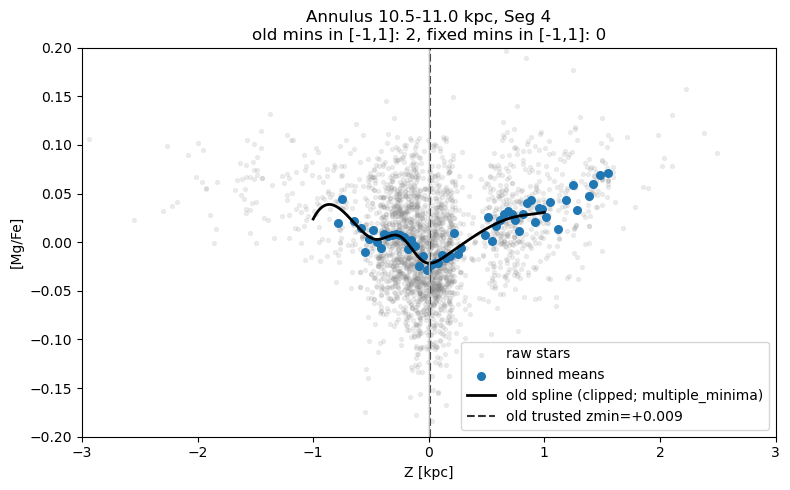

old spline status: multiple_minima
old trusted zmin: 0.009398496240601517
old minima in [-1,1]: 2
fixed-knot status: fit_failed
fixed trusted zmin: nan
fixed minima in [-1,1]: 0


In [30]:
import numpy as np
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend
)

# ----------------------------
# choose annulus + segment
# ----------------------------
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

# ----------------------------
# select stars in this segment
# ----------------------------
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
Ys = mgfe_star[mseg]

good = np.isfinite(Zs) & np.isfinite(Ys)
Zs = Zs[good]
Ys = Ys[good]

# ----------------------------
# binned means
# ----------------------------
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)

valid_pts = np.isfinite(mean_line) & (cnt_line >= 8)

# ----------------------------
# old spline
# ----------------------------
fit_old, st_old, z0_old = spline_fit_on_trend(
    z_centers=z_centers,
    trend=mean_line,
    cnt=cnt_line,
    sem=sem_line,
    zmin=-1.25,
    zmax=1.25,
    min_cnt=8,
    min_bins=8,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.05,
)

# ----------------------------
# constrained fixed-knot spline
# ----------------------------
fit_fk, st_fk, z0_fk = spline_fit_on_trend_fixedknots(
    z_centers=z_centers,
    trend=mean_line,
    cnt=cnt_line,
    sem=sem_line,
    zmin=-1.25,
    zmax=1.25,
    min_cnt=8,
    min_bins=8,
    spline_k=2,
    knots=[0.0],
    n_eval=400,
    max_allowed_minima=1,
    edge_buffer=0.15,
    smooth_before_fit=True,
    smooth_sigma=1.2,
)

# ----------------------------
# trusted minimum helper
# only search inside [-1, 1]
# if multiple minima, choose the one closest to 0
# ----------------------------
def trusted_minimum_from_fit(fit_obj, search_min=-1.0, search_max=1.0):
    if fit_obj is None:
        return np.nan, 0, None, None

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, 0, z_use, y_use

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        # fallback: global minimum in trusted window
        z0 = float(z_use[np.argmin(y_use)])
        return z0, 0, z_use, y_use

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])
    return z0, n_local_min, z_use, y_use

z0_old_trusted, nmin_old_trusted, z_old_use, y_old_use = trusted_minimum_from_fit(
    fit_old, search_min=-1.0, search_max=1.0
)

z0_fk_trusted, nmin_fk_trusted, z_fk_use, y_fk_use = trusted_minimum_from_fit(
    fit_fk, search_min=-1.0, search_max=1.0
)

# ----------------------------
# plot
# ----------------------------
plt.figure(figsize=(8, 5))

# raw stars
plt.scatter(Zs, Ys, s=8, alpha=0.12, color="gray", label="raw stars")

# binned means
plt.scatter(
    z_centers[valid_pts],
    mean_line[valid_pts],
    s=30,
    color="tab:blue",
    label="binned means"
)

# old spline, clipped to [-1,1]
if fit_old is not None:
    mask_plot_old = (fit_old["zgrid"] >= -1.0) & (fit_old["zgrid"] <= 1.0)
    plt.plot(
        fit_old["zgrid"][mask_plot_old],
        fit_old["ygrid"][mask_plot_old],
        color="black",
        lw=2,
        label=f"old spline (clipped; {st_old})"
    )

# fixed-knot spline, clipped to [-1,1]
if fit_fk is not None:
    mask_plot_fk = (fit_fk["zgrid"] >= -1.0) & (fit_fk["zgrid"] <= 1.0)
    plt.plot(
        fit_fk["zgrid"][mask_plot_fk],
        fit_fk["ygrid"][mask_plot_fk],
        color="red",
        lw=2,
        label=f"fixed-knot spline (clipped; {st_fk})"
    )

# trusted minima
if np.isfinite(z0_old_trusted):
    plt.axvline(
        z0_old_trusted,
        color="black",
        ls="--",
        alpha=0.8,
        label=f"old trusted zmin={z0_old_trusted:+.3f}"
    )

if np.isfinite(z0_fk_trusted):
    plt.axvline(
        z0_fk_trusted,
        color="red",
        ls="--",
        alpha=0.8,
        label=f"fixed trusted zmin={z0_fk_trusted:+.3f}"
    )

# reference line
plt.axvline(0, color="0.7", lw=1)

plt.xlim(-3, 3)
plt.ylim(-0.2, 0.2)
plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(
    f"Annulus {Rmin_focus:.1f}-{Rmax_focus:.1f} kpc, Seg {seg_id}\n"
    f"old mins in [-1,1]: {nmin_old_trusted}, fixed mins in [-1,1]: {nmin_fk_trusted}"
)
plt.legend()
plt.tight_layout()
plt.show()

print("old spline status:", st_old)
print("old trusted zmin:", z0_old_trusted)
print("old minima in [-1,1]:", nmin_old_trusted)

print("fixed-knot status:", st_fk)
print("fixed trusted zmin:", z0_fk_trusted)
print("fixed minima in [-1,1]:", nmin_fk_trusted)

In [31]:
import numpy as np
import pandas as pd

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

def trusted_minimum_from_fit(fit_obj, search_min=-1.0, search_max=1.0):
    """
    From a fitted spline object, find local minima only in [search_min, search_max].
    If multiple minima exist, choose the one closest to z=0.
    Returns:
        z0_trusted, n_local_min
    """
    if fit_obj is None:
        return np.nan, 0

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, 0

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        # fallback: use global min in trusted window
        z0 = float(z_use[np.argmin(y_use)])
        return z0, 0

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])
    return z0, n_local_min


def compute_df_spline_trusted(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    z_edges,
    R_edges=None,
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,
    search_min=-1.0,
    search_max=1.0,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    edge_buffer=0.05,
):
    """
    Loop over all annuli + segments, fit old spline, then define
    trusted z_min using only minima inside [search_min, search_max].
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    z_min_trusted=np.nan,
                    nmin_trusted=0,
                    status_trusted="too_few_stars",
                    Nseg=Nseg,
                ))
                continue

            Zs = Z_star[good]
            Ys = mgfe_star[good]

            mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)

            fit_obj, st, z0_raw = spline_fit_on_trend(
                z_centers=z_centers,
                trend=mean_line,
                cnt=cnt_line,
                sem=sem_line,
                zmin=z_fit_min,
                zmax=z_fit_max,
                min_cnt=min_bin_count,
                min_bins=min_bins_for_fit,
                spline_k=spline_k,
                spline_s=spline_s,
                n_eval=n_eval,
                max_allowed_minima=99,   # allow them; we handle trusted choice ourselves
                edge_buffer=edge_buffer,
            )

            z0_trusted, nmin_trusted = trusted_minimum_from_fit(
                fit_obj,
                search_min=search_min,
                search_max=search_max,
            )

            if fit_obj is None:
                status_trusted = f"fit_{st}"
            elif np.isfinite(z0_trusted):
                if nmin_trusted == 0:
                    status_trusted = "ok_fallback_globalmin_in_trusted_window"
                elif nmin_trusted == 1:
                    status_trusted = "ok_single_minimum"
                else:
                    status_trusted = "ok_multiple_choose_nearest_zero"
            else:
                status_trusted = "no_trusted_minimum"

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                z_min_trusted=z0_trusted,
                nmin_trusted=nmin_trusted,
                status_trusted=status_trusted,
                status_raw=st,
                z_min_raw=z0_raw,
                Nseg=Nseg,
            ))

    return pd.DataFrame(rows)

In [32]:
df_trusted = compute_df_spline_trusted(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,

    # tune these if needed
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,

    search_min=-1.0,
    search_max=1.0,

    spline_k=3,
    spline_s=None,
    n_eval=400,
    edge_buffer=0.05,
)

df_trusted.head()

,Rmin,Rmax,seg,z_min_trusted,nmin_trusted,status_trusted,Nseg,status_raw,z_min_raw
0,0.5,1.0,1,NaN,0,too_few_stars,6,NaN,NaN
1,0.5,1.0,2,NaN,0,too_few_stars,1,NaN,NaN
2,0.5,1.0,3,NaN,0,too_few_stars,4,NaN,NaN
3,0.5,1.0,4,NaN,0,too_few_stars,3,NaN,NaN
4,0.5,1.0,5,NaN,0,too_few_stars,6,NaN,NaN


In [33]:
def build_trusted_polar_map(df_trusted, crowd_bounds, seg_plot, seg_rest_id=None, zlim=0.6):
    """
    Build polar heatmap from df_trusted using z_min_trusted.
    """
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_trusted["Rmin"].tolist() + df_trusted["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = df_trusted["status_trusted"].str.startswith("ok", na=False)

    for _, row in df_trusted.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_trusted"])
        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmin

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat

In [34]:
Zmap_trusted, theta_edges_trusted, R_edges_trusted, seg_plot_heat_trusted = build_trusted_polar_map(
    df_trusted,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=0.6,
)

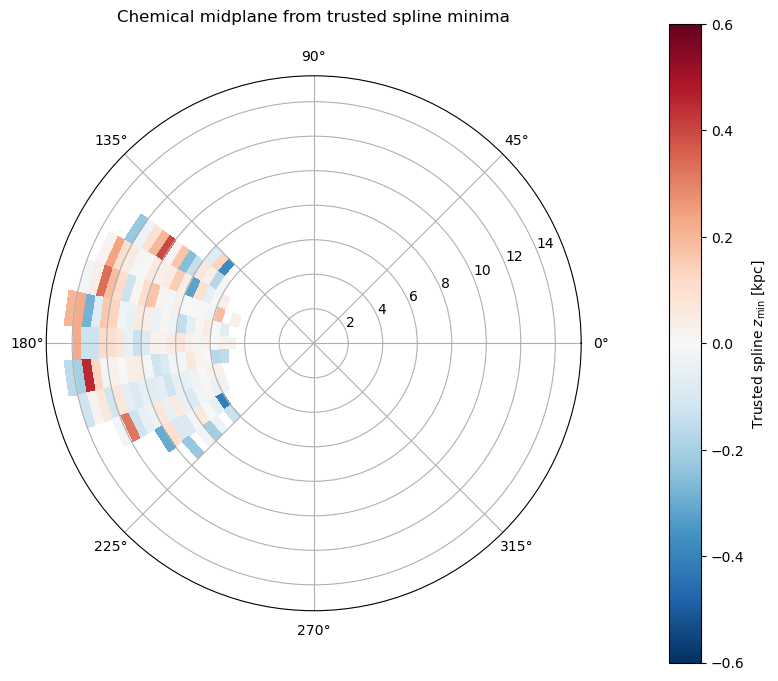

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_trusted,
    R_edges_trusted,
    Zmap_trusted,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.6,
    vmax=0.6,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Trusted spline $z_{\min}$ [kpc]")

ax.set_title("Chemical midplane from trusted spline minima", pad=20)
plt.tight_layout()
plt.show()

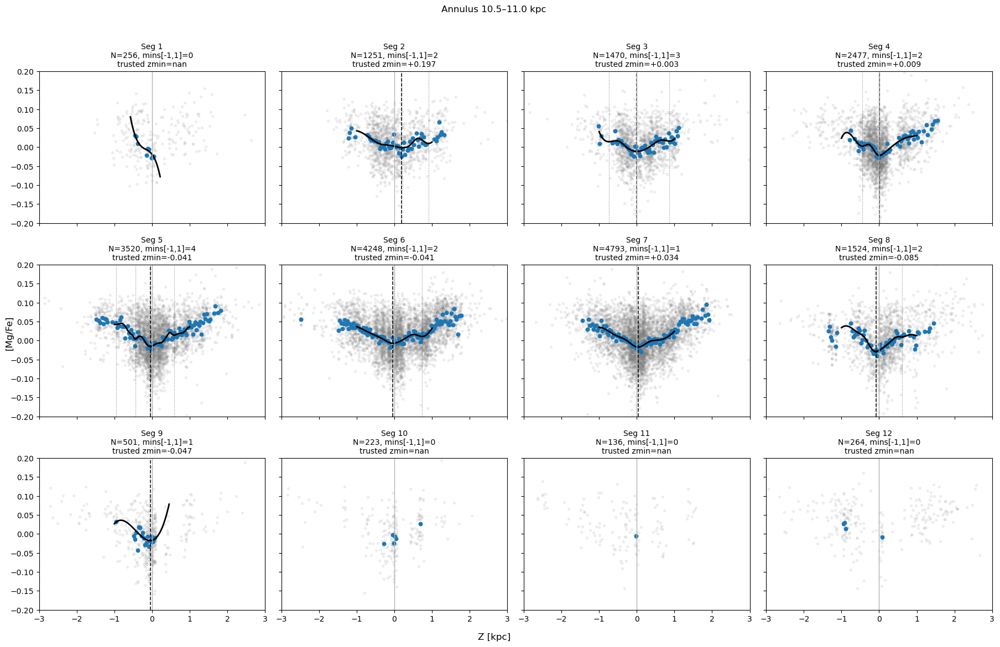

[{'seg': 1,
  'Nseg': 256,
  'status_raw': 'minimum_at_edge',
  'trusted_zmin': nan,
  'nmin_trusted': 0},
 {'seg': 2,
  'Nseg': 1251,
  'status_raw': 'ok',
  'trusted_zmin': 0.19736842105263142,
  'nmin_trusted': 2},
 {'seg': 3,
  'Nseg': 1470,
  'status_raw': 'ok',
  'trusted_zmin': 0.0031328320802004317,
  'nmin_trusted': 3},
 {'seg': 4,
  'Nseg': 2477,
  'status_raw': 'ok',
  'trusted_zmin': 0.009398496240601517,
  'nmin_trusted': 2},
 {'seg': 5,
  'Nseg': 3520,
  'status_raw': 'ok',
  'trusted_zmin': -0.0407268170426065,
  'nmin_trusted': 4},
 {'seg': 6,
  'Nseg': 4248,
  'status_raw': 'ok',
  'trusted_zmin': -0.0407268170426065,
  'nmin_trusted': 2},
 {'seg': 7,
  'Nseg': 4793,
  'status_raw': 'ok',
  'trusted_zmin': 0.034461152882205415,
  'nmin_trusted': 1},
 {'seg': 8,
  'Nseg': 1524,
  'status_raw': 'ok',
  'trusted_zmin': -0.08458646616541365,
  'nmin_trusted': 2},
 {'seg': 9,
  'Nseg': 501,
  'status_raw': 'ok',
  'trusted_zmin': -0.046992481203007586,
  'nmin_trusted': 1},

In [36]:
import numpy as np
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

# ---------------------------------
# choose annulus to inspect
# ---------------------------------
Rmin_focus, Rmax_focus = 10.5, 11.0

# use your segment list
seg_ids = SEG_PLOT

# ---------------------------------
# helper: trusted minimum in [-1,1]
# ---------------------------------
def trusted_minimum_from_fit(fit_obj, search_min=-1.0, search_max=1.0):
    if fit_obj is None:
        return np.nan, 0, None, None, None

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, 0, z_use, y_use, None

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        return np.nan, 0, z_use, y_use, None

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])
    return z0, n_local_min, z_use, y_use, z_candidates


# ---------------------------------
# make the figure
# ---------------------------------
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

nseg = len(seg_ids)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.6 * ncols, 3.8 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

results = []

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = seg_ids[j]
    mseg = mR & segm[seg_id]

    Zs = Z_star[mseg]
    Ys = mgfe_star[mseg]
    good = np.isfinite(Zs) & np.isfinite(Ys)
    Zs = Zs[good]
    Ys = Ys[good]

    Nseg = len(Zs)

    # raw stars
    ax.scatter(Zs, Ys, s=8, alpha=0.10, color="gray", label="raw stars")

    if Nseg < 15:
        ax.set_title(f"Seg {seg_id}\nN={Nseg} (too few stars)", fontsize=10)
        ax.axvline(0, color="0.7", lw=1)
        ax.set_xlim(-3, 3)
        ax.set_ylim(-0.2, 0.2)
        results.append({
            "seg": seg_id,
            "Nseg": Nseg,
            "status": "too_few_stars",
            "trusted_zmin": np.nan,
            "nmin_trusted": 0,
        })
        continue

    # binned means
    mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
    valid_pts = np.isfinite(mean_line) & (cnt_line >= 8)

    ax.scatter(
        z_centers[valid_pts],
        mean_line[valid_pts],
        s=22,
        color="tab:blue",
        label="binned means"
    )

    # old spline fit
    fit_old, st_old, z0_old = spline_fit_on_trend(
        z_centers=z_centers,
        trend=mean_line,
        cnt=cnt_line,
        sem=sem_line,
        zmin=-1.25,
        zmax=1.25,
        min_cnt=8,
        min_bins=8,
        spline_k=3,
        spline_s=None,
        n_eval=400,
        max_allowed_minima=99,   # allow them; we handle trusted selection manually
        edge_buffer=0.05,
    )

    z0_trusted, nmin_trusted, z_use, y_use, z_candidates = trusted_minimum_from_fit(
        fit_old,
        search_min=-1.0,
        search_max=1.0
    )

    # plot spline clipped to [-1,1]
    if fit_old is not None:
        zplot = fit_old["zgrid"]
        yplot = fit_old["ygrid"]

        mask_plot = (
            (zplot >= -1.0) & (zplot <= 1.0) &
            np.isfinite(yplot) &
            (yplot >= -0.08) & (yplot <= 0.08)
        )

        if np.sum(mask_plot) >= 2:
            ax.plot(
                zplot[mask_plot],
                yplot[mask_plot],
                color="black",
                lw=2,
                label=f"old spline ({st_old})"
            )
    


    # trusted zmin
    if np.isfinite(z0_trusted):
        ax.axvline(
            z0_trusted,
            color="black",
            ls="--",
            lw=1.2,
            alpha=0.9
        )

    # mark all trusted candidate minima if there are multiple
    if z_candidates is not None and len(z_candidates) > 1:
        for zc in z_candidates:
            ax.axvline(zc, color="black", ls=":", lw=0.9, alpha=0.45)

    ax.axvline(0, color="0.7", lw=1)

    title = (
        f"Seg {seg_id}\n"
        f"N={Nseg}, mins[-1,1]={nmin_trusted}\n"
        f"trusted zmin={z0_trusted:+.3f}" if np.isfinite(z0_trusted)
        else f"Seg {seg_id}\nN={Nseg}, mins[-1,1]={nmin_trusted}\ntrusted zmin=nan"
    )
    ax.set_title(title, fontsize=10)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.2)

    results.append({
        "seg": seg_id,
        "Nseg": Nseg,
        "status_raw": st_old,
        "trusted_zmin": z0_trusted,
        "nmin_trusted": nmin_trusted,
    })

fig.supxlabel("Z [kpc]")
fig.supylabel("[Mg/Fe]")
fig.suptitle(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.02)
fig.tight_layout()
plt.show()

results

In [37]:
def local_bowl_check(fit_obj, z0, halfwidth=0.25):
    if fit_obj is None or not np.isfinite(z0):
        return False

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    left_mask  = (zgrid >= z0 - halfwidth) & (zgrid < z0)
    right_mask = (zgrid > z0) & (zgrid <= z0 + halfwidth)

    if np.sum(left_mask) < 3 or np.sum(right_mask) < 3:
        return False

    y_left = ygrid[left_mask]
    y_right = ygrid[right_mask]

    # left side should trend downward toward z0
    left_ok = np.nanmean(np.diff(y_left)) < 0

    # right side should trend upward away from z0
    right_ok = np.nanmean(np.diff(y_right)) > 0

    return left_ok and right_ok

In [38]:
bowl_ok = local_bowl_check(fit_old, z0_trusted, halfwidth=0.25)
print("bowl_ok =", bowl_ok)

bowl_ok = False


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

In [40]:
def trusted_minimum_from_fit_strict(
    fit_obj,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
):
    """
    Find local minima only inside [search_min, search_max].

    Rules:
    - if no local minimum exists -> reject
    - if multiple minima exist -> choose the one closest to z=0
    - if chosen minimum lies too close to search boundary -> reject

    Returns
    -------
    z0_trusted : float
    n_local_min : int
    z_candidates : ndarray or None
    status : str
    """
    if fit_obj is None:
        return np.nan, 0, None, "fit_none"

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, 0, None, "too_few_grid_points"

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        return np.nan, 0, None, "no_local_minimum"

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])

    if (z0 <= search_min + edge_buffer_search) or (z0 >= search_max - edge_buffer_search):
        return np.nan, n_local_min, z_candidates, "minimum_near_search_edge"

    if n_local_min == 1:
        return z0, n_local_min, z_candidates, "ok_single_minimum"
    else:
        return z0, n_local_min, z_candidates, "ok_multiple_choose_nearest_zero"


def local_bowl_check(fit_obj, z0, halfwidth=0.25):
    """
    Check whether the spline looks locally bowl-shaped around z0.

    Left side should trend downward toward z0.
    Right side should trend upward away from z0.
    """
    if fit_obj is None or not np.isfinite(z0):
        return False

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    left_mask  = (zgrid >= z0 - halfwidth) & (zgrid < z0)
    right_mask = (zgrid > z0) & (zgrid <= z0 + halfwidth)

    if np.sum(left_mask) < 3 or np.sum(right_mask) < 3:
        return False

    y_left = ygrid[left_mask]
    y_right = ygrid[right_mask]

    left_ok = np.nanmean(np.diff(y_left)) < 0
    right_ok = np.nanmean(np.diff(y_right)) > 0

    return bool(left_ok and right_ok)

In [41]:
def compute_df_spline_trusted_strict(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    z_edges,
    R_edges=None,
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
    bowl_halfwidth=0.25,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    edge_buffer_fit=0.05,
):
    """
    Run the old spline method for every annulus/segment, but keep only
    trusted minima that pass strict quality checks.
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_min_trusted=np.nan,
                    nmin_trusted=0,
                    bowl_ok=False,
                    status_trusted="too_few_stars",
                    status_raw="too_few_stars",
                    z_min_raw=np.nan,
                ))
                continue

            Zs = Z_star[good]
            Ys = mgfe_star[good]

            mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)

            fit_obj, st_raw, z0_raw = spline_fit_on_trend(
                z_centers=z_centers,
                trend=mean_line,
                cnt=cnt_line,
                sem=sem_line,
                zmin=z_fit_min,
                zmax=z_fit_max,
                min_cnt=min_bin_count,
                min_bins=min_bins_for_fit,
                spline_k=spline_k,
                spline_s=spline_s,
                n_eval=n_eval,
                max_allowed_minima=99,   # allow them; strict filtering happens below
                edge_buffer=edge_buffer_fit,
            )

            z0_trusted, nmin_trusted, z_candidates, status_trusted = trusted_minimum_from_fit_strict(
                fit_obj,
                search_min=search_min,
                search_max=search_max,
                edge_buffer_search=edge_buffer_search,
            )

            bowl_ok = False
            if np.isfinite(z0_trusted):
                bowl_ok = local_bowl_check(
                    fit_obj,
                    z0_trusted,
                    halfwidth=bowl_halfwidth,
                )

                if not bowl_ok:
                    z0_trusted = np.nan
                    status_trusted = "failed_bowl_check"

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                Nseg=Nseg,
                z_min_trusted=z0_trusted,
                nmin_trusted=nmin_trusted,
                bowl_ok=bowl_ok,
                status_trusted=status_trusted,
                status_raw=st_raw,
                z_min_raw=z0_raw,
            ))

    return pd.DataFrame(rows)

In [42]:
df_trusted = compute_df_spline_trusted_strict(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,

    R_edges=None,              # or use your specific R_edges if you already have them
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,

    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
    bowl_halfwidth=0.25,

    spline_k=3,
    spline_s=None,
    n_eval=400,
    edge_buffer_fit=0.05,
)

df_trusted.head()

,Rmin,Rmax,seg,Nseg,z_min_trusted,nmin_trusted,bowl_ok,status_trusted,status_raw,z_min_raw
0,0.5,1.0,1,6,NaN,0,False,too_few_stars,too_few_stars,NaN
1,0.5,1.0,2,1,NaN,0,False,too_few_stars,too_few_stars,NaN
2,0.5,1.0,3,4,NaN,0,False,too_few_stars,too_few_stars,NaN
3,0.5,1.0,4,3,NaN,0,False,too_few_stars,too_few_stars,NaN
4,0.5,1.0,5,6,NaN,0,False,too_few_stars,too_few_stars,NaN


In [43]:
df_trusted["status_trusted"].value_counts(dropna=False)

status_trusted
fit_none                           161
ok_single_minimum                   89
ok_multiple_choose_nearest_zero     64
too_few_stars                       36
failed_bowl_check                    6
no_local_minimum                     4
Name: count, dtype: int64

In [44]:
df_trusted.loc[df_trusted["status_trusted"].str.startswith("ok", na=False)].head(20)

,Rmin,Rmax,seg,Nseg,z_min_trusted,nmin_trusted,bowl_ok,status_trusted,status_raw,z_min_raw
101,4.5,5.0,6,302,0.021930,1,True,ok_single_minimum,ok,0.019013
112,5.0,5.5,5,444,-0.065789,2,True,ok_multiple_choose_nearest_zero,ok,-0.064895
113,5.0,5.5,6,466,0.021930,1,True,ok_single_minimum,ok,0.024735
114,5.0,5.5,7,336,-0.153509,1,True,ok_single_minimum,ok,-0.151311
122,5.5,6.0,3,199,0.040727,1,True,ok_single_minimum,minimum_at_edge,NaN
123,5.5,6.0,4,429,0.184837,1,True,ok_single_minimum,ok,0.187428
124,5.5,6.0,5,666,-0.003133,1,True,ok_single_minimum,ok,-0.003787
125,5.5,6.0,6,791,0.003133,1,True,ok_single_minimum,ok,0.004917
126,5.5,6.0,7,613,-0.166040,4,True,ok_multiple_choose_nearest_zero,ok,-0.164104
127,5.5,6.0,8,270,0.028195,1,True,ok_single_minimum,ok,0.029562


In [45]:
def build_trusted_polar_map(
    df_trusted,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    """
    Build polar heatmap from trusted minima.
    """
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_trusted["Rmin"].tolist() + df_trusted["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = (df_trusted["status_trusted"].str.startswith("ok", na=False))

    for _, row in df_trusted.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_trusted"])
        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmin

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat

In [135]:
Zmap_trusted, theta_edges_trusted, R_edges_trusted, seg_plot_heat_trusted = build_trusted_polar_map(
    df_trusted=df_trusted,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=0.6,
)

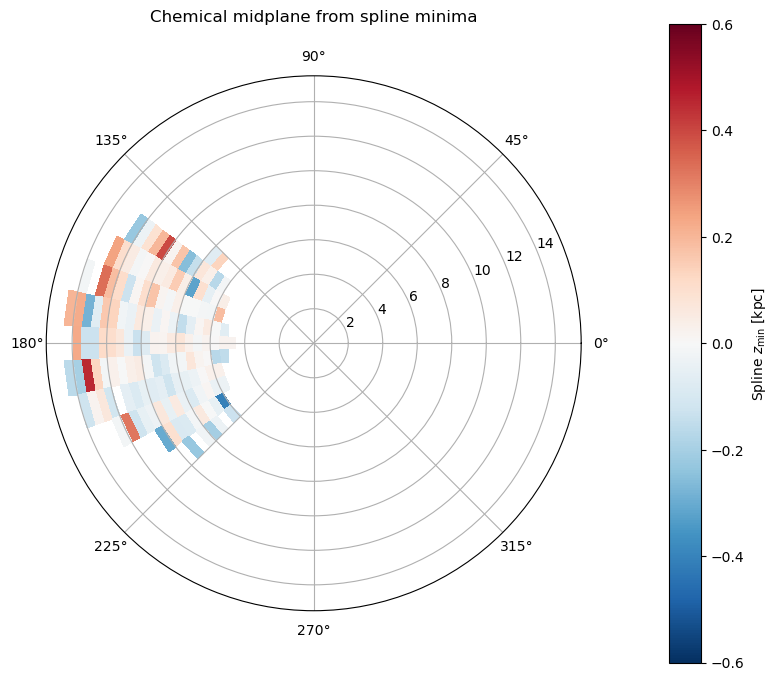

In [47]:
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_trusted,
    R_edges_trusted,
    Zmap_trusted,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.6,
    vmax=0.6,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Spline $z_{\min}$ [kpc]")

ax.set_title("Chemical midplane from spline minima", pad=20)
plt.tight_layout()
plt.show()

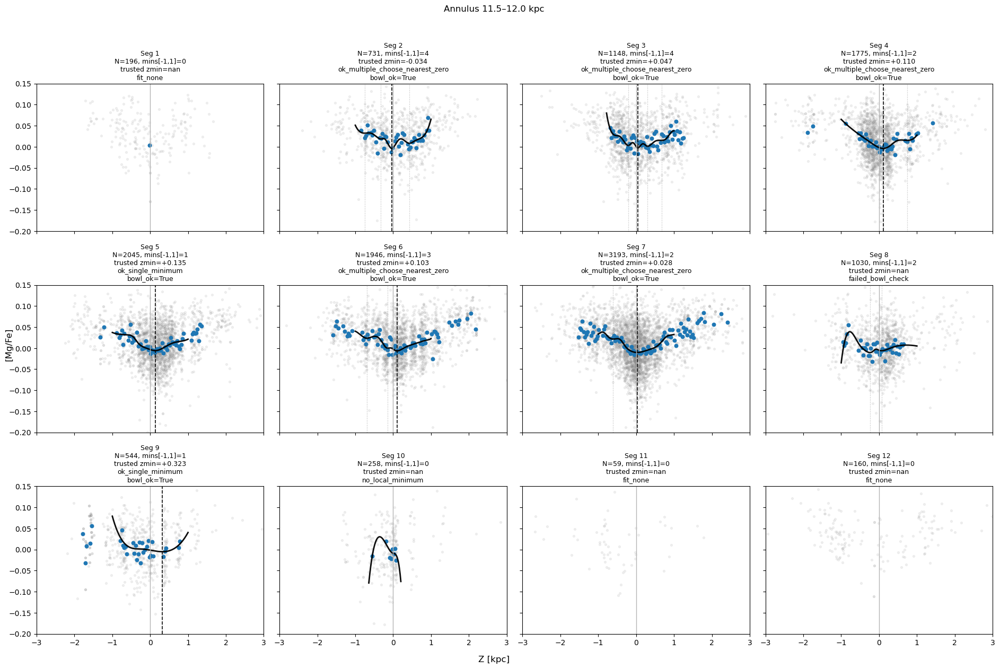

[{'seg': 1,
  'Nseg': 196,
  'status_raw': 'too_few_bins',
  'status_trusted': 'fit_none',
  'trusted_zmin': nan,
  'nmin_trusted': 0,
  'bowl_ok': False,
  'z_candidates': None},
 {'seg': 2,
  'Nseg': 731,
  'status_raw': 'ok',
  'status_trusted': 'ok_multiple_choose_nearest_zero',
  'trusted_zmin': -0.03446115288220564,
  'nmin_trusted': 4,
  'bowl_ok': True,
  'z_candidates': array([-0.75501253, -0.3226817 , -0.03446115,  0.42919799])},
 {'seg': 3,
  'Nseg': 1148,
  'status_raw': 'ok',
  'status_trusted': 'ok_multiple_choose_nearest_zero',
  'trusted_zmin': 0.046992481203007364,
  'nmin_trusted': 4,
  'bowl_ok': True,
  'z_candidates': array([-0.20363409,  0.04699248,  0.30388471,  0.6735589 ])},
 {'seg': 4,
  'Nseg': 1775,
  'status_raw': 'ok',
  'status_trusted': 'ok_multiple_choose_nearest_zero',
  'trusted_zmin': 0.10964912280701755,
  'nmin_trusted': 2,
  'bowl_ok': True,
  'z_candidates': array([0.10964912, 0.74874687])},
 {'seg': 5,
  'Nseg': 2045,
  'status_raw': 'ok',
  'st

In [48]:
import numpy as np
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

# --------------------------------------------------
# choose annulus
# --------------------------------------------------
Rmin_focus, Rmax_focus = 11.5, 12.0
seg_ids = SEG_PLOT

# --------------------------------------------------
# helper: trusted minimum with strict rules
# --------------------------------------------------
def trusted_minimum_from_fit_strict(
    fit_obj,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
):
    if fit_obj is None:
        return np.nan, 0, None, "fit_none", None, None

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, 0, None, "too_few_grid_points", z_use, y_use

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        return np.nan, 0, None, "no_local_minimum", z_use, y_use

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])

    if (z0 <= search_min + edge_buffer_search) or (z0 >= search_max - edge_buffer_search):
        return np.nan, n_local_min, z_candidates, "minimum_near_search_edge", z_use, y_use

    if n_local_min == 1:
        return z0, n_local_min, z_candidates, "ok_single_minimum", z_use, y_use
    else:
        return z0, n_local_min, z_candidates, "ok_multiple_choose_nearest_zero", z_use, y_use


def local_bowl_check(fit_obj, z0, halfwidth=0.25):
    if fit_obj is None or not np.isfinite(z0):
        return False

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    left_mask  = (zgrid >= z0 - halfwidth) & (zgrid < z0)
    right_mask = (zgrid > z0) & (zgrid <= z0 + halfwidth)

    if np.sum(left_mask) < 3 or np.sum(right_mask) < 3:
        return False

    y_left = ygrid[left_mask]
    y_right = ygrid[right_mask]

    left_ok = np.nanmean(np.diff(y_left)) < 0
    right_ok = np.nanmean(np.diff(y_right)) > 0

    return bool(left_ok and right_ok)

# --------------------------------------------------
# plot one annulus, one panel per segment
# --------------------------------------------------
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

nseg = len(seg_ids)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.8 * ncols, 4.1 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

results = []

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = seg_ids[j]
    mseg = mR & segm[seg_id]

    Zs = Z_star[mseg]
    Ys = mgfe_star[mseg]
    good = np.isfinite(Zs) & np.isfinite(Ys)
    Zs = Zs[good]
    Ys = Ys[good]

    Nseg = len(Zs)

    # raw stars
    ax.scatter(Zs, Ys, s=8, alpha=0.10, color="gray")

    if Nseg < 15:
        ax.set_title(f"Seg {seg_id}\nN={Nseg}\ntoo few stars", fontsize=10)
        ax.axvline(0, color="0.7", lw=1)
        ax.set_xlim(-3, 3)
        ax.set_ylim(-0.2, 0.15)
        results.append({
            "seg": seg_id,
            "Nseg": Nseg,
            "status_trusted": "too_few_stars",
            "trusted_zmin": np.nan,
            "nmin_trusted": 0,
            "bowl_ok": False,
        })
        continue

    # binned means
    mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
    valid_pts = np.isfinite(mean_line) & (cnt_line >= 8)

    ax.scatter(
        z_centers[valid_pts],
        mean_line[valid_pts],
        s=22,
        color="tab:blue",
    )

    # spline fit
    fit_old, st_old, z0_old = spline_fit_on_trend(
        z_centers=z_centers,
        trend=mean_line,
        cnt=cnt_line,
        sem=sem_line,
        zmin=-1.25,
        zmax=1.25,
        min_cnt=8,
        min_bins=8,
        spline_k=3,
        spline_s=None,
        n_eval=400,
        max_allowed_minima=99,   # allow them; strict filtering is manual below
        edge_buffer=0.05,
    )

    # strict trusted minimum
    z0_trusted, nmin_trusted, z_candidates, status_trusted, z_use, y_use = trusted_minimum_from_fit_strict(
        fit_old,
        search_min=-1.0,
        search_max=1.0,
        edge_buffer_search=0.10,
    )

    bowl_ok = False
    if np.isfinite(z0_trusted):
        bowl_ok = local_bowl_check(fit_old, z0_trusted, halfwidth=0.25)
        if not bowl_ok:
            status_trusted = "failed_bowl_check"
            z0_trusted = np.nan

    # plot spline clipped to [-1,1] and reasonable y-range
    if fit_old is not None:
        zplot = np.asarray(fit_old["zgrid"], float)
        yplot = np.asarray(fit_old["ygrid"], float)

        mask_plot = (
            (zplot >= -1.0) & (zplot <= 1.0) &
            np.isfinite(yplot) &
            (yplot >= -0.08) & (yplot <= 0.08)
        )

        idx = np.where(mask_plot)[0]
        if len(idx) >= 2:
            splits = np.where(np.diff(idx) > 1)[0] + 1
            chunks = np.split(idx, splits)

            for k, chunk in enumerate(chunks):
                if len(chunk) >= 2:
                    ax.plot(
                        zplot[chunk],
                        yplot[chunk],
                        color="black",
                        lw=2,
                        alpha=0.95,
                    )

    # candidate minima
    if z_candidates is not None:
        for zc in np.atleast_1d(z_candidates):
            ax.axvline(zc, color="0.5", ls=":", lw=0.9, alpha=0.55)

    # chosen trusted minimum
    if np.isfinite(z0_trusted):
        ax.axvline(z0_trusted, color="black", ls="--", lw=1.2, alpha=0.95)

    ax.axvline(0, color="0.7", lw=1)

    title_lines = [
        f"Seg {seg_id}",
        f"N={Nseg}, mins[-1,1]={nmin_trusted}",
    ]

    if np.isfinite(z0_trusted):
        title_lines.append(f"trusted zmin={z0_trusted:+.3f}")
    else:
        title_lines.append("trusted zmin=nan")

    title_lines.append(status_trusted)

    if status_trusted.startswith("ok"):
        title_lines.append(f"bowl_ok={bowl_ok}")

    ax.set_title("\n".join(title_lines), fontsize=9)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.15)

    results.append({
        "seg": seg_id,
        "Nseg": Nseg,
        "status_raw": st_old,
        "status_trusted": status_trusted,
        "trusted_zmin": z0_trusted,
        "nmin_trusted": nmin_trusted,
        "bowl_ok": bowl_ok,
        "z_candidates": z_candidates,
    })

fig.supxlabel("Z [kpc]")
fig.supylabel("[Mg/Fe]")
fig.suptitle(f"Annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.02)
fig.tight_layout()
plt.show()

results

status_trusted
fit_none                       161
ok_single_minimum               89
ok_multiple_choose_lowest_y     67
too_few_stars                   36
no_local_minimum                 4
failed_bowl_check                3
Name: count, dtype: int64


,Rmin,Rmax,seg,Nseg,z_min_trusted,y_min_trusted,nmin_trusted,bowl_ok,status_trusted,status_raw,z_min_raw
0,0.5,1.0,1,6,NaN,NaN,0,False,too_few_stars,too_few_stars,NaN
1,0.5,1.0,2,1,NaN,NaN,0,False,too_few_stars,too_few_stars,NaN
2,0.5,1.0,3,4,NaN,NaN,0,False,too_few_stars,too_few_stars,NaN
3,0.5,1.0,4,3,NaN,NaN,0,False,too_few_stars,too_few_stars,NaN
4,0.5,1.0,5,6,NaN,NaN,0,False,too_few_stars,too_few_stars,NaN


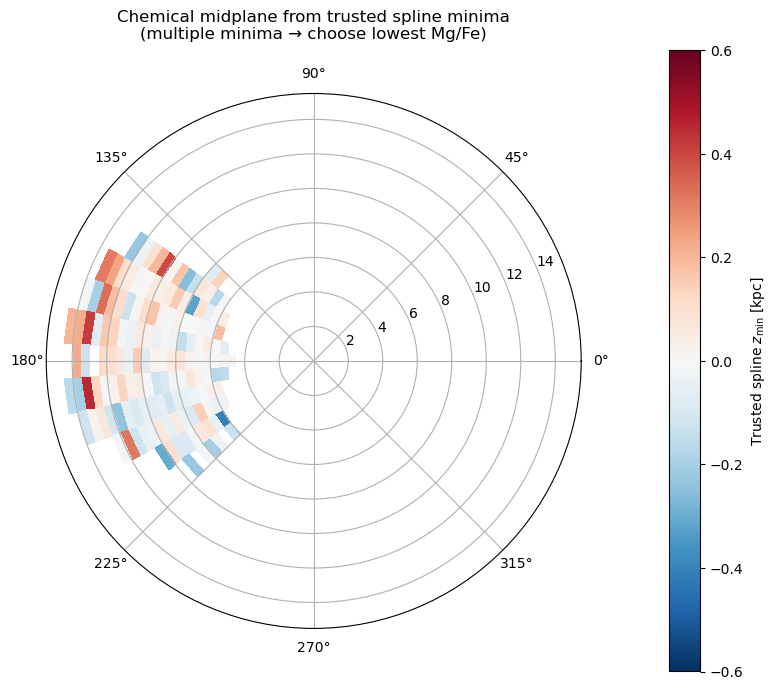

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

# =========================================================
# SETTINGS
# =========================================================
SEARCH_MIN = -1.0
SEARCH_MAX = 1.0
EDGE_BUFFER_SEARCH = 0.10
BOWL_HALFWIDTH = 0.25

MINN_SEG_TOTAL = 15
MIN_BIN_COUNT = 8
MIN_BINS_FOR_FIT = 8

Z_FIT_MIN = -1.25
Z_FIT_MAX = 1.25

SPLINE_K = 3
SPLINE_S = None
N_EVAL = 400
EDGE_BUFFER_FIT = 0.05

ZLIM_HEATMAP = 0.6


# =========================================================
# HELPER: choose the local minimum with LOWEST Mg/Fe value
# =========================================================
def trusted_minimum_from_fit_lowest_y(
    fit_obj,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
):
    """
    Find local minima only inside [search_min, search_max].

    New rule:
    - if multiple minima exist, choose the one with the LOWEST y value
      (lowest Mg/Fe), not the one closest to zero.

    Reject if:
    - no local minimum exists
    - chosen minimum is too close to the search boundary
    """
    if fit_obj is None:
        return np.nan, np.nan, 0, None, "fit_none", None, None

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    mask = (zgrid >= search_min) & (zgrid <= search_max)
    z_use = zgrid[mask]
    y_use = ygrid[mask]

    if len(z_use) < 3:
        return np.nan, np.nan, 0, None, "too_few_grid_points", z_use, y_use

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        return np.nan, np.nan, 0, None, "no_local_minimum", z_use, y_use

    z_candidates = z_use[idx_local_min]
    y_candidates = y_use[idx_local_min]

    # NEW RULE: pick the minimum with the LOWEST Mg/Fe value
    best = np.argmin(y_candidates)
    z0 = float(z_candidates[best])
    y0 = float(y_candidates[best])

    if (z0 <= search_min + edge_buffer_search) or (z0 >= search_max - edge_buffer_search):
        return np.nan, np.nan, n_local_min, z_candidates, "minimum_near_search_edge", z_use, y_use

    if n_local_min == 1:
        status = "ok_single_minimum"
    else:
        status = "ok_multiple_choose_lowest_y"

    return z0, y0, n_local_min, z_candidates, status, z_use, y_use


# =========================================================
# HELPER: local bowl check
# =========================================================
def local_bowl_check(fit_obj, z0, halfwidth=0.25):
    """
    Require the curve to look like a local bowl around z0:
    - left side trends downward toward z0
    - right side trends upward away from z0
    """
    if fit_obj is None or not np.isfinite(z0):
        return False

    zgrid = np.asarray(fit_obj["zgrid"], float)
    ygrid = np.asarray(fit_obj["ygrid"], float)

    left_mask  = (zgrid >= z0 - halfwidth) & (zgrid < z0)
    right_mask = (zgrid > z0) & (zgrid <= z0 + halfwidth)

    if np.sum(left_mask) < 3 or np.sum(right_mask) < 3:
        return False

    y_left = ygrid[left_mask]
    y_right = ygrid[right_mask]

    left_ok = np.nanmean(np.diff(y_left)) < 0
    right_ok = np.nanmean(np.diff(y_right)) > 0

    return bool(left_ok and right_ok)


# =========================================================
# MAIN: compute trusted spline minima for all annuli/segments
# =========================================================
def compute_df_spline_trusted_lowest_y(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    z_edges,
    R_edges=None,
    minN_seg_total=15,
    min_bin_count=8,
    z_fit_min=-1.25,
    z_fit_max=1.25,
    min_bins_for_fit=8,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
    bowl_halfwidth=0.25,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    edge_buffer_fit=0.05,
):
    """
    For each annulus/segment:
    1. bin stars in Z
    2. compute mean Mg/Fe per bin
    3. fit spline to binned trend
    4. search for local minima only in [search_min, search_max]
    5. if multiple minima, choose the one with LOWEST Mg/Fe
    6. reject near-edge minima
    7. reject minima that fail bowl check
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)
            Nseg = int(np.sum(good))

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_min_trusted=np.nan,
                    y_min_trusted=np.nan,
                    nmin_trusted=0,
                    bowl_ok=False,
                    status_trusted="too_few_stars",
                    status_raw="too_few_stars",
                    z_min_raw=np.nan,
                ))
                continue

            Zs = Z_star[good]
            Ys = mgfe_star[good]

            mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)

            fit_obj, st_raw, z0_raw = spline_fit_on_trend(
                z_centers=z_centers,
                trend=mean_line,
                cnt=cnt_line,
                sem=sem_line,
                zmin=z_fit_min,
                zmax=z_fit_max,
                min_cnt=min_bin_count,
                min_bins=min_bins_for_fit,
                spline_k=spline_k,
                spline_s=spline_s,
                n_eval=n_eval,
                max_allowed_minima=99,   # allow multiple; filter later
                edge_buffer=edge_buffer_fit,
            )

            z0_trusted, y0_trusted, nmin_trusted, z_candidates, status_trusted, z_use, y_use = (
                trusted_minimum_from_fit_lowest_y(
                    fit_obj,
                    search_min=search_min,
                    search_max=search_max,
                    edge_buffer_search=edge_buffer_search,
                )
            )

            bowl_ok = False
            if np.isfinite(z0_trusted):
                bowl_ok = local_bowl_check(
                    fit_obj,
                    z0_trusted,
                    halfwidth=bowl_halfwidth,
                )

                if not bowl_ok:
                    z0_trusted = np.nan
                    y0_trusted = np.nan
                    status_trusted = "failed_bowl_check"

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                Nseg=Nseg,
                z_min_trusted=z0_trusted,
                y_min_trusted=y0_trusted,
                nmin_trusted=nmin_trusted,
                bowl_ok=bowl_ok,
                status_trusted=status_trusted,
                status_raw=st_raw,
                z_min_raw=z0_raw,
            ))

    return pd.DataFrame(rows)


# =========================================================
# BUILD POLAR MAP
# =========================================================
def build_trusted_polar_map(
    df_trusted,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    """
    Build polar heatmap from accepted trusted minima.
    """
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_trusted["Rmin"].tolist() + df_trusted["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = df_trusted["status_trusted"].str.startswith("ok", na=False)

    for _, row in df_trusted.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_trusted"])
        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmin

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat


# =========================================================
# RUN THE PIPELINE
# =========================================================
df_trusted_lowesty = compute_df_spline_trusted_lowest_y(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    z_edges=z_edges,

    R_edges=None,  # or pass your custom R_edges
    minN_seg_total=MINN_SEG_TOTAL,
    min_bin_count=MIN_BIN_COUNT,
    z_fit_min=Z_FIT_MIN,
    z_fit_max=Z_FIT_MAX,
    min_bins_for_fit=MIN_BINS_FOR_FIT,

    search_min=SEARCH_MIN,
    search_max=SEARCH_MAX,
    edge_buffer_search=EDGE_BUFFER_SEARCH,
    bowl_halfwidth=BOWL_HALFWIDTH,

    spline_k=SPLINE_K,
    spline_s=SPLINE_S,
    n_eval=N_EVAL,
    edge_buffer_fit=EDGE_BUFFER_FIT,
)

print(df_trusted_lowesty["status_trusted"].value_counts(dropna=False))
display(df_trusted_lowesty.head())


# =========================================================
# BUILD MAP ARRAYS
# =========================================================
Zmap_trusted_lowesty, theta_edges_trusted_lowesty, R_edges_trusted_lowesty, seg_plot_heat_trusted_lowesty = (
    build_trusted_polar_map(
        df_trusted=df_trusted_lowesty,
        crowd_bounds=crowd_bounds,
        seg_plot=SEG_PLOT,
        seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
        zlim=ZLIM_HEATMAP,
    )
)


# =========================================================
# PLOT HEATMAP
# =========================================================
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_trusted_lowesty,
    R_edges_trusted_lowesty,
    Zmap_trusted_lowesty,
    shading="auto",
    cmap="RdBu_r",
    vmin=-ZLIM_HEATMAP,
    vmax= ZLIM_HEATMAP,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Trusted spline $z_{\min}$ [kpc]")

ax.set_title("Chemical midplane from trusted spline minima\n(multiple minima → choose lowest Mg/Fe)", pad=20)
plt.tight_layout()
plt.show()

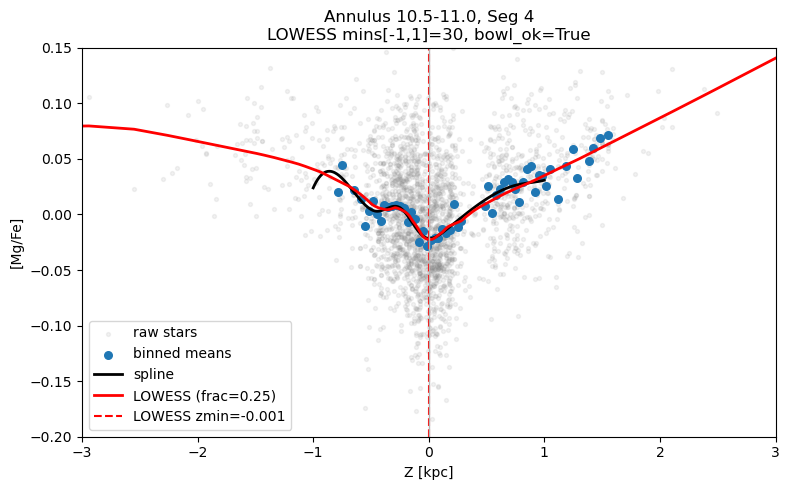

LOWESS zmin: -0.00062013509657897
LOWESS n minima: 30
LOWESS bowl_ok: True


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

from src.fitting import (
    binned_mean_count_sem,
    spline_fit_on_trend,
)

# -----------------------------
# choose annulus + segment
# -----------------------------
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
Ys = mgfe_star[mseg]

good = np.isfinite(Zs) & np.isfinite(Ys)
Zs = Zs[good]
Ys = Ys[good]

# -----------------------------
# binned means (for comparison)
# -----------------------------
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
mean_line, cnt_line, sem_line = binned_mean_count_sem(Zs, Ys, z_edges)
valid_pts = np.isfinite(mean_line) & (cnt_line >= 8)

# -----------------------------
# spline (your current method)
# -----------------------------
fit_old, st_old, z0_old = spline_fit_on_trend(
    z_centers=z_centers,
    trend=mean_line,
    cnt=cnt_line,
    sem=sem_line,
    zmin=-1.25,
    zmax=1.25,
    min_cnt=8,
    min_bins=8,
    spline_k=3,
    spline_s=None,
    n_eval=400,
    max_allowed_minima=99,
    edge_buffer=0.05,
)

# -----------------------------
# LOWESS on raw stars (NO BINNING)
# -----------------------------
# frac controls smoothing strength (IMPORTANT)
lowess_frac = 0.25   # try 0.2–0.4

lowess_fit = lowess(
    Ys, Zs,
    frac=lowess_frac,
    return_sorted=True
)

z_lowess = lowess_fit[:, 0]
y_lowess = lowess_fit[:, 1]

# -----------------------------
# find LOWESS minimum in [-1,1]
# -----------------------------
mask_trusted = (z_lowess >= -1.0) & (z_lowess <= 1.0)

z_low = z_lowess[mask_trusted]
y_low = y_lowess[mask_trusted]

z0_lowess = np.nan
nmin_lowess = 0

if len(z_low) >= 3:
    is_local_min = (
        (y_low[1:-1] < y_low[:-2]) &
        (y_low[1:-1] < y_low[2:])
    )
    idx = np.where(is_local_min)[0] + 1
    nmin_lowess = len(idx)

    if nmin_lowess >= 1:
        z_candidates = z_low[idx]
        z0_lowess = float(z_candidates[np.argmin(np.abs(z_candidates))])

# -----------------------------
# simple bowl check for LOWESS
# -----------------------------
def lowess_bowl_check(z, y, z0, halfwidth=0.25):
    if not np.isfinite(z0):
        return False

    left = (z >= z0 - halfwidth) & (z < z0)
    right = (z > z0) & (z <= z0 + halfwidth)

    if np.sum(left) < 3 or np.sum(right) < 3:
        return False

    left_ok = np.nanmean(np.diff(y[left])) < 0
    right_ok = np.nanmean(np.diff(y[right])) > 0

    return left_ok and right_ok

bowl_ok_lowess = lowess_bowl_check(z_lowess, y_lowess, z0_lowess)

# -----------------------------
# PLOT EVERYTHING
# -----------------------------
plt.figure(figsize=(8, 5))

# raw stars
plt.scatter(Zs, Ys, s=8, alpha=0.10, color="gray", label="raw stars")

# binned means
plt.scatter(
    z_centers[valid_pts],
    mean_line[valid_pts],
    s=30,
    color="tab:blue",
    label="binned means"
)

# spline (clipped)
if fit_old is not None:
    mask_plot = (fit_old["zgrid"] >= -1.0) & (fit_old["zgrid"] <= 1.0)
    plt.plot(
        fit_old["zgrid"][mask_plot],
        fit_old["ygrid"][mask_plot],
        color="black",
        lw=2,
        label=f"spline"
    )

# LOWESS curve
plt.plot(
    z_lowess,
    y_lowess,
    color="red",
    lw=2,
    label=f"LOWESS (frac={lowess_frac})"
)

# minima
if np.isfinite(z0_lowess):
    plt.axvline(
        z0_lowess,
        color="red",
        ls="--",
        label=f"LOWESS zmin={z0_lowess:+.3f}"
    )

# reference line
plt.axvline(0, color="0.7", lw=1)

plt.xlim(-3, 3)
plt.ylim(-0.2, 0.15)

plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")

plt.title(
    f"Annulus {Rmin_focus:.1f}-{Rmax_focus:.1f}, Seg {seg_id}\n"
    f"LOWESS mins[-1,1]={nmin_lowess}, bowl_ok={bowl_ok_lowess}"
)

plt.legend()
plt.tight_layout()
plt.show()

print("LOWESS zmin:", z0_lowess)
print("LOWESS n minima:", nmin_lowess)
print("LOWESS bowl_ok:", bowl_ok_lowess)

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.nonparametric.smoothers_lowess import lowess

In [52]:
def trusted_minimum_from_curve_strict(
    z_curve,
    y_curve,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
):
    """
    Find local minima only inside [search_min, search_max].

    Rules:
    - if no local minimum exists -> reject
    - if multiple minima exist -> choose the one closest to z=0
    - if chosen minimum lies too close to search boundary -> reject

    Returns
    -------
    z0_trusted : float
    n_local_min : int
    z_candidates : ndarray or None
    status : str
    z_use, y_use : arrays in trusted window
    """
    z_curve = np.asarray(z_curve, float)
    y_curve = np.asarray(y_curve, float)

    good = np.isfinite(z_curve) & np.isfinite(y_curve)
    z_curve = z_curve[good]
    y_curve = y_curve[good]

    mask = (z_curve >= search_min) & (z_curve <= search_max)
    z_use = z_curve[mask]
    y_use = y_curve[mask]

    if len(z_use) < 3:
        return np.nan, 0, None, "too_few_grid_points", z_use, y_use

    is_local_min = (
        (y_use[1:-1] < y_use[:-2]) &
        (y_use[1:-1] < y_use[2:])
    )
    idx_local_min = np.where(is_local_min)[0] + 1
    n_local_min = len(idx_local_min)

    if n_local_min == 0:
        return np.nan, 0, None, "no_local_minimum", z_use, y_use

    z_candidates = z_use[idx_local_min]
    z0 = float(z_candidates[np.argmin(np.abs(z_candidates))])

    if (z0 <= search_min + edge_buffer_search) or (z0 >= search_max - edge_buffer_search):
        return np.nan, n_local_min, z_candidates, "minimum_near_search_edge", z_use, y_use

    if n_local_min == 1:
        return z0, n_local_min, z_candidates, "ok_single_minimum", z_use, y_use
    else:
        return z0, n_local_min, z_candidates, "ok_multiple_choose_nearest_zero", z_use, y_use


def local_bowl_check_curve(z_curve, y_curve, z0, halfwidth=0.25):
    """
    Check whether the curve looks locally bowl-shaped around z0.
    """
    if not np.isfinite(z0):
        return False

    z_curve = np.asarray(z_curve, float)
    y_curve = np.asarray(y_curve, float)

    good = np.isfinite(z_curve) & np.isfinite(y_curve)
    z_curve = z_curve[good]
    y_curve = y_curve[good]

    left_mask  = (z_curve >= z0 - halfwidth) & (z_curve < z0)
    right_mask = (z_curve > z0) & (z_curve <= z0 + halfwidth)

    if np.sum(left_mask) < 3 or np.sum(right_mask) < 3:
        return False

    y_left = y_curve[left_mask]
    y_right = y_curve[right_mask]

    left_ok = np.nanmean(np.diff(y_left)) < 0
    right_ok = np.nanmean(np.diff(y_right)) > 0

    return bool(left_ok and right_ok)

In [53]:
def compute_df_lowess_trusted_strict(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    R_edges=None,
    minN_seg_total=15,
    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
    bowl_halfwidth=0.25,
    lowess_frac=0.25,
):
    """
    Run LOWESS on raw stars for every annulus/segment, then keep only
    trusted minima that pass strict quality checks.
    """
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)

            Zs = np.asarray(Z_star[good], float)
            Ys = np.asarray(mgfe_star[good], float)
            Nseg = len(Zs)

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_min_trusted=np.nan,
                    nmin_trusted=0,
                    bowl_ok=False,
                    status_trusted="too_few_stars",
                ))
                continue

            order = np.argsort(Zs)
            Zs = Zs[order]
            Ys = Ys[order]

            try:
                lowess_fit = lowess(
                    Ys, Zs,
                    frac=lowess_frac,
                    return_sorted=True
                )
            except Exception:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_min_trusted=np.nan,
                    nmin_trusted=0,
                    bowl_ok=False,
                    status_trusted="lowess_failed",
                ))
                continue

            z_curve = lowess_fit[:, 0]
            y_curve = lowess_fit[:, 1]

            z0_trusted, nmin_trusted, z_candidates, status_trusted, z_use, y_use = (
                trusted_minimum_from_curve_strict(
                    z_curve,
                    y_curve,
                    search_min=search_min,
                    search_max=search_max,
                    edge_buffer_search=edge_buffer_search,
                )
            )

            bowl_ok = False
            if np.isfinite(z0_trusted):
                bowl_ok = local_bowl_check_curve(
                    z_curve,
                    y_curve,
                    z0_trusted,
                    halfwidth=bowl_halfwidth,
                )
                if not bowl_ok:
                    z0_trusted = np.nan
                    status_trusted = "failed_bowl_check"

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                Nseg=Nseg,
                z_min_trusted=z0_trusted,
                nmin_trusted=nmin_trusted,
                bowl_ok=bowl_ok,
                status_trusted=status_trusted,
            ))

    return pd.DataFrame(rows)

In [54]:
df_lowess = compute_df_lowess_trusted_strict(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,

    R_edges=None,              # or pass your preferred R_edges
    minN_seg_total=15,

    search_min=-1.0,
    search_max=1.0,
    edge_buffer_search=0.10,
    bowl_halfwidth=0.25,

    lowess_frac=0.25,          # try 0.20, 0.25, 0.30
)

df_lowess.head()

,Rmin,Rmax,seg,Nseg,z_min_trusted,nmin_trusted,bowl_ok,status_trusted
0,0.5,1.0,1,6,NaN,0,False,too_few_stars
1,0.5,1.0,2,1,NaN,0,False,too_few_stars
2,0.5,1.0,3,4,NaN,0,False,too_few_stars
3,0.5,1.0,4,3,NaN,0,False,too_few_stars
4,0.5,1.0,5,6,NaN,0,False,too_few_stars


In [55]:
def build_lowess_polar_map(
    df_lowess,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    """
    Build polar heatmap from trusted LOWESS minima.
    """
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_lowess["Rmin"].tolist() + df_lowess["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = df_lowess["status_trusted"].str.startswith("ok", na=False)

    for _, row in df_lowess.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmin = float(row["z_min_trusted"])
        if not np.isfinite(zmin):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmin

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat

In [56]:
Zmap_lowess, theta_edges_lowess, R_edges_lowess, seg_plot_heat_lowess = build_lowess_polar_map(
    df_lowess=df_lowess,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=0.6,
)

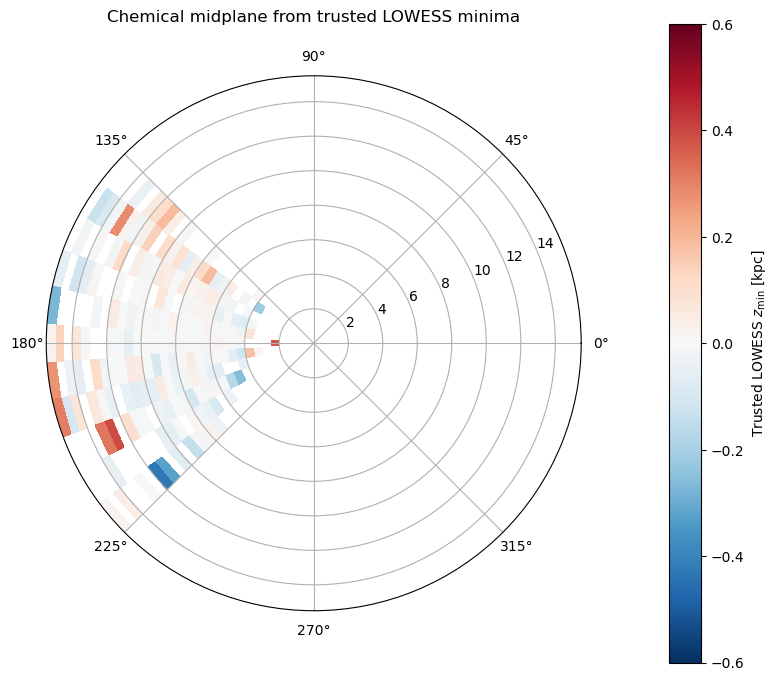

In [57]:
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_lowess,
    R_edges_lowess,
    Zmap_lowess,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.6,
    vmax=0.6,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"Trusted LOWESS $z_{\min}$ [kpc]")

ax.set_title("Chemical midplane from trusted LOWESS minima", pad=20)
plt.tight_layout()
plt.show()

In [58]:
df_lowess["status_trusted"].value_counts()


status_trusted
ok_multiple_choose_nearest_zero    193
failed_bowl_check                  127
too_few_stars                       36
ok_single_minimum                    4
Name: count, dtype: int64

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture

In [60]:
def fit_gmm_2d_midplane(
    Zs,
    MgFes,
    n_components=2,
    random_state=42,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
):
    """
    Fit a 2D GMM in (Z, MgFe) and choose the component that best represents
    the central chemically thin-disk population.

    Selection rule:
    - prefer components near Z=0
    - among those, prefer lower Mg/Fe
    - reject if chosen component is too low-weight, too broad in Z, or mean Z
      lies too close to / outside the trusted window

    Returns
    -------
    result : dict
        Includes fit object, chosen component index, z_mid, status, etc.
    """
    Zs = np.asarray(Zs, float)
    MgFes = np.asarray(MgFes, float)

    good = np.isfinite(Zs) & np.isfinite(MgFes)
    Zs = Zs[good]
    MgFes = MgFes[good]

    if len(Zs) < max(30, 10 * n_components):
        return {
            "status": "too_few_stars",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    X = np.column_stack([Zs, MgFes])

    try:
        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type="full",
            reg_covar=reg_covar,
            random_state=random_state,
        )
        gmm.fit(X)
    except Exception:
        return {
            "status": "fit_failed",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    means = gmm.means_              # shape (k, 2) -> columns: Z, MgFe
    covs = gmm.covariances_
    weights = gmm.weights_

    mu_z = means[:, 0]
    mu_mgfe = means[:, 1]
    sigma_z = np.sqrt(covs[:, 0, 0])

    # Reject components whose Z mean is way outside the trusted region
    inside = (mu_z >= search_min) & (mu_z <= search_max)

    if not np.any(inside):
        return {
            "status": "no_component_in_search_window",
            "z_mid": np.nan,
            "gmm": gmm,
            "chosen_idx": None,
            "means": means,
            "weights": weights,
            "sigma_z": sigma_z,
        }

    # Score components:
    #   smaller |mu_z| is better
    #   smaller mu_mgfe is better
    # This favors central + low-Mg/Fe components.
    score = np.full(len(mu_z), np.inf)
    score[inside] = np.abs(mu_z[inside]) + 0.5 * mu_mgfe[inside]

    chosen_idx = int(np.argmin(score))
    z_mid = float(mu_z[chosen_idx])

    # Quality checks
    if weights[chosen_idx] < min_component_weight:
        status = "chosen_component_low_weight"
        z_mid = np.nan
    elif sigma_z[chosen_idx] > max_sigma_z:
        status = "chosen_component_too_broad"
        z_mid = np.nan
    elif (z_mid <= search_min + 0.05) or (z_mid >= search_max - 0.05):
        status = "chosen_component_near_edge"
        z_mid = np.nan
    else:
        status = "ok"

    return {
        "status": status,
        "z_mid": z_mid,
        "gmm": gmm,
        "chosen_idx": chosen_idx,
        "means": means,
        "weights": weights,
        "sigma_z": sigma_z,
        "mu_z": mu_z,
        "mu_mgfe": mu_mgfe,
    }

status: ok
z_mid: -0.10055761644237941
chosen_idx: 0


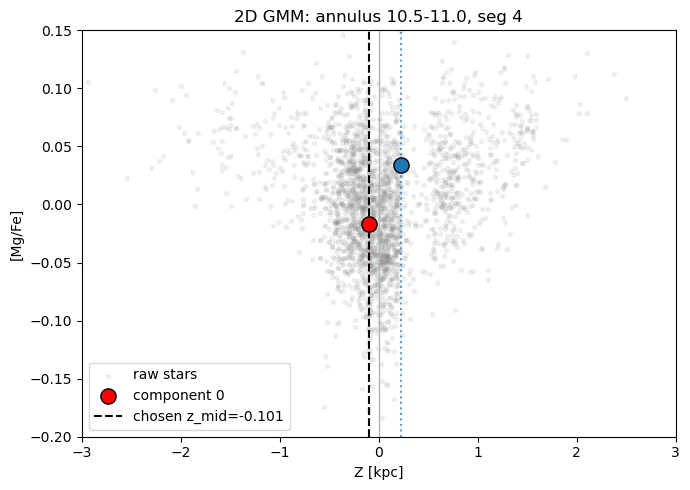

In [61]:
# choose annulus + segment
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = Z_star[mseg]
MgFes = mgfe_star[mseg]

res_gmm = fit_gmm_2d_midplane(
    Zs,
    MgFes,
    n_components=2,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
)

print("status:", res_gmm["status"])
print("z_mid:", res_gmm["z_mid"])
print("chosen_idx:", res_gmm["chosen_idx"])

plt.figure(figsize=(7, 5))
plt.scatter(Zs, MgFes, s=8, alpha=0.10, color="gray", label="raw stars")

if res_gmm["gmm"] is not None:
    means = res_gmm["means"]
    weights = res_gmm["weights"]
    chosen_idx = res_gmm["chosen_idx"]

    for k in range(len(weights)):
        color = "red" if k == chosen_idx else "tab:blue"
        plt.scatter(
            means[k, 0], means[k, 1],
            s=120,
            color=color,
            edgecolor="black",
            zorder=5,
            label=f"component {k}" if k == 0 else None
        )
        plt.axvline(means[k, 0], color=color, ls=":", alpha=0.7)

if np.isfinite(res_gmm["z_mid"]):
    plt.axvline(
        res_gmm["z_mid"],
        color="black",
        ls="--",
        lw=1.5,
        label=f"chosen z_mid={res_gmm['z_mid']:+.3f}"
    )

plt.axvline(0, color="0.7", lw=1)
plt.xlim(-3, 3)
plt.ylim(-0.2, 0.15)
plt.xlabel("Z [kpc]")
plt.ylabel("[Mg/Fe]")
plt.title(f"2D GMM: annulus {Rmin_focus:.1f}-{Rmax_focus:.1f}, seg {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()

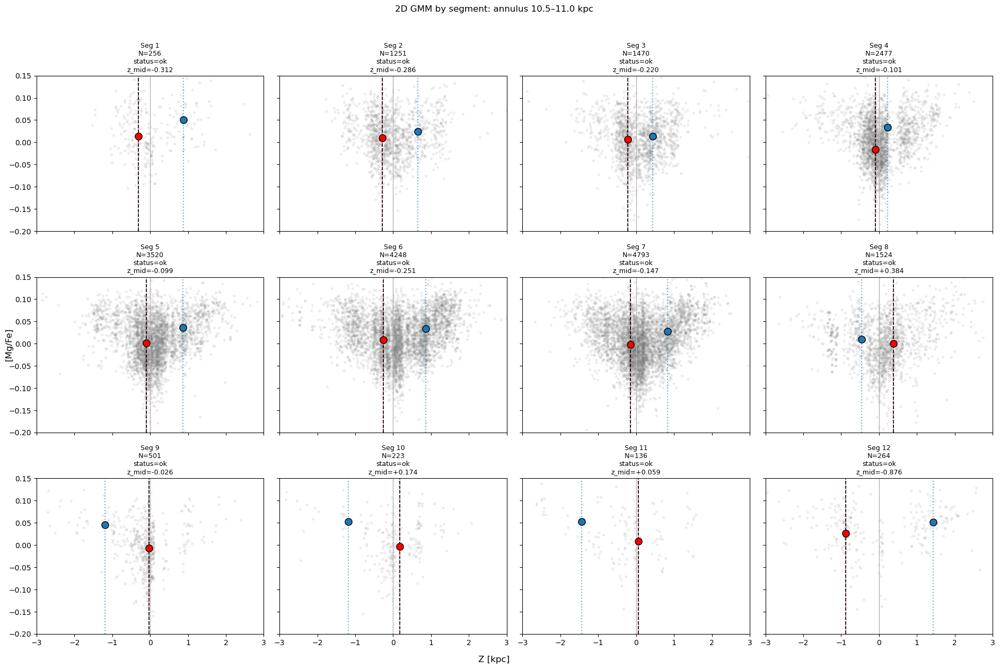

[{'seg': 1, 'Nseg': 256, 'status': 'ok', 'z_mid': -0.3120112234286458},
 {'seg': 2, 'Nseg': 1251, 'status': 'ok', 'z_mid': -0.2856886465892488},
 {'seg': 3, 'Nseg': 1470, 'status': 'ok', 'z_mid': -0.21987306363180048},
 {'seg': 4, 'Nseg': 2477, 'status': 'ok', 'z_mid': -0.10055761644237941},
 {'seg': 5, 'Nseg': 3520, 'status': 'ok', 'z_mid': -0.09926735467935528},
 {'seg': 6, 'Nseg': 4248, 'status': 'ok', 'z_mid': -0.25146147606772806},
 {'seg': 7, 'Nseg': 4793, 'status': 'ok', 'z_mid': -0.1466464842896832},
 {'seg': 8, 'Nseg': 1524, 'status': 'ok', 'z_mid': 0.38439737818462416},
 {'seg': 9, 'Nseg': 501, 'status': 'ok', 'z_mid': -0.025950025768375372},
 {'seg': 10, 'Nseg': 223, 'status': 'ok', 'z_mid': 0.17428600286826382},
 {'seg': 11, 'Nseg': 136, 'status': 'ok', 'z_mid': 0.05911861152129274},
 {'seg': 12, 'Nseg': 264, 'status': 'ok', 'z_mid': -0.8761174115239007}]

In [62]:
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_ids = SEG_PLOT

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

nseg = len(seg_ids)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.8 * ncols, 4.1 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

gmm_panel_results = []

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = seg_ids[j]
    mseg = mR & segm[seg_id]

    Zs = Z_star[mseg]
    MgFes = mgfe_star[mseg]
    good = np.isfinite(Zs) & np.isfinite(MgFes)
    Zs = Zs[good]
    MgFes = MgFes[good]

    Nseg = len(Zs)

    ax.scatter(Zs, MgFes, s=8, alpha=0.10, color="gray")

    res = fit_gmm_2d_midplane(
        Zs,
        MgFes,
        n_components=2,
        search_min=-1.0,
        search_max=1.0,
        min_component_weight=0.15,
        max_sigma_z=0.8,
    )

    if res["gmm"] is not None:
        means = res["means"]
        weights = res["weights"]
        chosen_idx = res["chosen_idx"]

        for k in range(len(weights)):
            color = "red" if k == chosen_idx else "tab:blue"
            ax.scatter(
                means[k, 0], means[k, 1],
                s=90,
                color=color,
                edgecolor="black",
                zorder=5,
            )
            ax.axvline(means[k, 0], color=color, ls=":", alpha=0.6)

    if np.isfinite(res["z_mid"]):
        ax.axvline(res["z_mid"], color="black", ls="--", lw=1.2)

    ax.axvline(0, color="0.7", lw=1)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.15)

    title_lines = [
        f"Seg {seg_id}",
        f"N={Nseg}",
        f"status={res['status']}",
    ]
    if np.isfinite(res["z_mid"]):
        title_lines.append(f"z_mid={res['z_mid']:+.3f}")

    ax.set_title("\n".join(title_lines), fontsize=9)

    gmm_panel_results.append({
        "seg": seg_id,
        "Nseg": Nseg,
        "status": res["status"],
        "z_mid": res["z_mid"],
    })

fig.supxlabel("Z [kpc]")
fig.supylabel("[Mg/Fe]")
fig.suptitle(f"2D GMM by segment: annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.02)
fig.tight_layout()
plt.show()

gmm_panel_results

In [63]:
def compute_df_gmm2d_midplane(
    R_star,
    Z_star,
    mgfe_star,
    segm,
    seg_plot,
    R_edges=None,
    n_components=2,
    minN_seg_total=30,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
):
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star) & np.isfinite(mgfe_star)

            Zs = np.asarray(Z_star[good], float)
            MgFes = np.asarray(mgfe_star[good], float)
            Nseg = len(Zs)

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_mid=np.nan,
                    status="too_few_stars",
                ))
                continue

            res = fit_gmm_2d_midplane(
                Zs,
                MgFes,
                n_components=n_components,
                search_min=search_min,
                search_max=search_max,
                min_component_weight=min_component_weight,
                max_sigma_z=max_sigma_z,
            )

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                Nseg=Nseg,
                z_mid=res["z_mid"],
                status=res["status"],
            ))

    return pd.DataFrame(rows)

In [64]:
df_gmm2d = compute_df_gmm2d_midplane(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    R_edges=None,
    n_components=2,
    minN_seg_total=30,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
)

df_gmm2d.head()

,Rmin,Rmax,seg,Nseg,z_mid,status
0,0.5,1.0,1,6,NaN,too_few_stars
1,0.5,1.0,2,1,NaN,too_few_stars
2,0.5,1.0,3,4,NaN,too_few_stars
3,0.5,1.0,4,3,NaN,too_few_stars
4,0.5,1.0,5,6,NaN,too_few_stars


In [65]:
def build_gmm2d_polar_map(
    df_gmm2d,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_gmm2d["Rmin"].tolist() + df_gmm2d["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = (df_gmm2d["status"] == "ok")

    for _, row in df_gmm2d.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmid = float(row["z_mid"])
        if not np.isfinite(zmid):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmid

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat

In [66]:
Zmap_gmm2d, theta_edges_gmm2d, R_edges_gmm2d, seg_plot_heat_gmm2d = build_gmm2d_polar_map(
    df_gmm2d=df_gmm2d,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=0.6,
)

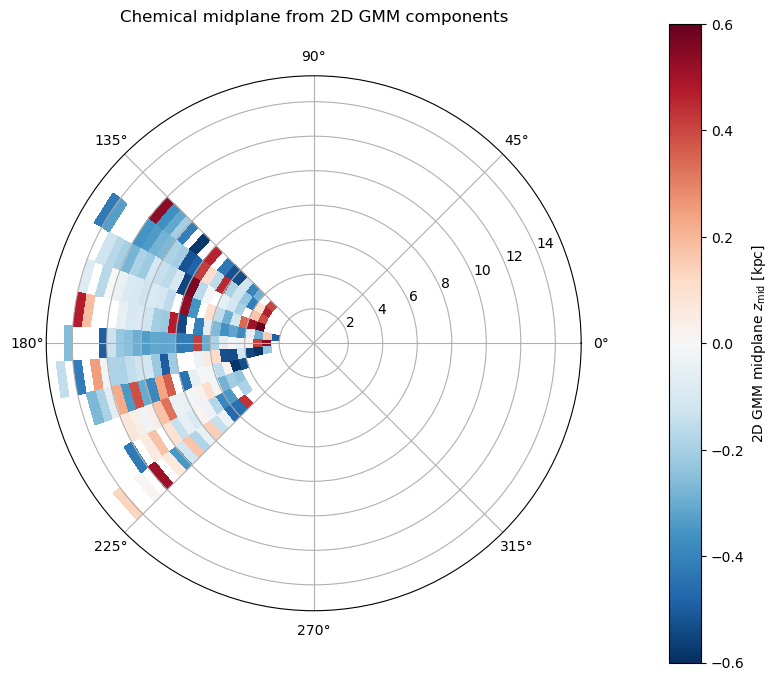

In [67]:
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_gmm2d,
    R_edges_gmm2d,
    Zmap_gmm2d,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.6,
    vmax=0.6,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"2D GMM midplane $z_{\rm mid}$ [kpc]")

ax.set_title("Chemical midplane from 2D GMM components", pad=20)
plt.tight_layout()
plt.show()

N good in both: 177


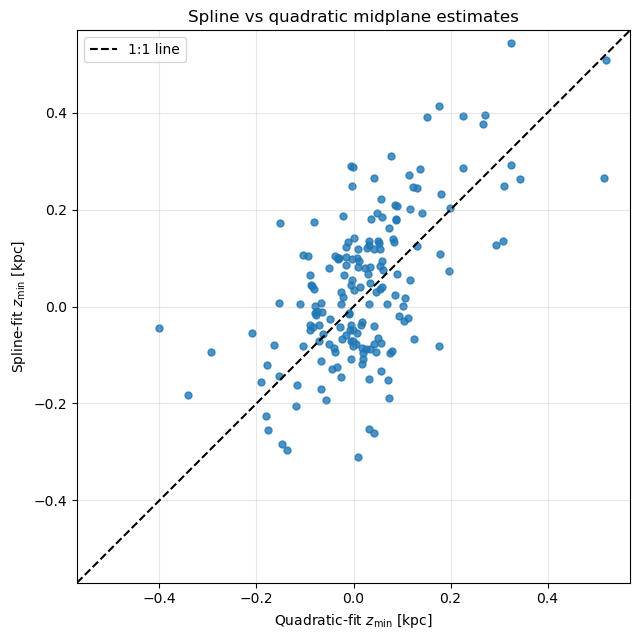

In [68]:
from src.plotting import plot_quad_vs_spline_scatter

merged = df_quad.merge(
    df_spline,
    on=["Rmin", "Rmax", "seg"],
    how="inner"
)

good = (
    (merged["status_quad"] == "ok") &
    (merged["status_spline"] == "ok") &
    np.isfinite(merged["z_min_quad"]) &
    np.isfinite(merged["z_min_spline"])
)

print("N good in both:", int(np.sum(good)))

plot_quad_vs_spline_scatter(
    z_quad=merged.loc[good, "z_min_quad"],
    z_spline=merged.loc[good, "z_min_spline"],
    title="Spline vs quadratic midplane estimates"
)

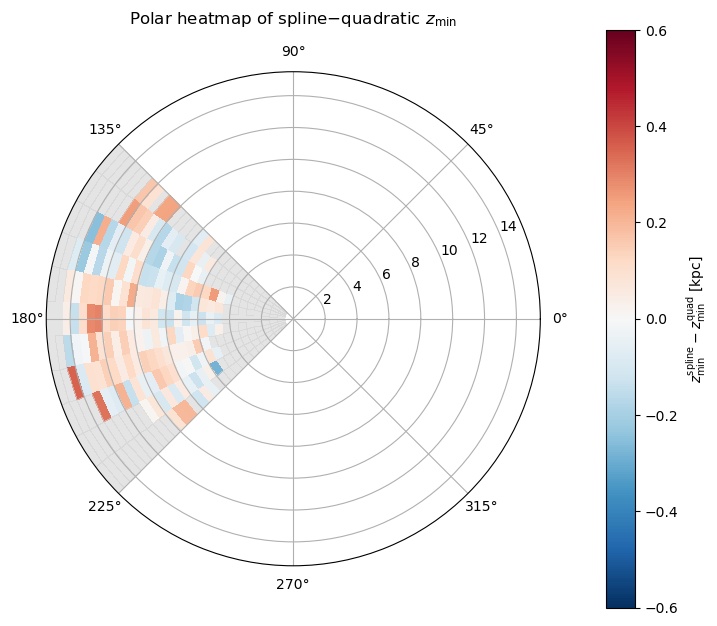

In [69]:
from src.plotting import plot_difference_polar_heatmap

# Only compare where both exist
Zdiff = np.full_like(Zmap, np.nan, dtype=float)
both = np.isfinite(Zmap) & np.isfinite(Zmap_spline)
Zdiff[both] = Zmap_spline[both] - Zmap[both]

plot_difference_polar_heatmap(
    Zdiff=Zdiff,
    theta_edges=theta_edges,
    R_edges_kept=R_edges_kept,
    title=r"Polar heatmap of spline$-$quadratic $z_{\min}$",
    cbar_label=r"$z_{\min}^{\rm spline} - z_{\min}^{\rm quad}$ [kpc]",
    vmin=-0.6,
    vmax=0.6
)

In [70]:
print("Median |difference| [kpc]:", np.nanmedian(np.abs(Zdiff)))
print("Mean signed difference [kpc]:", np.nanmean(Zdiff))
print("Max |difference| [kpc]:", np.nanmax(np.abs(Zdiff)))

Median |difference| [kpc]: 0.08949155615486389
Mean signed difference [kpc]: 0.02376005877620737
Max |difference| [kpc]: 0.35605635505846744


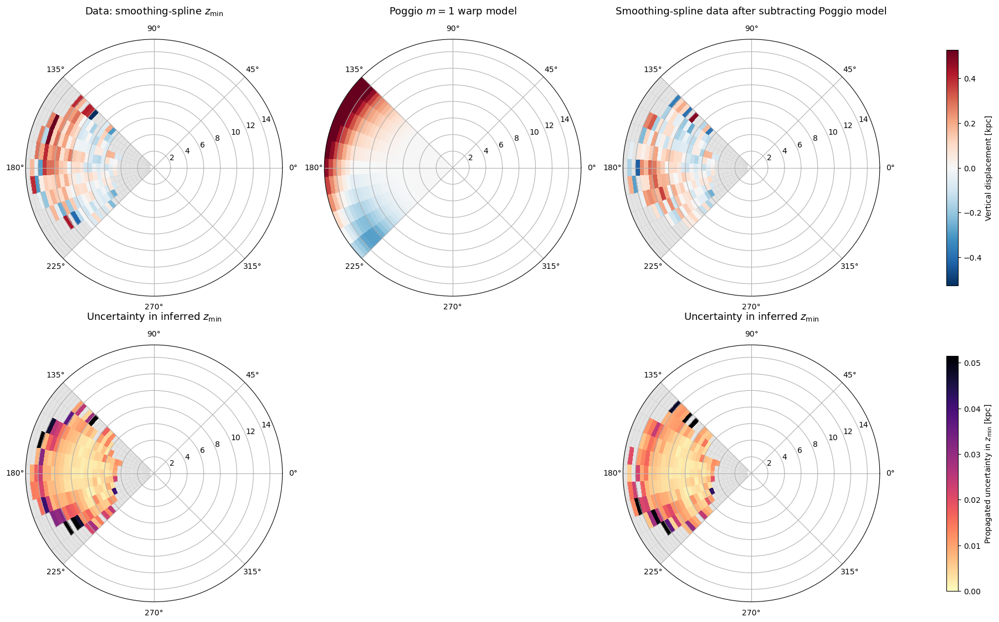

In [71]:
import numpy as np
from src.utils import col_to_float_array
from src.fitting import build_spline_measerr_only_emap
from src.plotting import plot_warp_comparison_2x3

e_mg_h_star = col_to_float_array(t_star, "e_mg_h")
e_fe_h_star = col_to_float_array(t_star, "e_fe_h")

assert len(R_star) == len(e_mg_h_star) == len(e_fe_h_star)
assert len(R_star) == len(segm[1])

# settings: must match your old spline run
minN_seg_total = 15
min_bin_count = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5

spline_k = 3
spline_s = None
n_eval = 400
max_allowed_minima = 1
edge_buffer = 0.05
n_mc = 200

df_spline_sub = compute_df_spline(
    R_star=R_star,
    Z_star=Z_corr,
    mgfe_star=mgfe_star,
    segm=segm_heat,
    seg_plot=SEG_PLOT_heat,
    z_edges=z_edges,
    R_edges=R_edges_kept,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    use_sem_weights=False,
    spline_k=spline_k,
    spline_s=spline_s,
    n_eval=n_eval,
    max_allowed_minima=max_allowed_minima,
    edge_buffer=edge_buffer,
)

Zmap_sub_spline, theta_edges_sub_spline, R_edges_kept_sub_spline, SEG_PLOT_heat_sub_spline = build_spline_polar_map(
    df_spline=df_spline_sub,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT_heat,
    seg_rest_id=None,
    zlim=zlim
)
# ============================================================
# ONLY recompute the uncertainty maps
# ============================================================

# bottom-left: uncertainty for original spline data panel
Emap_data_spline, df_err_data_spline, R_edges_plot_err_data = build_spline_measerr_only_emap(
    R_use=R_star,
    Z_use=Z_star,
    mgfe_use=mgfe_star,
    e_mg_h_use=e_mg_h_star,
    e_fe_h_use=e_fe_h_star,
    segm=segm,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    spline_k=spline_k,
    spline_s=spline_s,
    n_eval=n_eval,
    max_allowed_minima=max_allowed_minima,
    edge_buffer=edge_buffer,
    n_mc=n_mc,
    random_seed=42,
)

# bottom-right: uncertainty for original spline residual panel
Emap_sub_spline, df_err_sub_spline, R_edges_plot_err_sub = build_spline_measerr_only_emap(
    R_use=R_star,
    Z_use=Z_corr,
    mgfe_use=mgfe_star,
    e_mg_h_use=e_mg_h_star,
    e_fe_h_use=e_fe_h_star,
    segm=segm_heat,
    seg_plot_heat=SEG_PLOT_heat,
    R_edges_kept=R_edges_kept,
    z_edges=z_edges,
    minN_seg_total=minN_seg_total,
    min_bin_count=min_bin_count,
    z_fit_min=z_fit_min,
    z_fit_max=z_fit_max,
    min_bins_for_fit=min_bins_for_fit,
    spline_k=spline_k,
    spline_s=spline_s,
    n_eval=n_eval,
    max_allowed_minima=max_allowed_minima,
    edge_buffer=edge_buffer,
    n_mc=n_mc,
    random_seed=123,
)

if not (
    np.allclose(R_edges_plot_data, R_edges_plot_err_data) and
    np.allclose(R_edges_plot_data, R_edges_plot_err_sub)
):
    raise RuntimeError("Radial edges do not match between old spline top row and new uncertainty maps.")

# ============================================================
# PLOT: OLD spline top row + NEW measurement-error bottom row
# ============================================================
plot_warp_comparison_2x3(
    Zmap_data=Zmap_spline,
    Zmap_model=Zmap_model,
    Zmap_sub=Zmap_sub_spline,
    Emap_data=Emap_data_spline,
    Emap_sub=Emap_sub_spline,
    theta_edges=theta_edges_spline,
    R_edges_plot=R_edges_kept_spline,
    zlim=zlim,
    data_title=r"Data: smoothing-spline $z_{\min}$",
    sub_title=r"Smoothing-spline data after subtracting Poggio model"
)

status: ok
z_mid: -0.10109509053308824


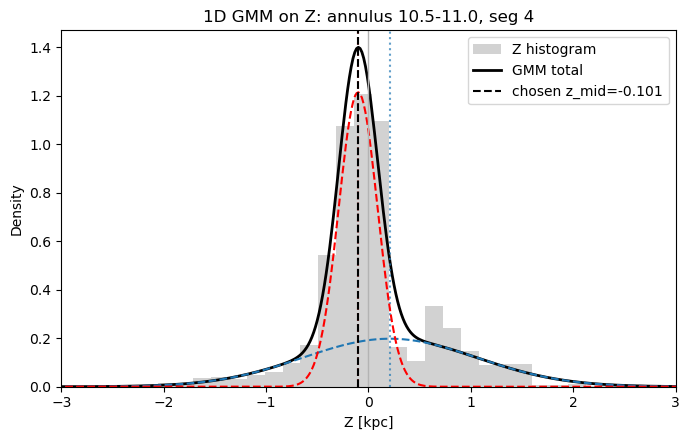

status
ok                                        230
chosen_component_too_broad                 73
too_few_stars                              45
chosen_component_near_edge                  7
chosen_component_low_weight                 3
chosen_component_outside_search_window      2
Name: count, dtype: int64


,Rmin,Rmax,seg,Nseg,z_mid,status
0,0.5,1.0,1,6,NaN,too_few_stars
1,0.5,1.0,2,1,NaN,too_few_stars
2,0.5,1.0,3,4,NaN,too_few_stars
3,0.5,1.0,4,3,NaN,too_few_stars
4,0.5,1.0,5,6,NaN,too_few_stars


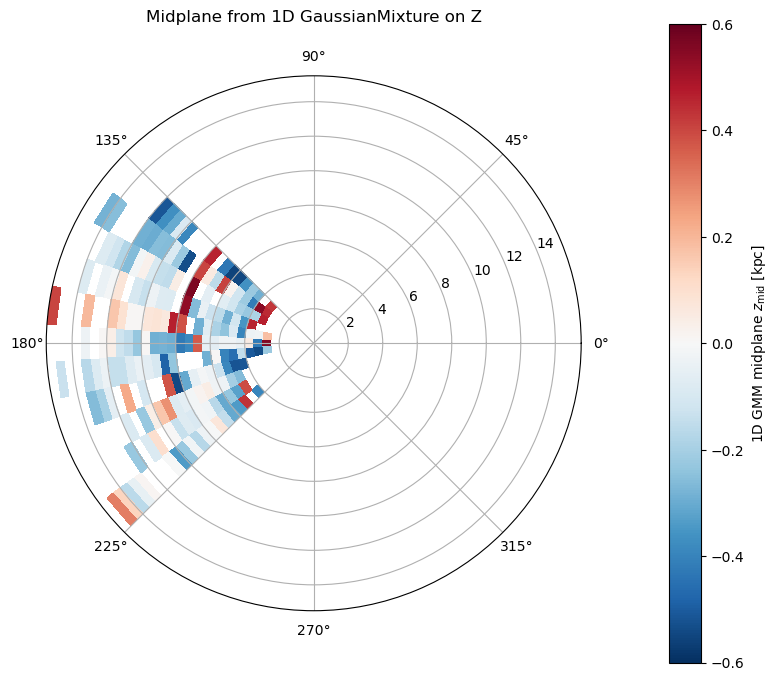

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture


# =========================================================
# SETTINGS
# =========================================================
SEARCH_MIN = -1.0
SEARCH_MAX = 1.0
EDGE_BUFFER_SEARCH = 0.10

MINN_SEG_TOTAL = 20
N_COMPONENTS = 2
RANDOM_STATE = 0
REG_COVAR = 1e-4

MIN_COMPONENT_WEIGHT = 0.15   # reject tiny spurious components
MAX_SIGMA_Z = 0.8             # reject very broad central components
ZLIM_HEATMAP = 0.6


# =========================================================
# FIT 1D GMM TO Z AND PICK CENTRAL COMPONENT
# =========================================================
def fit_gmm_z_midplane(
    Zs,
    n_components=2,
    random_state=0,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
):
    """
    Fit a 1D GaussianMixture to Z only.

    Selection rule:
    - choose the component whose mean is closest to Z=0
    - reject if the chosen component is outside the trusted window,
      too close to the trusted-window edge, too low-weight, or too broad
    """
    Zs = np.asarray(Zs, float)
    Zs = Zs[np.isfinite(Zs)]

    if len(Zs) < max(20, 8 * n_components):
        return {
            "status": "too_few_stars",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    X = Zs[:, None]   # shape (n_samples, 1)

    try:
        gmm = GaussianMixture(
            n_components=n_components,
            random_state=random_state,
            reg_covar=reg_covar,
        ).fit(X)
    except Exception:
        return {
            "status": "fit_failed",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    means = gmm.means_.ravel()
    weights = gmm.weights_.ravel()

    covs = np.asarray(gmm.covariances_)
    # covariance_type='full' by default, so in 1D this is usually (k,1,1)
    if covs.ndim == 3:
        sigma_z = np.sqrt(covs[:, 0, 0])
    elif covs.ndim == 2:
        sigma_z = np.sqrt(covs[:, 0])
    else:
        sigma_z = np.sqrt(covs)

    # choose the component closest to Z=0
    chosen_idx = int(np.argmin(np.abs(means)))
    z_mid = float(means[chosen_idx])

    # quality checks
    if not (search_min <= z_mid <= search_max):
        status = "chosen_component_outside_search_window"
        z_mid = np.nan
    elif (z_mid <= search_min + EDGE_BUFFER_SEARCH) or (z_mid >= search_max - EDGE_BUFFER_SEARCH):
        status = "chosen_component_near_edge"
        z_mid = np.nan
    elif weights[chosen_idx] < min_component_weight:
        status = "chosen_component_low_weight"
        z_mid = np.nan
    elif sigma_z[chosen_idx] > max_sigma_z:
        status = "chosen_component_too_broad"
        z_mid = np.nan
    else:
        status = "ok"

    return {
        "status": status,
        "z_mid": z_mid,
        "gmm": gmm,
        "chosen_idx": chosen_idx,
        "means": means,
        "weights": weights,
        "sigma_z": sigma_z,
    }


# =========================================================
# TEST ONE ANNULUS + SEGMENT
# =========================================================
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

Zs = np.asarray(Z_star[mseg], float)
Zs = Zs[np.isfinite(Zs)]

res_gmm_z = fit_gmm_z_midplane(
    Zs,
    n_components=N_COMPONENTS,
    random_state=RANDOM_STATE,
    reg_covar=REG_COVAR,
    search_min=SEARCH_MIN,
    search_max=SEARCH_MAX,
    min_component_weight=MIN_COMPONENT_WEIGHT,
    max_sigma_z=MAX_SIGMA_Z,
)

print("status:", res_gmm_z["status"])
print("z_mid:", res_gmm_z["z_mid"])

# plot histogram + component means
plt.figure(figsize=(7, 4.5))
plt.hist(Zs, bins=50, density=True, alpha=0.35, color="gray", label="Z histogram")

if res_gmm_z["gmm"] is not None:
    means = res_gmm_z["means"]
    weights = res_gmm_z["weights"]
    sigma_z = res_gmm_z["sigma_z"]
    chosen_idx = res_gmm_z["chosen_idx"]

    zgrid = np.linspace(np.nanmin(Zs), np.nanmax(Zs), 500)
    logprob = res_gmm_z["gmm"].score_samples(zgrid[:, None])
    pdf = np.exp(logprob)
    plt.plot(zgrid, pdf, color="black", lw=2, label="GMM total")

    # component curves
    for k in range(len(means)):
        mu = means[k]
        sig = sigma_z[k]
        w = weights[k]
        comp = w * (1.0 / (np.sqrt(2*np.pi) * sig)) * np.exp(-0.5 * ((zgrid - mu) / sig)**2)

        color = "red" if k == chosen_idx else "tab:blue"
        plt.plot(zgrid, comp, color=color, ls="--", lw=1.5)
        plt.axvline(mu, color=color, ls=":", alpha=0.7)

if np.isfinite(res_gmm_z["z_mid"]):
    plt.axvline(res_gmm_z["z_mid"], color="black", ls="--", lw=1.5, label=f"chosen z_mid={res_gmm_z['z_mid']:+.3f}")

plt.axvline(0, color="0.7", lw=1)
plt.xlim(-3, 3)
plt.xlabel("Z [kpc]")
plt.ylabel("Density")
plt.title(f"1D GMM on Z: annulus {Rmin_focus:.1f}-{Rmax_focus:.1f}, seg {seg_id}")
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# RUN OVER ALL ANNULI + SEGMENTS
# =========================================================
def compute_df_gmm_z_midplane(
    R_star,
    Z_star,
    segm,
    seg_plot,
    R_edges=None,
    n_components=2,
    minN_seg_total=20,
    random_state=0,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
):
    if R_edges is None:
        R_edges = np.arange(0.5, 15.5 + 0.5, 0.5)

    rows = []

    for ir in range(len(R_edges) - 1):
        Rmin_focus = float(R_edges[ir])
        Rmax_focus = float(R_edges[ir + 1])

        mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

        for seg_id in seg_plot:
            mseg = mR & segm[seg_id]
            good = mseg & np.isfinite(Z_star)

            Zs = np.asarray(Z_star[good], float)
            Nseg = len(Zs)

            if Nseg < minN_seg_total:
                rows.append(dict(
                    Rmin=Rmin_focus,
                    Rmax=Rmax_focus,
                    seg=int(seg_id),
                    Nseg=Nseg,
                    z_mid=np.nan,
                    status="too_few_stars",
                ))
                continue

            res = fit_gmm_z_midplane(
                Zs,
                n_components=n_components,
                random_state=random_state,
                reg_covar=reg_covar,
                search_min=search_min,
                search_max=search_max,
                min_component_weight=min_component_weight,
                max_sigma_z=max_sigma_z,
            )

            rows.append(dict(
                Rmin=Rmin_focus,
                Rmax=Rmax_focus,
                seg=int(seg_id),
                Nseg=Nseg,
                z_mid=res["z_mid"],
                status=res["status"],
            ))

    return pd.DataFrame(rows)


df_gmm_z = compute_df_gmm_z_midplane(
    R_star=R_star,
    Z_star=Z_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    R_edges=None,
    n_components=N_COMPONENTS,
    minN_seg_total=MINN_SEG_TOTAL,
    random_state=RANDOM_STATE,
    reg_covar=REG_COVAR,
    search_min=SEARCH_MIN,
    search_max=SEARCH_MAX,
    min_component_weight=MIN_COMPONENT_WEIGHT,
    max_sigma_z=MAX_SIGMA_Z,
)

print(df_gmm_z["status"].value_counts(dropna=False))
display(df_gmm_z.head())


# =========================================================
# BUILD POLAR MAP
# =========================================================
def build_gmm_z_polar_map(
    df_gmm_z,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_gmm_z["Rmin"].tolist() + df_gmm_z["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = (df_gmm_z["status"] == "ok")

    for _, row in df_gmm_z.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmid = float(row["z_mid"])
        if not np.isfinite(zmid):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmid

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat


Zmap_gmm_z, theta_edges_gmm_z, R_edges_gmm_z, seg_plot_heat_gmm_z = build_gmm_z_polar_map(
    df_gmm_z=df_gmm_z,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=ZLIM_HEATMAP,
)

fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

pcm = ax.pcolormesh(
    theta_edges_gmm_z,
    R_edges_gmm_z,
    Zmap_gmm_z,
    shading="auto",
    cmap="RdBu_r",
    vmin=-ZLIM_HEATMAP,
    vmax= ZLIM_HEATMAP,
)

cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
cbar.set_label(r"1D GMM midplane $z_{\rm mid}$ [kpc]")

ax.set_title("Midplane from 1D GaussianMixture on Z", pad=20)
plt.tight_layout()
plt.show()

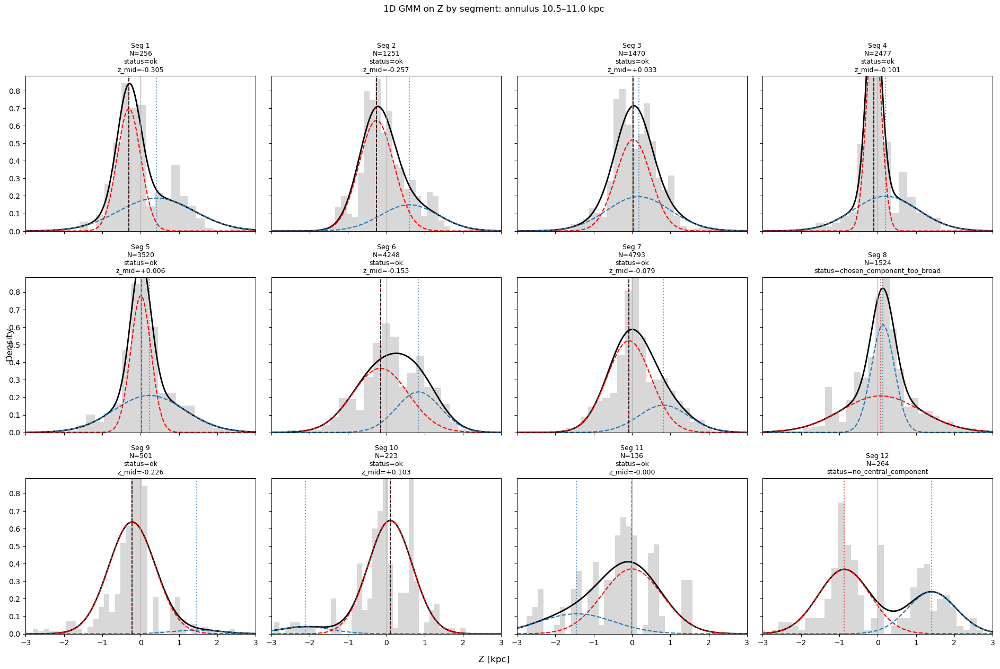

[{'seg': 1, 'Nseg': 256, 'status': 'ok', 'z_mid': -0.3046580470232487},
 {'seg': 2, 'Nseg': 1251, 'status': 'ok', 'z_mid': -0.2572464782679134},
 {'seg': 3, 'Nseg': 1470, 'status': 'ok', 'z_mid': 0.03273309889397646},
 {'seg': 4, 'Nseg': 2477, 'status': 'ok', 'z_mid': -0.10109509053308824},
 {'seg': 5, 'Nseg': 3520, 'status': 'ok', 'z_mid': 0.005868840053852666},
 {'seg': 6, 'Nseg': 4248, 'status': 'ok', 'z_mid': -0.153080763133274},
 {'seg': 7, 'Nseg': 4793, 'status': 'ok', 'z_mid': -0.0786603305144632},
 {'seg': 8,
  'Nseg': 1524,
  'status': 'chosen_component_too_broad',
  'z_mid': nan},
 {'seg': 9, 'Nseg': 501, 'status': 'ok', 'z_mid': -0.2260996113654202},
 {'seg': 10, 'Nseg': 223, 'status': 'ok', 'z_mid': 0.10309270907433614},
 {'seg': 11, 'Nseg': 136, 'status': 'ok', 'z_mid': -5.1609679754446396e-05},
 {'seg': 12, 'Nseg': 264, 'status': 'no_central_component', 'z_mid': nan}]

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_ids = SEG_PLOT

N_COMPONENTS = 2
RANDOM_STATE = 0
REG_COVAR = 1e-4

SEARCH_MIN = -1.0
SEARCH_MAX = 1.0
EDGE_BUFFER_SEARCH = 0.10
MIN_COMPONENT_WEIGHT = 0.15
MAX_SIGMA_Z = 0.8
MINN_SEG_TOTAL = 20
MAX_ABS_ZMID = 0.6  

# --------------------------------------------------
# HELPER: fit 1D GMM on Z and choose central component
# --------------------------------------------------
def fit_gmm_z_midplane(
    Zs,
    n_components=2,
    random_state=0,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.15,
    max_sigma_z=0.8,
):
    Zs = np.asarray(Zs, float)
    Zs = Zs[np.isfinite(Zs)]

    if len(Zs) < max(20, 8 * n_components):
        return {
            "status": "too_few_stars",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    X = Zs[:, None]

    try:
        gmm = GaussianMixture(
            n_components=n_components,
            random_state=random_state,
            reg_covar=reg_covar,
        ).fit(X)
    except Exception:
        return {
            "status": "fit_failed",
            "z_mid": np.nan,
            "gmm": None,
            "chosen_idx": None,
        }

    means = gmm.means_.ravel()
    weights = gmm.weights_.ravel()
    covs = np.asarray(gmm.covariances_)

    if covs.ndim == 3:
        sigma_z = np.sqrt(covs[:, 0, 0])
    elif covs.ndim == 2:
        sigma_z = np.sqrt(covs[:, 0])
    else:
        sigma_z = np.sqrt(covs)

    # choose component with mean closest to z=0
    chosen_idx = int(np.argmin(np.abs(means)))
    z_mid = float(means[chosen_idx])

    if not (search_min <= z_mid <= search_max):
        status = "chosen_component_outside_search_window"
        z_mid = np.nan
    elif (z_mid <= search_min + EDGE_BUFFER_SEARCH) or (z_mid >= search_max - EDGE_BUFFER_SEARCH):
        status = "chosen_component_near_edge"
        z_mid = np.nan
    elif weights[chosen_idx] < min_component_weight:
        status = "chosen_component_low_weight"
        z_mid = np.nan
    elif sigma_z[chosen_idx] > max_sigma_z:
        status = "chosen_component_too_broad"
        z_mid = np.nan
    elif abs(z_mid) > MAX_ABS_ZMID:
        status = "no_central_component"
        z_mid = np.nan
    else:
        status = "ok"

    return {
        "status": status,
        "z_mid": z_mid,
        "gmm": gmm,
        "chosen_idx": chosen_idx,
        "means": means,
        "weights": weights,
        "sigma_z": sigma_z,
    }

# --------------------------------------------------
# ONE ANNULUS, ALL SEGMENTS
# --------------------------------------------------
mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)

nseg = len(seg_ids)
ncols = 4
nrows = int(np.ceil(nseg / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.8 * ncols, 4.1 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

gmm_results = []

for j, ax in enumerate(axes.flat):
    if j >= nseg:
        ax.axis("off")
        continue

    seg_id = seg_ids[j]
    mseg = mR & segm[seg_id]

    Zs = np.asarray(Z_star[mseg], float)
    Zs = Zs[np.isfinite(Zs)]
    Nseg = len(Zs)

    # histogram
    if Nseg > 0:
        ax.hist(
            Zs,
            bins=40,
            density=True,
            alpha=0.30,
            color="gray"
        )

    res = fit_gmm_z_midplane(
        Zs,
        n_components=N_COMPONENTS,
        random_state=RANDOM_STATE,
        reg_covar=REG_COVAR,
        search_min=SEARCH_MIN,
        search_max=SEARCH_MAX,
        min_component_weight=MIN_COMPONENT_WEIGHT,
        max_sigma_z=MAX_SIGMA_Z,
    )

    if res["gmm"] is not None:
        means = res["means"]
        weights = res["weights"]
        sigma_z = res["sigma_z"]
        chosen_idx = res["chosen_idx"]

        zgrid = np.linspace(-3, 3, 500)
        logprob = res["gmm"].score_samples(zgrid[:, None])
        pdf = np.exp(logprob)
        ax.plot(zgrid, pdf, color="black", lw=2)

        for k in range(len(means)):
            mu = means[k]
            sig = sigma_z[k]
            w = weights[k]

            comp = w * (1.0 / (np.sqrt(2*np.pi) * sig)) * np.exp(-0.5 * ((zgrid - mu) / sig)**2)

            color = "red" if k == chosen_idx else "tab:blue"
            ax.plot(zgrid, comp, color=color, ls="--", lw=1.5)
            ax.axvline(mu, color=color, ls=":", alpha=0.7)

    if np.isfinite(res["z_mid"]):
        ax.axvline(
            res["z_mid"],
            color="black",
            ls="--",
            lw=1.2,
        )

    ax.axvline(0, color="0.7", lw=1)
    ax.set_xlim(-3, 3)
    ax.set_ylim(0, None)

    title_lines = [
        f"Seg {seg_id}",
        f"N={Nseg}",
        f"status={res['status']}",
    ]
    if np.isfinite(res["z_mid"]):
        title_lines.append(f"z_mid={res['z_mid']:+.3f}")

    ax.set_title("\n".join(title_lines), fontsize=9)

    gmm_results.append({
        "seg": seg_id,
        "Nseg": Nseg,
        "status": res["status"],
        "z_mid": res["z_mid"],
    })

fig.supxlabel("Z [kpc]")
fig.supylabel("Density")
fig.suptitle(f"1D GMM on Z by segment: annulus {Rmin_focus:.1f}–{Rmax_focus:.1f} kpc", y=1.02)
fig.tight_layout()
plt.show()

gmm_results

In [96]:
from sklearn.mixture import GaussianMixture
import numpy as np

def fit_gmm_z_midplane(
    Zs,
    n_components=2,
    min_stars=20,
    search_min=-2.0,
    search_max=2.0,
    min_component_weight=0.1,
    max_sigma_z=1.0,
):
    if len(Zs) < min_stars:
        return np.nan, "too_few_stars"

    Zs = Zs[(Zs >= search_min) & (Zs <= search_max)]
    if len(Zs) < min_stars:
        return np.nan, "too_few_stars_after_cut"

    Zs = Zs.reshape(-1, 1)

    try:
        gmm = GaussianMixture(n_components=n_components, random_state=0)
        gmm.fit(Zs)
    except:
        return np.nan, "gmm_failed"

    means = gmm.means_.flatten()
    weights = gmm.weights_.flatten()
    sigma_z = np.sqrt(gmm.covariances_.flatten())

    # choose component closest to Z=0
    chosen_idx = int(np.argmin(np.abs(means)))
    z_mid = float(means[chosen_idx])

    MAX_ABS_ZMID = 0.6

    # quality checks
    if weights[chosen_idx] < min_component_weight:
        return np.nan, "low_weight"
    elif sigma_z[chosen_idx] > max_sigma_z:
        return np.nan, "too_broad"
    elif abs(z_mid) > MAX_ABS_ZMID:
        return np.nan, "no_central_component"
    else:
        return z_mid, "ok"

In [97]:
def build_gmm_z_polar_map(
    df_gmm_z,
    crowd_bounds,
    seg_plot,
    seg_rest_id=None,
    zlim=0.6,
):
    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(
        sorted(set(df_gmm_z["Rmin"].tolist() + df_gmm_z["Rmax"].tolist())),
        float
    )

    n_r = len(R_edges_kept) - 1
    n_th = len(seg_plot_heat)

    Zmap_raw = np.full((n_r, n_th), np.nan, float)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good_rows = (df_gmm_z["status"] == "ok")

    for _, row in df_gmm_z.loc[good_rows].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        zmid = float(row["z_mid"])
        if not np.isfinite(zmid):
            continue

        Rmin = float(row["Rmin"])
        ir = np.searchsorted(R_edges_kept, Rmin, side="right") - 1
        if not (0 <= ir < n_r):
            continue

        it = seg_to_col[seg]
        Zmap_raw[ir, it] = zmid

    Zmap = np.where(
        np.isfinite(Zmap_raw) & (np.abs(Zmap_raw) <= zlim),
        Zmap_raw,
        np.nan
    )

    return Zmap, theta_edges, R_edges_kept, seg_plot_heat

In [98]:
import matplotlib.pyplot as plt

def plot_gmm_heatmap(R_edges, theta_edges, Zmap, zlim=0.5):

    fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

    pcm = ax.pcolormesh(
        theta_edges_gmm_z,
        R_edges_gmm_z,
        Zmap_gmm_z,
        shading="auto",
        cmap="RdBu_r",
        vmin=-0.5,
        vmax=0.5,
    )

    cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
    cbar.set_label(r"Midplane $z_{\rm mid}$ [kpc]")

    ax.set_title("GMM Midplane (1D z)", pad=20)
    plt.tight_layout()
    plt.show()

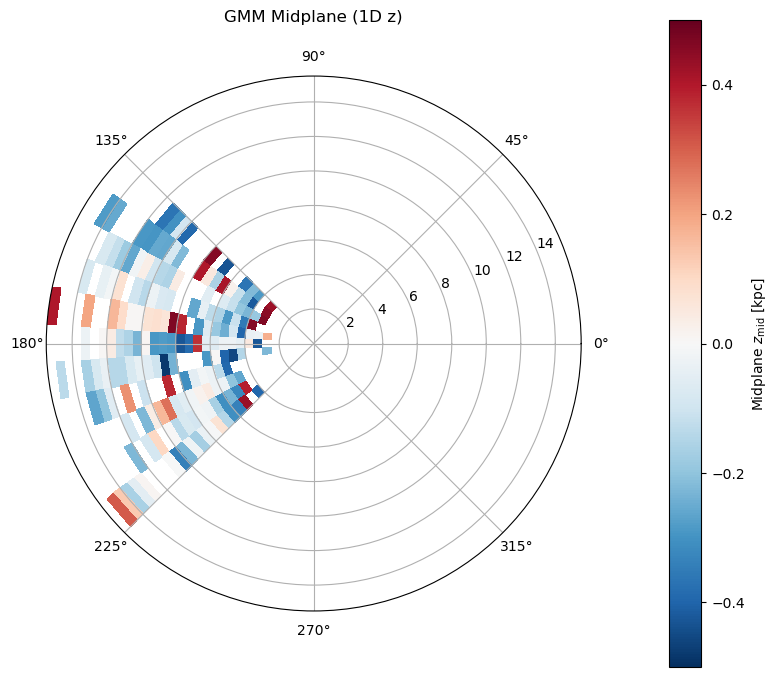

In [99]:
Zmap_gmm_z, theta_edges_gmm_z, R_edges_gmm_z, seg_plot_heat_gmm_z = build_gmm_z_polar_map(
    df_gmm_z=df_gmm_z,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=0.5,
)

plot_gmm_heatmap(R_edges, theta_edges, Zmap, zlim=0.5)

In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture


# -----------------------------------
# Settings
# -----------------------------------
CFG = dict(
    min_stars=20,
    n_components=2,
    random_state=0,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    max_abs_zmid=0.6,
    min_component_weight=0.10,
    max_sigma_mgfe=0.10,
    zlim=0.6,
)


# -----------------------------------
# Fit one segment: GMM in Mg/Fe only
# -----------------------------------
def fit_segment_gmm_mgfe(Zs, MgFes, cfg=CFG, return_details=False):
    Zs = np.asarray(Zs, float)
    MgFes = np.asarray(MgFes, float)

    good = np.isfinite(Zs) & np.isfinite(MgFes)
    Zs, MgFes = Zs[good], MgFes[good]

    if len(Zs) < cfg["min_stars"]:
        result = {"z_mid": np.nan, "status": "too_few_stars"}
        return result if return_details else (np.nan, "too_few_stars")

    X = MgFes[:, None]

    try:
        gmm = GaussianMixture(
            n_components=cfg["n_components"],
            random_state=cfg["random_state"],
            reg_covar=cfg["reg_covar"],
        ).fit(X)
    except Exception:
        result = {"z_mid": np.nan, "status": "fit_failed"}
        return result if return_details else (np.nan, "fit_failed")

    means = gmm.means_.ravel()
    weights = gmm.weights_.ravel()
    covs = np.asarray(gmm.covariances_)

    if covs.ndim == 3:
        sigma_mgfe = np.sqrt(covs[:, 0, 0])
    elif covs.ndim == 2:
        sigma_mgfe = np.sqrt(covs[:, 0])
    else:
        sigma_mgfe = np.sqrt(covs)

    # choose lowest-Mg/Fe component
    chosen_idx = int(np.argmin(means))

    # soft membership in that component
    resp = gmm.predict_proba(X)[:, chosen_idx]
    if np.sum(resp) <= 0:
        result = {"z_mid": np.nan, "status": "zero_responsibility"}
        return result if return_details else (np.nan, "zero_responsibility")

    # weighted Z center of the chosen chemical component
    z_mid = float(np.sum(resp * Zs) / np.sum(resp))

    if weights[chosen_idx] < cfg["min_component_weight"]:
        status = "low_weight"
        z_mid = np.nan
    elif sigma_mgfe[chosen_idx] > cfg["max_sigma_mgfe"]:
        status = "too_broad_in_mgfe"
        z_mid = np.nan
    elif not (cfg["search_min"] <= z_mid <= cfg["search_max"]):
        status = "outside_search_window"
        z_mid = np.nan
    elif abs(z_mid) > cfg["max_abs_zmid"]:
        status = "no_central_component"
        z_mid = np.nan
    else:
        status = "ok"

    result = {
        "z_mid": z_mid,
        "status": status,
        "gmm": gmm,
        "chosen_idx": chosen_idx,
        "means": means,
        "weights": weights,
        "sigma_mgfe": sigma_mgfe,
        "resp": resp,
        "N": len(Zs),
    }

    return result if return_details else (z_mid, status)


# -----------------------------------
# Build dataframe over all annuli/segments
# -----------------------------------
def compute_gmm_mgfe_map_df(R_star, Z_star, mgfe_star, segm, seg_plot, R_edges=None, cfg=CFG):
    if R_edges is None:
        R_edges = np.arange(0.5, 16.0, 0.5)

    rows = []

    for r0, r1 in zip(R_edges[:-1], R_edges[1:]):
        mR = (R_star >= r0) & (R_star < r1)

        for seg_id in seg_plot:
            m = mR & segm[seg_id]
            z_mid, status = fit_segment_gmm_mgfe(Z_star[m], mgfe_star[m], cfg=cfg, return_details=False)

            rows.append({
                "Rmin": float(r0),
                "Rmax": float(r1),
                "seg": int(seg_id),
                "Nseg": int(np.sum(np.isfinite(Z_star[m]) & np.isfinite(mgfe_star[m]))),
                "z_mid": z_mid,
                "status": status,
            })

    return pd.DataFrame(rows)


# -----------------------------------
# Convert dataframe to polar map
# -----------------------------------
def df_to_polar_map(df, crowd_bounds, seg_plot, seg_rest_id=None, zlim=None):
    if zlim is None:
        zlim = CFG["zlim"]

    if seg_rest_id is not None:
        seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
    else:
        seg_plot_heat = list(seg_plot)

    n_th_from_bounds = len(crowd_bounds) - 1
    if len(seg_plot_heat) != n_th_from_bounds:
        seg_plot_heat = list(range(1, n_th_from_bounds + 1))

    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    R_edges_kept = np.array(sorted(set(df["Rmin"]).union(df["Rmax"])), float)

    Zmap = np.full((len(R_edges_kept) - 1, len(seg_plot_heat)), np.nan)
    seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

    good = df["status"] == "ok"
    for _, row in df.loc[good].iterrows():
        seg = int(row["seg"])
        if seg not in seg_to_col:
            continue

        ir = np.searchsorted(R_edges_kept, float(row["Rmin"]), side="right") - 1
        ic = seg_to_col[seg]
        z = float(row["z_mid"])

        if np.isfinite(z) and abs(z) <= zlim:
            Zmap[ir, ic] = z

    return Zmap, theta_edges, R_edges_kept


# -----------------------------------
# Plot map
# -----------------------------------
def plot_polar_map(Zmap, theta_edges, R_edges, zlim=0.6, title="Midplane from 1D GMM on Mg/Fe"):
    fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

    pcm = ax.pcolormesh(
        theta_edges,
        R_edges,
        Zmap,
        shading="auto",
        cmap="RdBu_r",
        vmin=-zlim,
        vmax=zlim,
    )

    cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
    cbar.set_label(r"$z_{\rm mid}$ [kpc]")

    ax.set_title(title, pad=20)
    plt.tight_layout()
    plt.show()


# -----------------------------------
# Optional diagnostic plot for one segment
# -----------------------------------
def plot_one_segment_gmm_mgfe(Zs, MgFes, cfg=CFG, title="1D GMM on Mg/Fe"):
    Zs = np.asarray(Zs, float)
    MgFes = np.asarray(MgFes, float)

    good = np.isfinite(Zs) & np.isfinite(MgFes)
    Zs, MgFes = Zs[good], MgFes[good]

    res = fit_segment_gmm_mgfe(Zs, MgFes, cfg=cfg, return_details=True)

    plt.figure(figsize=(7, 4.5))
    plt.hist(MgFes, bins=40, density=True, alpha=0.35, color="gray", label="Mg/Fe histogram")

    if res.get("gmm") is not None:
        means = res["means"]
        weights = res["weights"]
        sigma_mgfe = res["sigma_mgfe"]
        chosen_idx = res["chosen_idx"]

        xgrid = np.linspace(np.nanmin(MgFes), np.nanmax(MgFes), 500)
        logprob = res["gmm"].score_samples(xgrid[:, None])
        pdf = np.exp(logprob)
        plt.plot(xgrid, pdf, color="black", lw=2, label="GMM total")

        for k in range(len(means)):
            mu = means[k]
            sig = sigma_mgfe[k]
            w = weights[k]
            comp = w * (1.0 / (np.sqrt(2*np.pi) * sig)) * np.exp(-0.5 * ((xgrid - mu) / sig)**2)

            color = "red" if k == chosen_idx else "tab:blue"
            plt.plot(xgrid, comp, color=color, ls="--", lw=1.5)
            plt.axvline(mu, color=color, ls=":", alpha=0.7)
 
    plt.xlabel("[Mg/Fe]")
    plt.ylabel("Density")
    plt.title(f"{title}\nstatus={res['status']}, z_mid={res['z_mid']:+.3f}" if np.isfinite(res["z_mid"]) else f"{title}\nstatus={res['status']}")
    plt.legend()
    plt.tight_layout()
    plt.show()

    return res

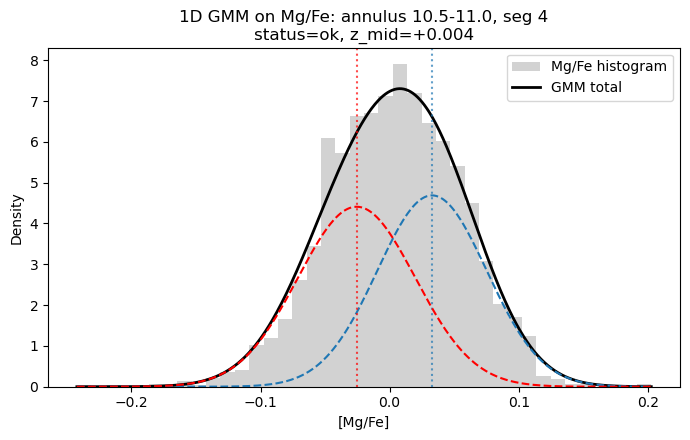

In [133]:
Rmin_focus, Rmax_focus = 10.5, 11.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

res = plot_one_segment_gmm_mgfe(
    Z_star[mseg],
    mgfe_star[mseg],
    cfg=CFG,
    title=f"1D GMM on Mg/Fe: annulus {Rmin_focus:.1f}-{Rmax_focus:.1f}, seg {seg_id}",
)

In [127]:
df_gmm_mgfe = compute_gmm_mgfe_map_df(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    R_edges=R_edges,
    cfg=CFG,
)

print(df_gmm_mgfe["status"].value_counts(dropna=False))
display(df_gmm_mgfe.head())

status
ok                       301
too_few_stars             45
no_central_component       7
low_weight                 5
too_broad_in_mgfe          1
outside_search_window      1
Name: count, dtype: int64


,Rmin,Rmax,seg,Nseg,z_mid,status
0,0.5,1.0,1,6,NaN,too_few_stars
1,0.5,1.0,2,1,NaN,too_few_stars
2,0.5,1.0,3,4,NaN,too_few_stars
3,0.5,1.0,4,3,NaN,too_few_stars
4,0.5,1.0,5,6,NaN,too_few_stars


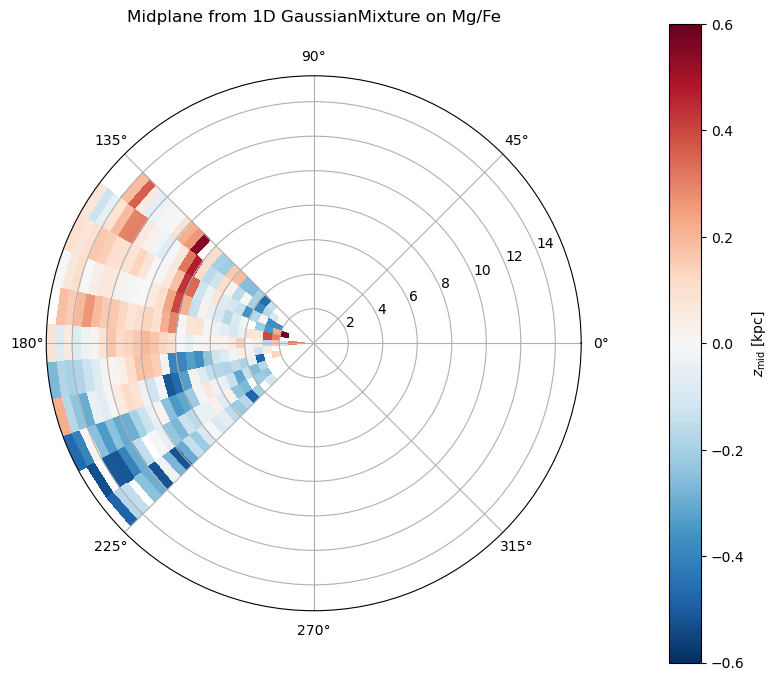

In [122]:
Zmap_gmm_mgfe, theta_edges_gmm_mgfe, R_edges_gmm_mgfe = df_to_polar_map(
    df_gmm_mgfe,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
    zlim=CFG["zlim"],
)

plot_polar_map(
    Zmap_gmm_mgfe,
    theta_edges_gmm_mgfe,
    R_edges_gmm_mgfe,
    zlim=CFG["zlim"],
    title="Midplane from 1D GaussianMixture on Mg/Fe",
)

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture


class GMM2DMidplane:
    def __init__(
        self,
        min_stars=20,
        n_components=2,
        random_state=0,
        reg_covar=1e-4,
        search_min=-1.0,
        search_max=1.0,
        min_component_weight=0.05,
        max_sigma_z=0.8,
        max_abs_zmid=0.6,
        zlim=0.6,
        mgfe_weight_in_score=0.5,
    ):
        self.min_stars = min_stars
        self.n_components = n_components
        self.random_state = random_state
        self.reg_covar = reg_covar
        self.search_min = search_min
        self.search_max = search_max
        self.min_component_weight = min_component_weight
        self.max_sigma_z = max_sigma_z
        self.max_abs_zmid = max_abs_zmid
        self.zlim = zlim
        self.mgfe_weight_in_score = mgfe_weight_in_score

    def _clean_inputs(self, Zs, MgFes):
        Zs = np.asarray(Zs, float)
        MgFes = np.asarray(MgFes, float)
        good = np.isfinite(Zs) & np.isfinite(MgFes)
        return Zs[good], MgFes[good]

    def fit_segment(self, Zs, MgFes, return_details=False):
        """
        Fit one 2D GMM in (Z, Mg/Fe) and return the accepted midplane z_mid.
        """
        Zs, MgFes = self._clean_inputs(Zs, MgFes)

        if len(Zs) < self.min_stars:
            result = {"z_mid": np.nan, "status": "too_few_stars"}
            return result if return_details else (np.nan, "too_few_stars")

        X = np.column_stack([Zs, MgFes])

        try:
            gmm = GaussianMixture(
                n_components=self.n_components,
                random_state=self.random_state,
                reg_covar=self.reg_covar,
                covariance_type="full",
            ).fit(X)
        except Exception:
            result = {"z_mid": np.nan, "status": "fit_failed"}
            return result if return_details else (np.nan, "fit_failed")

        means = gmm.means_
        weights = gmm.weights_
        sigma_z = np.sqrt(gmm.covariances_[:, 0, 0])

        mu_z = means[:, 0]
        mu_mgfe = means[:, 1]

        # Prefer near z=0 and low Mg/Fe
        score = np.abs(mu_z) + self.mgfe_weight_in_score * mu_mgfe
        chosen_idx = int(np.argmin(score))
        z_mid = float(mu_z[chosen_idx])

        if weights[chosen_idx] < self.min_component_weight:
            status = "low_weight"
            z_mid = np.nan
        elif sigma_z[chosen_idx] > self.max_sigma_z:
            status = "too_broad"
            z_mid = np.nan
        elif not (self.search_min <= z_mid <= self.search_max):
            status = "outside_search_window"
            z_mid = np.nan
        elif abs(z_mid) > self.max_abs_zmid:
            status = "no_central_component"
            z_mid = np.nan
        else:
            status = "ok"

        result = {
            "z_mid": z_mid,
            "status": status,
            "gmm": gmm,
            "chosen_idx": chosen_idx,
            "means": means,
            "weights": weights,
            "sigma_z": sigma_z,
            "mu_z": mu_z,
            "mu_mgfe": mu_mgfe,
            "N": len(Zs),
        }

        return result if return_details else (z_mid, status)

    def fit_map_df(self, R_star, Z_star, mgfe_star, segm, seg_plot, R_edges=None):
        """
        Fit all annuli/segments and return a dataframe.
        """
        if R_edges is None:
            R_edges = np.arange(0.5, 16.0, 0.5)

        rows = []

        for r0, r1 in zip(R_edges[:-1], R_edges[1:]):
            mR = (R_star >= r0) & (R_star < r1)

            for seg_id in seg_plot:
                m = mR & segm[seg_id]
                Zs = Z_star[m]
                MgFes = mgfe_star[m]

                z_mid, status = self.fit_segment(Zs, MgFes, return_details=False)

                rows.append(
                    {
                        "Rmin": float(r0),
                        "Rmax": float(r1),
                        "seg": int(seg_id),
                        "Nseg": int(np.sum(np.isfinite(Zs) & np.isfinite(MgFes))),
                        "z_mid": z_mid,
                        "status": status,
                    }
                )

        return pd.DataFrame(rows)

    def df_to_polar_map(self, df, crowd_bounds, seg_plot, seg_rest_id=None):
        """
        Convert dataframe to (Zmap, theta_edges, R_edges_kept).
        """
        if seg_rest_id is not None:
            seg_plot_heat = [s for s in seg_plot if s != seg_rest_id]
        else:
            seg_plot_heat = list(seg_plot)

        n_th_from_bounds = len(crowd_bounds) - 1
        if len(seg_plot_heat) != n_th_from_bounds:
            seg_plot_heat = list(range(1, n_th_from_bounds + 1))

        theta_edges = np.unwrap(np.array(crowd_bounds, float))
        for i in range(1, len(theta_edges)):
            while theta_edges[i] <= theta_edges[i - 1]:
                theta_edges[i] += 2 * np.pi

        R_edges_kept = np.array(
            sorted(set(df["Rmin"]).union(df["Rmax"])),
            float,
        )

        Zmap = np.full((len(R_edges_kept) - 1, len(seg_plot_heat)), np.nan)
        seg_to_col = {seg: j for j, seg in enumerate(seg_plot_heat)}

        good = df["status"] == "ok"
        for _, row in df.loc[good].iterrows():
            seg = int(row["seg"])
            if seg not in seg_to_col:
                continue

            ir = np.searchsorted(R_edges_kept, float(row["Rmin"]), side="right") - 1
            ic = seg_to_col[seg]
            z = float(row["z_mid"])

            if np.isfinite(z) and abs(z) <= self.zlim:
                Zmap[ir, ic] = z

        return Zmap, theta_edges, R_edges_kept

    def plot_map(self, Zmap, theta_edges, R_edges, title="Midplane from 2D GMM"):
        fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(8, 7))

        pcm = ax.pcolormesh(
            theta_edges,
            R_edges,
            Zmap,
            shading="auto",
            cmap="RdBu_r",
            vmin=-self.zlim,
            vmax=self.zlim,
        )

        cbar = plt.colorbar(pcm, ax=ax, pad=0.12)
        cbar.set_label(r"$z_{\rm mid}$ [kpc]")

        ax.set_title(title, pad=20)
        plt.tight_layout()
        plt.show()

    def plot_segment(self, Zs, MgFes, title="2D GMM segment"):
        """
        Diagnostic plot for one segment.
        """
        Zs, MgFes = self._clean_inputs(Zs, MgFes)

        res = self.fit_segment(Zs, MgFes, return_details=True)

        plt.figure(figsize=(7, 5))
        plt.scatter(Zs, MgFes, s=8, alpha=0.10, color="gray", label="raw stars")

        if res.get("gmm") is not None:
            means = res["means"]
            chosen_idx = res["chosen_idx"]

            for k in range(len(means)):
                color = "red" if k == chosen_idx else "tab:blue"
                plt.scatter(
                    means[k, 0],
                    means[k, 1],
                    s=120,
                    color=color,
                    edgecolor="black",
                    zorder=5,
                )
                plt.axvline(means[k, 0], color=color, ls=":", alpha=0.6)

        if np.isfinite(res["z_mid"]):
            plt.axvline(
                res["z_mid"],
                color="black",
                ls="--",
                lw=1.5,
                label=f"chosen z_mid={res['z_mid']:+.3f}",
            )

        plt.axvline(0, color="0.7", lw=1)
        plt.xlim(-3, 3)
        plt.ylim(-0.2, 0.15)
        plt.xlabel("Z [kpc]")
        plt.ylabel("[Mg/Fe]")
        plt.title(f"{title}\nstatus={res['status']}")
        plt.legend()
        plt.tight_layout()
        plt.show()

        return res

In [112]:
gmm2d = GMM2DMidplane(
    min_stars=20,
    n_components=2,
    random_state=0,
    reg_covar=1e-4,
    search_min=-1.0,
    search_max=1.0,
    min_component_weight=0.05,
    max_sigma_z=0.8,
    max_abs_zmid=0.6,
    zlim=0.6,
    mgfe_weight_in_score=0.5,
)

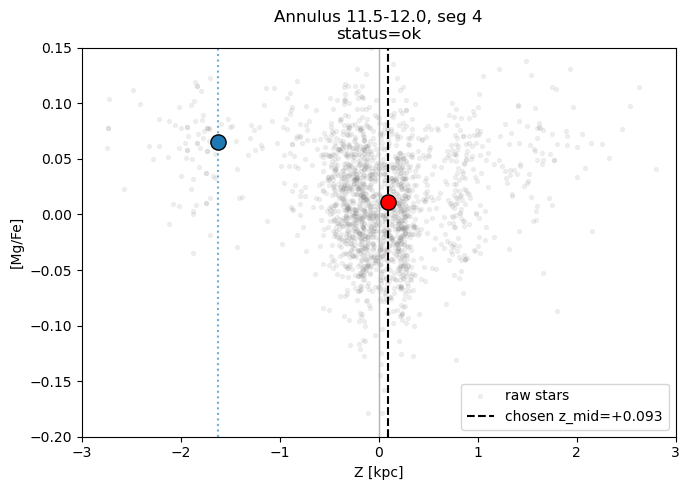

In [134]:
Rmin_focus, Rmax_focus = 11.5, 12.0
seg_id = 4

mR = (R_star >= Rmin_focus) & (R_star < Rmax_focus)
mseg = mR & segm[seg_id]

res = gmm2d.plot_segment(
    Z_star[mseg],
    mgfe_star[mseg],
    title=f"Annulus {Rmin_focus:.1f}-{Rmax_focus:.1f}, seg {seg_id}",
)

In [114]:
df_gmm2d = gmm2d.fit_map_df(
    R_star=R_star,
    Z_star=Z_star,
    mgfe_star=mgfe_star,
    segm=segm,
    seg_plot=SEG_PLOT,
    R_edges=R_edges,
)

print(df_gmm2d["status"].value_counts(dropna=False))
display(df_gmm2d.head())

status
ok                       201
too_broad                 73
too_few_stars             45
no_central_component      40
outside_search_window      1
Name: count, dtype: int64


,Rmin,Rmax,seg,Nseg,z_mid,status
0,0.5,1.0,1,6,NaN,too_few_stars
1,0.5,1.0,2,1,NaN,too_few_stars
2,0.5,1.0,3,4,NaN,too_few_stars
3,0.5,1.0,4,3,NaN,too_few_stars
4,0.5,1.0,5,6,NaN,too_few_stars


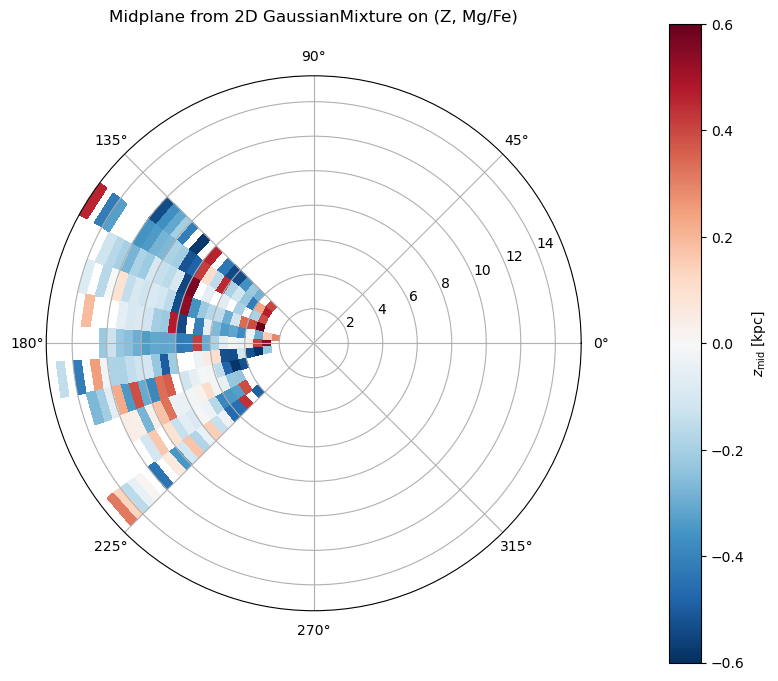

In [115]:
Zmap_gmm2d, theta_edges_gmm2d, R_edges_gmm2d = gmm2d.df_to_polar_map(
    df_gmm2d,
    crowd_bounds=crowd_bounds,
    seg_plot=SEG_PLOT,
    seg_rest_id=SEG_REST_ID if "SEG_REST_ID" in globals() else None,
)

gmm2d.plot_map(
    Zmap_gmm2d,
    theta_edges_gmm2d,
    R_edges_gmm2d,
    title="Midplane from 2D GaussianMixture on (Z, Mg/Fe)",
)

### Poggio Data

In [72]:
import tarfile

tar_path = "J_A+A_699_A199.tar.gz"  
extract_dir = "A199_data"            

Their stars used (finite l,b,d): 17030


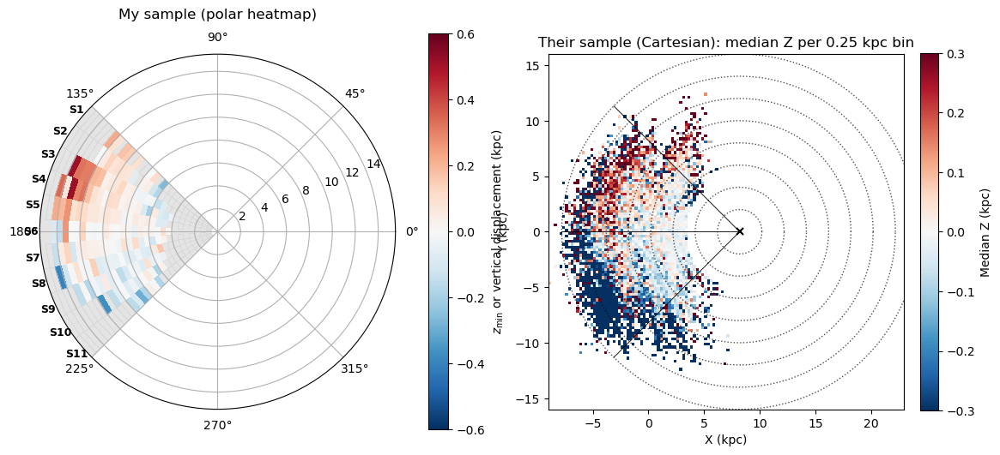

In [73]:
from src.comparison import build_poggio_xy_medianZ_map
from src.plotting import plot_my_polar_vs_their_cartesian

# build their map
poggio_result, poggio_diag = build_poggio_xy_medianZ_map(
    path="A199_data/catalog.dat.gz",
    bin_kpc=0.25,
    min_per_bin=2,
    xy_lim=16.0
)

print("Their stars used (finite l,b,d):", poggio_diag["n_stars_used"])

# compare to my polar map
plot_my_polar_vs_their_cartesian(
    Zmap=Zmap,
    theta_edges=theta_edges,
    R_edges_kept=R_edges_kept,
    zlim=zlim,
    Zmed=poggio_result["Zmed"],
    xedges=poggio_result["xedges"],
    yedges=poggio_result["yedges"],
    bin_kpc=0.25,
    vlim_their=0.30
)

In [74]:
from src.comparison import build_poggio_polar_medianZ_map, build_poggio_xy_medianZ_map
from src.plotting import plot_my_polar_vs_poggio_polar, plot_poggio_cartesian_guides

poggio_polar_result, poggio_polar_diag = build_poggio_polar_medianZ_map(
    path="A199_data/catalog.dat.gz",
    r_edges=R_edges_kept,
    th_edges=theta_edges,
    R0=8.2,
    min_per_bin=5
)

print("Poggio stars used (finite l,b,d):", poggio_polar_diag["n_stars_used"])
print("Poggio polar bins kept:", poggio_polar_diag["n_bins_kept"])

Poggio stars used (finite l,b,d): 17030
Poggio polar bins kept: 237


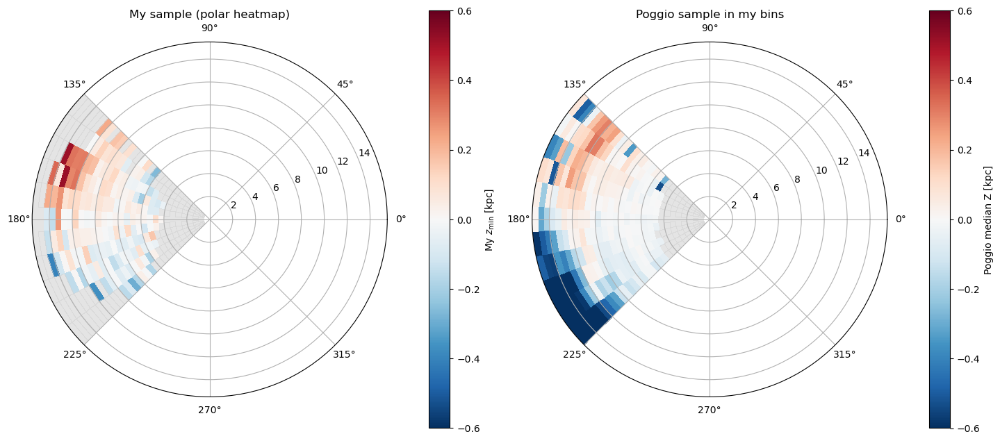

In [75]:
plot_my_polar_vs_poggio_polar(
    Zmap=Zmap,
    theta_edges=theta_edges,
    R_edges_kept=R_edges_kept,
    zlim=zlim,
    Zmed_pog_polar=poggio_polar_result["Zmed_polar"],
    vlim_pog=0.60
)